## IMPORT PACKAGES AND GET THE CURRENT WORKING DIRECTORY

In [1]:
import os
import numpy as np
import scipy.io as sio
import h5py
import pandas as pd
os.getcwd()

'C:\\Users\\msa583\\OneDrive - Vrije Universiteit Amsterdam\\Desktop\\Ambulatory Speech and IE-ratio\\RQ1\\Physiodata\\12008'

## Converting the MAT files of VU-AMS into H5

In [2]:
import os
import numpy as np
import scipy.io as sio
import h5py
import glob
                               #CHANGE THE PARTICIPANT ID IN THE PATH!! (consider later on making this more streamlined)
#set the directory as where the .mat files are for the participant (VUAMS raw data)
directory = r'C:\Users\msa583\OneDrive - Vrije Universiteit Amsterdam\Desktop\Ambulatory Speech and IE-ratio\RQ1\Raw Respiration Extraction\12008'

# pattern to match all relevant .mat files
mat_files = glob.glob(os.path.join(directory, "trimmed_*.mat"))  # glob.glob, within the specified directory, retrieves all files starting with trimmed 
                                                                                    #it uses the wildcard of asteriks
                                                                                    #it makes a list object of the full paths of different trimmed_*.mat

# create a dictionary to store the loaded data (identifiers + their Python object aka array in this case) 
data_dict = {}

for mat_file in mat_files:
    # extract base name without directory
    base_name = os.path.basename(mat_file)                # e.g., "trimmed_MZR_25879.mat"
    name_no_extension = os.path.splitext(base_name)[0]    # "trimmed_MZR_25879"  # getting the name of the variable before .mat. Split breaks into trimmed_MXR and mat
                                                    # and 0 selects the first part of the splitted names
    # strip the participant ID (it's always after the last underscore)
    variable_name = '_'.join(name_no_extension.split('_')[:-1])  # e.g., "trimmed_MZR"
    # load the .mat variable using the scipy package
    mat_data = sio.loadmat(mat_file)
    # make sure it is an array, and make sure to flatten the data to make it 1D
    data = np.array(mat_data[variable_name]).flatten() 
    #save the data to the dictionary with its name as the key  (not using append function as we defined an empty dictionary, not an empty list)
    data_dict[variable_name] = data 
    print(f"{variable_name} loaded from {mat_file}")

# save to HDF5
h5_path = os.path.join(directory, 'combined_VU_data.h5')
with h5py.File(h5_path, 'w') as h5f: #open an h5 file for writing
    for key, data in data_dict.items(): #go through each variable name-its corresponding Numpy array of the pairs in the dictionary
        h5f.create_dataset(key, data=data) #creates the dataset for the current variable name-array in the hdf5 file, specifying the key and data 


trimmed_DZ loaded from C:\Users\msa583\OneDrive - Vrije Universiteit Amsterdam\Desktop\Ambulatory Speech and IE-ratio\RQ1\Raw Respiration Extraction\12008\trimmed_DZ_12008.mat
trimmed_MXR loaded from C:\Users\msa583\OneDrive - Vrije Universiteit Amsterdam\Desktop\Ambulatory Speech and IE-ratio\RQ1\Raw Respiration Extraction\12008\trimmed_MXR_12008.mat
trimmed_MYR loaded from C:\Users\msa583\OneDrive - Vrije Universiteit Amsterdam\Desktop\Ambulatory Speech and IE-ratio\RQ1\Raw Respiration Extraction\12008\trimmed_MYR_12008.mat
trimmed_MZR loaded from C:\Users\msa583\OneDrive - Vrije Universiteit Amsterdam\Desktop\Ambulatory Speech and IE-ratio\RQ1\Raw Respiration Extraction\12008\trimmed_MZR_12008.mat
trimmed_Z0 loaded from C:\Users\msa583\OneDrive - Vrije Universiteit Amsterdam\Desktop\Ambulatory Speech and IE-ratio\RQ1\Raw Respiration Extraction\12008\trimmed_Z0_12008.mat


In [3]:
data_dict

{'trimmed_DZ': array([0.44393545, 0.38290028, 0.32377247, ..., 7.4248323 , 7.46488662,
        7.50398727]),
 'trimmed_MXR': array([-0.85742188, -0.85742188, -0.85839844, ..., -0.27197266,
        -0.27050781, -0.27050781]),
 'trimmed_MYR': array([-0.02490234, -0.02587891, -0.02783203, ...,  0.41943359,
         0.41601562,  0.41601562]),
 'trimmed_MZR': array([ 0.546875  ,  0.54833984,  0.54638672, ..., -0.85742188,
        -0.85644531, -0.85644531]),
 'trimmed_Z0': array([1089.37181419, 1089.28169196, 1089.15962163, ..., 1019.52088404,
        1019.35303734, 1018.84663621])}

In [4]:
acc_z_vuams = data_dict["trimmed_MZR"]
acc_y_vuams = data_dict["trimmed_MYR"]
acc_x_vuams = data_dict["trimmed_MXR"]
resp_vuams = data_dict["trimmed_Z0"]
#resp_sfiltered_vuams = data_dict["trimmed_DZ"] #this won't be used later as it is a version of Z0 already filtered by VU-DAMS, we will start from the real raw signal

In [5]:
print(len(acc_z_vuams))
print(len(acc_y_vuams))
print(len(acc_x_vuams))
print(len(resp_vuams))

64837453
64837453
64837453
64837453


In [6]:
acc_x_vuams #an array

array([-0.85742188, -0.85742188, -0.85839844, ..., -0.27197266,
       -0.27050781, -0.27050781])

## READING IN THE EDF OF HEXOSKIN

In [7]:
#pip install pyEDFlib
from pyedflib import highlevel
import pyedflib as plib
import numpy as np
import matplotlib.pyplot as plt
#Note that the Hexoskin raw file in edf format should be located in the same place as the .mat files as it calls it from the same directory
ppid = 12008 #write the participant id here!!

edf_file = f"record_{ppid}.edf"
edf_path = os.path.join(directory, edf_file) #the full path for the edf
signals, signal_headers, header = highlevel.read_edf(edf_path) #using the highlevel.read_edf function to read the data

In [8]:
signals #the actual numerical data, one 1D numpy array per signal channel - the whole variable is a list object

[array([10.33603638, 17.47203127, 17.48483127, ..., -8.70395   ,
        -8.70395   , -8.70395   ]),
 array([ 0., 70., 70., ..., 88., 88., 88.]),
 array([ 0., 10., 10., ..., 19., 19., 19.]),
 array([0., 0., 0., ..., 0., 0., 0.]),
 array([0., 0., 0., ..., 0., 0., 0.]),
 array([-1.00007629e-05, -1.00007629e-05, -1.00007629e-05, ...,
         1.23636686e+01,  1.23636686e+01,  1.23636686e+01]),
 array([-1.00007629e-05, -1.00007629e-05, -1.00007629e-05, ...,
         6.10869929e-01,  6.10869929e-01,  6.10869929e-01]),
 array([ 0.  ,  0.  ,  0.  , ..., 12.36, 12.36, 12.36]),
 array([3.63797881e-15, 3.63797881e-15, 3.63797881e-15, ...,
        6.10000000e-01, 6.10000000e-01, 6.10000000e-01]),
 array([  0.,  71.,  71., ..., 186., 186., 186.]),
 array([-4.68757153e-05, -4.68757153e-05, -4.68757153e-05, ...,
         3.51093614e-02,  3.90156100e-02,  2.10890547e-01]),
 array([-1.17234333e-01, -1.36765576e-01, -1.21140581e-01, ...,
        -4.68757153e-05, -4.68757153e-05, -4.68757153e-05]),
 arr

In [9]:
signal_headers #matching list of dictionaries describing each channel

[{'label': '4113:ECG_I',
  'dimension': 'mV',
  'sample_frequency': 256.0,
  'physical_max': 201.0047,
  'physical_min': -218.419,
  'digital_max': 32767,
  'digital_min': -32768,
  'prefilter': '',
  'transducer': ''},
 {'label': '19:heart_rate',
  'dimension': 'bpm',
  'sample_frequency': 1.0,
  'physical_max': 32767.0,
  'physical_min': -32768.0,
  'digital_max': 32767,
  'digital_min': -32768,
  'prefilter': '',
  'transducer': ''},
 {'label': '33:breathing_rat',
  'dimension': 'rpm',
  'sample_frequency': 1.0,
  'physical_max': 32767.0,
  'physical_min': -32768.0,
  'digital_max': 32767,
  'digital_min': -32768,
  'prefilter': '',
  'transducer': ''},
 {'label': '4129:resp_thorac',
  'dimension': 'NA',
  'sample_frequency': 128.0,
  'physical_max': 32767.0,
  'physical_min': -32768.0,
  'digital_max': 32767,
  'digital_min': -32768,
  'prefilter': '',
  'transducer': ''},
 {'label': '4130:resp_abdomi',
  'dimension': 'NA',
  'sample_frequency': 128.0,
  'physical_max': 32767.0,
  

In [10]:
header

{'technician': '',
 'recording_additional': 'hexoskin_record_id=295718',
 'patientname': 'Melisa Saygin',
 'patient_additional': 'hexoskin_user_id=22599',
 'patientcode': '',
 'equipment': '',
 'admincode': '',
 'sex': '',
 'startdate': datetime.datetime(2024, 9, 2, 8, 35, 46),
 'birthdate': '12 oct 1999',
 'gender': '',
 'annotations': []}

In [11]:
signals[3]

array([0., 0., 0., ..., 0., 0., 0.])

In [12]:
#signals[3] is the raw thoracic respiration signal
#signal[4] is the raw abdominal respiration signal
#signal[11] is the raw accelerometer signal in X-axis
#signal[12] is the raw accelerometer signal in Y-axis
#signal[13] is the raw accelerometer signal in Z-axis

signal_headers[3]

{'label': '4129:resp_thorac',
 'dimension': 'NA',
 'sample_frequency': 128.0,
 'physical_max': 32767.0,
 'physical_min': -32768.0,
 'digital_max': 32767,
 'digital_min': -32768,
 'prefilter': '',
 'transducer': ''}

In [13]:
acc_x_hexoskin = signals[11]
acc_y_hexoskin = signals[12]
acc_z_hexoskin = signals[13]
resp_hexoskin_thorax = -signals[3] #multiplying with -1 so that there is an increase in signal during inhalation
resp_hexoskin_abdomen = -signals[4] #multiplying with -1 so that there is an increase in signal during inhalation

In [14]:
print(len(acc_x_hexoskin))
print(len(acc_y_hexoskin))
print(len(acc_z_hexoskin))
print(len(resp_hexoskin_thorax))
print(len(resp_hexoskin_abdomen))

2323136
2323136
2323136
4646272
4646272


In [15]:
# let's first visualize the raw signals, which we will follow by filtering the accelerometer signals and visualizing them

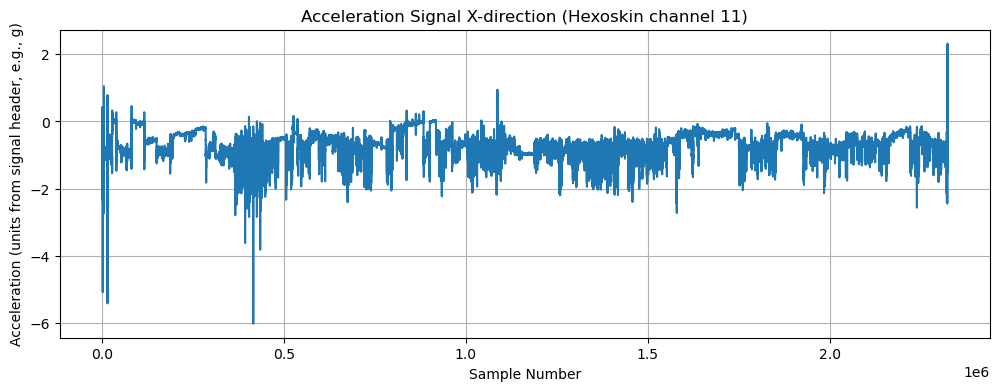

In [16]:
import matplotlib.pyplot as plt
# visualizing acc_x_hexoskin
plt.figure(figsize=(12, 4))
plt.plot(acc_x_hexoskin)
plt.title("Acceleration Signal X-direction (Hexoskin channel 11)")
plt.xlabel("Sample Number")
plt.ylabel("Acceleration (units from signal header, e.g., g)")
plt.grid(True)
plt.show()

In [17]:
len(resp_hexoskin_thorax)

4646272

In [18]:
len(resp_hexoskin_abdomen) #sanity check to see if the thorax and abdomen have the same number of samples

4646272

In [19]:
len(resp_hexoskin_thorax)/len(acc_x_hexoskin) #sanity check to see if the acc of hexoskin has half the number of samples of the resp by hexoskin

2.0

## SETTING THE DATETIME INDEXES FOR BOTH HEXOSKIN AND VUAMS

In [ ]:
acc_x_hexoskin

In [20]:
import pandas as pd

# manually enter the start times for the Hexoskin and VUAMS recordings
start_hexoskin = pd.to_datetime("2024-09-02 10:35:46")
start_vuams = pd.to_datetime("2024-09-02 10:29:53.500") #entering the CORRECT time here - the VUDAMS registered (incorrect by one hour) time 
                                               #was 09:29:53.500 for day1 

# sampling rates
fs_hexoskin_acc = 64
fs_hexoskin_resp = 128
fs_vuams_acc = 1000
fs_vuams_resp = 1000

#arrays cannot know what time it is! let's convert to series with a datetime index
# defining Hexoskin data as series (like a column of a table) with datetime index (was previously just arrays without datetime index)
#Hexoskin accelerometer signals
acc_x_hexoskin = pd.Series(
    acc_x_hexoskin,
    index=start_hexoskin + pd.to_timedelta(pd.RangeIndex(len(acc_x_hexoskin)) / fs_hexoskin_acc, unit='s')
)
acc_y_hexoskin = pd.Series(
    acc_y_hexoskin,
    index=start_hexoskin + pd.to_timedelta(pd.RangeIndex(len(acc_y_hexoskin)) / fs_hexoskin_acc, unit='s')
)
acc_z_hexoskin = pd.Series(
    acc_z_hexoskin,
    index=start_hexoskin + pd.to_timedelta(pd.RangeIndex(len(acc_z_hexoskin)) / fs_hexoskin_acc, unit='s')
)
#Hexoskin respiration signals
resp_hexoskin_thorax = pd.Series(
    resp_hexoskin_thorax,
    index=start_hexoskin + pd.to_timedelta(pd.RangeIndex(len(resp_hexoskin_thorax)) / fs_hexoskin_resp, unit='s')
)
resp_hexoskin_abdomen = pd.Series(
    resp_hexoskin_abdomen,
    index=start_hexoskin + pd.to_timedelta(pd.RangeIndex(len(resp_hexoskin_abdomen)) / fs_hexoskin_resp, unit='s')
)

#  defining VUAMS data as series (like a column of a table) with datetime index (was previously just arrays without datetime index)
#VUAMS accelerometer signals
acc_x_vuams = pd.Series(
    acc_x_vuams,
    index=start_vuams + pd.to_timedelta(pd.RangeIndex(len(acc_x_vuams)) / fs_vuams_acc, unit='s')
)
acc_y_vuams = pd.Series(
    acc_y_vuams,
    index=start_vuams + pd.to_timedelta(pd.RangeIndex(len(acc_y_vuams)) / fs_vuams_acc, unit='s')
)
acc_z_vuams = pd.Series(
    acc_z_vuams,
    index=start_vuams + pd.to_timedelta(pd.RangeIndex(len(acc_z_vuams)) / fs_vuams_acc, unit='s')
)

# VUAMS respiration signal
resp_vuams = pd.Series(
    resp_vuams,
    index=start_vuams + pd.to_timedelta(pd.RangeIndex(len(resp_vuams)) / fs_vuams_resp, unit='s')
)


In [21]:
print(acc_x_hexoskin)

2024-09-02 10:35:46.000000   -0.117234
2024-09-02 10:35:46.015625   -0.136766
2024-09-02 10:35:46.031250   -0.121141
2024-09-02 10:35:46.046875   -0.097703
2024-09-02 10:35:46.062500   -0.066453
                                ...   
2024-09-02 20:40:44.921875   -0.000047
2024-09-02 20:40:44.937500   -0.000047
2024-09-02 20:40:44.953125   -0.000047
2024-09-02 20:40:44.968750   -0.000047
2024-09-02 20:40:44.984375   -0.000047
Length: 2323136, dtype: float64


In [22]:
print(acc_x_vuams)

2024-09-02 10:29:53.500   -0.857422
2024-09-02 10:29:53.501   -0.857422
2024-09-02 10:29:53.502   -0.858398
2024-09-02 10:29:53.503   -0.856934
2024-09-02 10:29:53.504   -0.857422
                             ...   
2024-09-03 04:30:30.948   -0.272949
2024-09-03 04:30:30.949   -0.269531
2024-09-03 04:30:30.950   -0.271973
2024-09-03 04:30:30.951   -0.270508
2024-09-03 04:30:30.952   -0.270508
Length: 64837453, dtype: float64


In [23]:
print(acc_z_vuams)

2024-09-02 10:29:53.500    0.546875
2024-09-02 10:29:53.501    0.548340
2024-09-02 10:29:53.502    0.546387
2024-09-02 10:29:53.503    0.549805
2024-09-02 10:29:53.504    0.552246
                             ...   
2024-09-03 04:30:30.948   -0.854980
2024-09-03 04:30:30.949   -0.854980
2024-09-03 04:30:30.950   -0.857422
2024-09-03 04:30:30.951   -0.856445
2024-09-03 04:30:30.952   -0.856445
Length: 64837453, dtype: float64


In [24]:
# defining the end times of each device's signals
end_hexoskin = start_hexoskin + pd.to_timedelta(len(acc_x_hexoskin) / fs_hexoskin_acc, unit='s')
end_vuams = start_vuams + pd.to_timedelta(len(acc_x_vuams) / fs_vuams_acc, unit='s')

# define the start and end times for the time the device recordings are overlapping (i.e., both recording)
common_start = max(start_hexoskin, start_vuams)
common_end = min(end_hexoskin, end_vuams)

print("Common start:", common_start)
print("Common end:", common_end)

Common start: 2024-09-02 10:35:46
Common end: 2024-09-02 20:40:45


In [ ]:
#the below does not apply to participant 37818
#this specific participant did not remove the Hexoskin at the end of day1, so we need to manually (via visualization) determine the end time
#let's plot the thoracic respiration signal
#import matplotlib.pyplot as plt

#plt.figure(figsize=(15, 4))
#plt.plot(resp_hexoskin_thorax.index, resp_hexoskin_thorax.values)
#plt.xlabel("Time")
#plt.ylabel("Respiration (Thorax)")
#plt.title("Hexoskin Thorax Respiration Signal")
#plt.tight_layout()
#plt.show()

#they removed around after 22:00

In [ ]:
#common_end = pd.to_datetime("2024-05-01 22:45:00")
#print("Common end:", common_end)

In [25]:
# limit all signals to this common time period for the participant, as they were wearing both the Hexoskin and the VUAMS
acc_x_hexoskin = acc_x_hexoskin[common_start:common_end]
acc_y_hexoskin = acc_y_hexoskin[common_start:common_end]
acc_z_hexoskin = acc_z_hexoskin[common_start:common_end]
resp_hexoskin_thorax = resp_hexoskin_thorax[common_start:common_end]
resp_hexoskin_abdomen = resp_hexoskin_abdomen[common_start:common_end]

acc_x_vuams = acc_x_vuams[common_start:common_end]
acc_y_vuams = acc_y_vuams[common_start:common_end]
acc_z_vuams = acc_z_vuams[common_start:common_end]
resp_vuams = resp_vuams[common_start:common_end]

In [26]:
print(acc_x_hexoskin)

2024-09-02 10:35:46.000000   -0.117234
2024-09-02 10:35:46.015625   -0.136766
2024-09-02 10:35:46.031250   -0.121141
2024-09-02 10:35:46.046875   -0.097703
2024-09-02 10:35:46.062500   -0.066453
                                ...   
2024-09-02 20:40:44.921875   -0.000047
2024-09-02 20:40:44.937500   -0.000047
2024-09-02 20:40:44.953125   -0.000047
2024-09-02 20:40:44.968750   -0.000047
2024-09-02 20:40:44.984375   -0.000047
Length: 2323136, dtype: float64


In [27]:
print(acc_x_vuams)

2024-09-02 10:35:46.000   -0.844238
2024-09-02 10:35:46.001   -0.845215
2024-09-02 10:35:46.002   -0.841797
2024-09-02 10:35:46.003   -0.842773
2024-09-02 10:35:46.004   -0.844238
                             ...   
2024-09-02 20:40:44.996   -0.854980
2024-09-02 20:40:44.997   -0.855957
2024-09-02 20:40:44.998   -0.855957
2024-09-02 20:40:44.999   -0.855957
2024-09-02 20:40:45.000   -0.855469
Length: 36299001, dtype: float64


In [28]:
acc_x_vuams

2024-09-02 10:35:46.000   -0.844238
2024-09-02 10:35:46.001   -0.845215
2024-09-02 10:35:46.002   -0.841797
2024-09-02 10:35:46.003   -0.842773
2024-09-02 10:35:46.004   -0.844238
                             ...   
2024-09-02 20:40:44.996   -0.854980
2024-09-02 20:40:44.997   -0.855957
2024-09-02 20:40:44.998   -0.855957
2024-09-02 20:40:44.999   -0.855957
2024-09-02 20:40:45.000   -0.855469
Length: 36299001, dtype: float64

In [29]:
#we first will filter and then downsample the acc x signal of VU-AMS (note this is for visual inspection to sync between the devices)
#this is a simple filter to just keep physical movement related changes in the signal
from scipy import signal
import numpy as np
import pandas as pd

# filter characteristics
order = 2
cutoffFreq = 5  # Hz

# define the lowpass Butterworth filter
def lowpass_filter(data, fs, cutoff, order):
    criticalFreq = cutoff / (fs / 2)  # cutoff frequency divided by Nyquist
    b, a = signal.butter(order, criticalFreq, btype='low') # first, appropriately define the butter filter
    return signal.filtfilt(b, a, data) #then, insert into the filtfilt function. this function filters backwards and forwards to avoid having a shift

# original sampling rates (also specified in a preous cell, but repeating here)
fs_hexoskin_acc = 64
fs_vuams_acc = 1000

#we must first filter and only then resample: otherwise one runs into aliasing problems
# filtering both signals at their original sampling rates
acc_x_vuams_filt = lowpass_filter(acc_x_vuams, fs_vuams_acc, cutoffFreq, order)
acc_x_hexoskin_filt = lowpass_filter(acc_x_hexoskin, fs_hexoskin_acc, cutoffFreq, order)

print(acc_x_vuams_filt)
print(acc_x_hexoskin_filt)

[-0.84405211 -0.84407203 -0.84409159 ... -0.86402443 -0.86401767
 -0.86401199]
[-0.11760312 -0.10908892 -0.09980311 ... -0.0003416  -0.00064875
 -0.00069573]


In [30]:
# now, can downsample VUAMS accelerometer signal so it has the same sampling rate as Hexoskin
#we will use the scipy package to achieve so (note that we use the resample function instead of decimate, as decimate requires the factor to be an integer)
from scipy.signal import resample
n_samples_acc_x_hexoskin = len(acc_x_hexoskin_filt) #check how many samples there are in the hexoskin signal (both signals already had the same duration)
                                     #the resample function will resample such that the vuams acc signal ends up having the same number of samples of hexoskin acc 
acc_x_vuams_downsampled = resample(acc_x_vuams_filt, n_samples_acc_x_hexoskin)
print(acc_x_vuams_downsampled)

[-0.85342913 -0.8425294  -0.84539343 ... -0.86602021 -0.86377294
 -0.86599041]


In [31]:
print(len(acc_x_vuams_downsampled))
print(len(acc_x_hexoskin_filt))

2323136
2323136


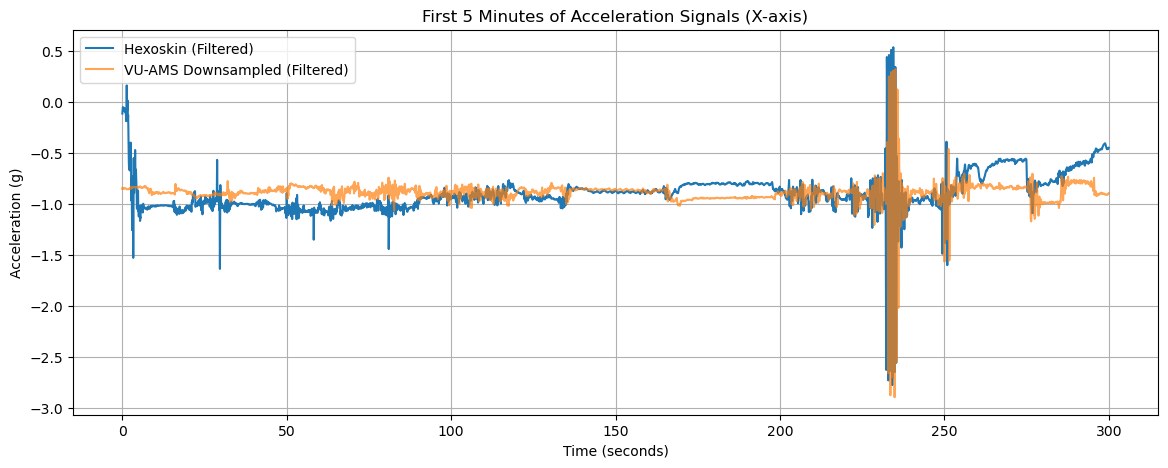

In [32]:
# let's plot the first 5 minutes of both these signals (they already have the same number of samples and are filtered)
# the purpose is see the jumps in the procedure clearly in both of the accelerometer signals to get an indication of the sync
import matplotlib.pyplot as plt

# sampling rate after downsampling (both acc_x now 64 Hz)
fs = 64

# the number of samples in 5 minutes  (note: if you have to visualize more minutes, you can alter this, though the variable name will still suggest 5 mins)
samples_5min = 5 * 60 * fs  

# slicing the first 5 minutes
hexoskin_5min = acc_x_hexoskin_filt[0:samples_5min]
vuams_5min = acc_x_vuams_downsampled[0:samples_5min]

# creating a time vector for the x-axis
time = np.arange(samples_5min) / fs    #arange function creates an array starting at 0, 1, 2...

# plotting
plt.figure(figsize=(14, 5))
plt.plot(time, hexoskin_5min, label='Hexoskin (Filtered)')
plt.plot(time, vuams_5min, label='VU-AMS Downsampled (Filtered)', alpha=0.7)
plt.title('First 5 Minutes of Acceleration Signals (X-axis)')
plt.xlabel('Time (seconds)')
plt.ylabel('Acceleration (g)')
plt.legend()
plt.grid(True)
plt.show()


For participant 12008, we can see that the signals are basically at the same time, probably will just require a shift of at most several seconds.
To determine the precise shift for the Hexoskin signals, let's continue with the cross-correlation below.

y2 has a -1.242188034702849 s lag, taking y1 as a reference


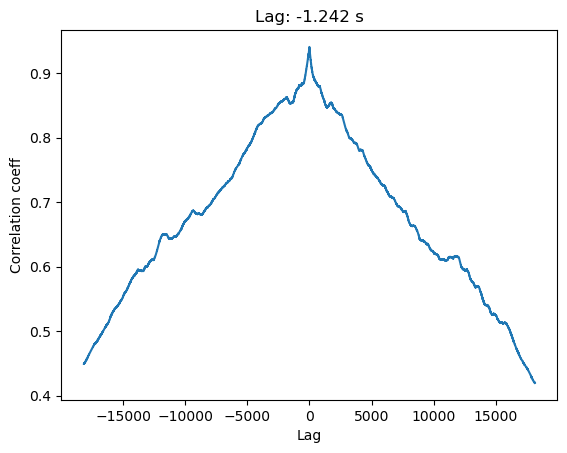

In [33]:
#THIS FINDS THE LAG (IN SECONDS) AT WHICH THE X-AXIS ACCELEROMETER SIGNALS OF BOTH DEVICES CROSS-CORRELATE THE HIGHEST

import matplotlib.pyplot as plt
from scipy import signal
import numpy as np

def lag_finder(y1, y2, sr):
    n = len(y1) #the length of the signal of y1
    #below, we compute the cross-correlation between the two signals and normalize by the square root of the indiviual signals' autocorrelation
    #in the denominator, we multiply the autocorrelation of each signal (with itself) at zero lag which is basically the total signal power (sum of squared values)
    #the multiplication of the total signal power of the two signals and taking the square root corresponds to the geometric mean of the two signals - the int(n/2) picks the value at zero lag
    corr = signal.correlate(y2, y1, mode='same') / np.sqrt(signal.correlate(y1, y1, mode='same')[int(n/2)] * signal.correlate(y2, y2, mode='same')[int(n/2)])

    delay_arr = np.linspace(-0.5*n/sr, 0.5*n/sr, n) #lags from negative half the signal length to positive half the signal length (in second), each index in corr corresponds to a lag in delay_arr
    delay = delay_arr[np.argmax(corr)] #find the index of the maximum point of cross-correlation, and use delay_arr to convert to seconds
    print('y2 has a ' + str(delay) + ' s lag, taking y1 as a reference')

    plt.figure()
    plt.plot(delay_arr, corr)
    plt.title('Lag: ' + str(np.round(delay, 3)) + ' s')
    plt.xlabel('Lag')
    plt.ylabel('Correlation coeff')
    plt.show()

sr = 64 
y1 = acc_x_vuams_downsampled
y2 = acc_x_hexoskin_filt

lag_finder(y1, y2, sr)

#FOR EX. "y2 has a -1.58 s lag" means y2 happens before/earlier than y1 by 1.58 s. So you would need to shift y2 to the right by the number of samples equivalent to 1.58 seconds.

#Positive lag (delay > 0): y2 is delayed (happens later) compared to y1 by delay seconds.
#To align them, shift y2 earlier in time by delay seconds (shift left - implement the lag in the negative direction).

#Negative lag (delay < 0): y2 happens earlier/first than y1 by |delay| seconds.
#To align them, shift y2 later in time by |delay| seconds (shift right - implement the lag in the positive direction).


## REPEAT THE CROSS CORRELATION STEPS FOR THE ACCELERATION SIGNALS IN THE Y AXIS (can skip if you got the cross-correlation already using the X-axis code)

In [ ]:

from scipy import signal
import numpy as np

# --- Filter characteristics ---
order = 2
cutoffFreq = 5  # Hz

# Low-pass Butterworth filter
def lowpass_filter(data, fs, cutoff, order):
    criticalFreq = cutoff / (fs / 2)  # cutoff frequency divided by Nyquist
    b, a = signal.butter(order, criticalFreq, btype='low')
    return signal.filtfilt(b, a, data)

# Original sampling rate of VUAMS (e.g., 1000 Hz)
fs_vuams = 1000  # change this to the real value
fs_hexoskin = 64

# --- 1. Filter both signals at their native sampling rates ---
acc_y_vuams_filt = lowpass_filter(acc_y_vuams, fs_vuams, cutoffFreq, order)
acc_y_hexoskin_filt = lowpass_filter(acc_y_hexoskin, fs_hexoskin, cutoffFreq, order)

# --- 2. Downsample VUAMS to match Hexoskin ---
target_freq_hz = 64
period_ms = 1000 / target_freq_hz  # e.g., 15.625 ms

# Create pandas series if not already
import pandas as pd
acc_y_vuams_filt_series = pd.Series(acc_y_vuams_filt, index=acc_y_vuams.index)

# Downsample by mean over target period
acc_y_vuams_downsampled = acc_y_vuams_filt_series.resample(f'{period_ms}L').mean()

# Reindex to match Hexoskin timestamps
acc_y_vuams_downsampled = acc_y_vuams_downsampled.reindex(acc_y_hexoskin.index, method='nearest')

# Convert to NumPy arrays
acc_y_vuams_downsampled = np.array(acc_y_vuams_downsampled)
acc_y_hexoskin_filt = np.array(acc_y_hexoskin_filt)

print(acc_y_vuams_downsampled.shape, acc_y_hexoskin_filt.shape)

In [ ]:
#let's plot the first 5 minutes of both these signals (they already have the same number of samples and are filtered)
#purpose is to try if we can see the jumps clearly in both of the accelerometer signals
import matplotlib.pyplot as plt

# Sampling rate after downsampling (both now 64 Hz)
fs = 64

# Calculate number of samples in 5 minutes
samples_5min = 5 * 60 * fs  # 5 minutes * 60 sec * fs

# Slice first 5 minutes
hexoskin_5min = acc_y_hexoskin_filt[:samples_5min]
vuams_5min = acc_y_vuams_downsampled[:samples_5min]

# Create time vector in seconds for x-axis
time = np.arange(samples_5min) / fs

# Plot
plt.figure(figsize=(14, 5))
plt.plot(time, hexoskin_5min, label='Hexoskin (Filtered)')
plt.plot(time, vuams_5min, label='VU-AMS Downsampled (Filtered)', alpha=0.7)
plt.title('First 5 Minutes of Acceleration Signal (y-axis)')
plt.xlabel('Time (seconds)')
plt.ylabel('Acceleration (units)')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
#this unexpected cross correlation could be the result of the z acceleration at near-larynx being different than that in abdomen
#try with an acceleration signal from VUAMS using MYR or MXR 

import matplotlib.pyplot as plt
from scipy import signal
import numpy as np


def lag_finder(y1, y2, sr):
    n = len(y1)

    corr = signal.correlate(y2, y1, mode='same') / np.sqrt(signal.correlate(y1, y1, mode='same')[int(n/2)] * signal.correlate(y2, y2, mode='same')[int(n/2)])

    delay_arr = np.linspace(-0.5*n/sr, 0.5*n/sr, n)
    delay = delay_arr[np.argmax(corr)]
    print('y2 is ' + str(delay) + ' behind y1')

    plt.figure()
    plt.plot(delay_arr, corr)
    plt.title('Lag: ' + str(np.round(delay, 3)) + ' s')
    plt.xlabel('Lag')
    plt.ylabel('Correlation coeff')
    plt.show()

# Sine sample with some noise and copy to y1 and y2 with a 1-second lag
sr = 64 
y1 = acc_y_hexoskin_filt
y2 = acc_y_vuams_downsampled

lag_finder(y1, y2, sr)

## FILTER, THEN DOWNSAMPLE FOR RESPIRATION SIGNALS

In [34]:
from scipy import signal
import numpy as np
import pandas as pd

#we will first apply a bandpass filter (.1 to .7 Hz) to all three respiration signals: hexoskin thorax, hexoskin abdomen, vuams 
order = 2
low_cutoff = 0.1  # Hz   #IMPORTANT: Prior to opening this script, if you changed these thresholds in PhysioData Toolbox to facilitate
                          #correct peak-valey detection for a given participant, you should also change the thresholds here for this pt
high_cutoff = 0.7  # Hz

# band-pass Butterworth filter
def bandpass_filter(data, fs, lowcut, highcut, order):
    nyq = fs / 2  #nyquist frequency
    low = lowcut / nyq #normalize lowpass
    high = highcut / nyq  #normalize highpass
    b, a = signal.butter(order, [low, high], btype='band')
    return signal.filtfilt(b, a, data) #using filtfilt to apply the filter backwards and forwards so there is no phase shift

# sampling rates
fs_vuams_resp = 1000  # original VU-AMS respiration
fs_hexoskin_resp = 128  # Hexoskin thorax & abdomen

print(len(resp_hexoskin_thorax))

# filtering all respiration signals at their original sampling rates
resp_vuams_filt = bandpass_filter(resp_vuams, fs_vuams_resp, low_cutoff, high_cutoff, order)
resp_hexoskin_thorax_filt = bandpass_filter(resp_hexoskin_thorax, fs_hexoskin_resp, low_cutoff, high_cutoff, order)
resp_hexoskin_abdomen_filt = bandpass_filter(resp_hexoskin_abdomen, fs_hexoskin_resp, low_cutoff, high_cutoff, order) #all these return a 1D numpy array

print(len(resp_hexoskin_thorax_filt))

# downsample VU-AMS respiration to match Hexoskin's 128 Hz
from scipy.signal import resample
n_samples_resp_hexoskin_thorax = len(resp_hexoskin_thorax_filt) #check how many samples there are in the hexoskin signal (both signals already have the same duration)
                                     #the resample function will resample such that the vuams acc signal ends up having the same number of samples of hexoskin acc 
resp_vuams_downsampled = resample(resp_vuams_filt, n_samples_resp_hexoskin_thorax)

print(resp_vuams_downsampled.shape,
      resp_hexoskin_thorax_filt.shape,
      resp_hexoskin_abdomen_filt.shape)

4646272
4646272
(4646272,) (4646272,) (4646272,)


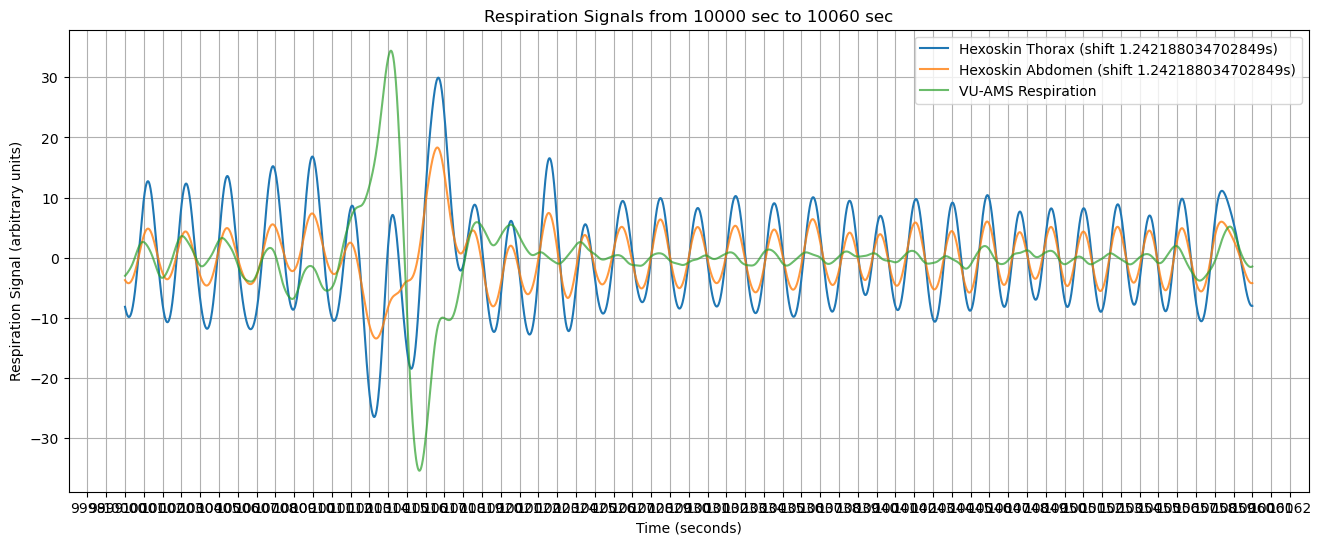

In [46]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import MultipleLocator

def plot_respiration_segment_shift_hexoskin(thorax_signal, abdomen_signal, vuams_signal, fs, start_sec, end_sec, hexoskin_shift_sec=0):
    """
    Plots respiration signals for a given time segment, with a time shift option (for visualization) for Hexoskin signals.

    Positive hexoskin_shift_sec -> shift both Hexoskin respiration signals later (to the right).
    Negative hexoskin_shift_sec -> shift both Hexoskin respiration signals earlier (to the left).
    """
    start_sample = int(start_sec * fs) #the sample at which the visualization starts
    end_sample = int(end_sec * fs) #the sample at which the visualization ends
    
    time = np.arange(start_sample, end_sample) / fs  #the time array (converting the start and end sample to seconds)

    # calculate shift in samples (seconds to samples)
    hexoskin_shift_samples = int(hexoskin_shift_sec * fs)

    # apply the shift to Hexoskin signals (abdomen and thorax respiration)
    thorax_seg = thorax_signal[start_sample - hexoskin_shift_samples : end_sample - hexoskin_shift_samples]
    abdomen_seg = abdomen_signal[start_sample - hexoskin_shift_samples : end_sample - hexoskin_shift_samples]

    # VU-AMS should stay stable
    vuams_seg = vuams_signal[start_sample:end_sample]

    plt.figure(figsize=(16, 6))
    #plot the shifted hexoskin thorax signal
    plt.plot(time, thorax_seg, label=f'Hexoskin Thorax (shift {hexoskin_shift_sec}s)')
    #plot the shifted hexoskin abdomen signal
    plt.plot(time, abdomen_seg, label=f'Hexoskin Abdomen (shift {hexoskin_shift_sec}s)', alpha=0.8)
    #plot the unshifted VUAMS respiration signal
    plt.plot(time, vuams_seg, label='VU-AMS Respiration', alpha=0.7)

    plt.xlabel('Time (seconds)')
    plt.ylabel('Respiration Signal (arbitrary units)')
    plt.title(f'Respiration Signals from {start_sec} sec to {end_sec} sec')
    plt.legend()
    plt.grid(True)
    plt.gca().xaxis.set_major_locator(MultipleLocator(1))  # one tick every 1 second

    plt.show()

fs_resp = 128  # sampling rate for all respiration signals (we already downsampled the VUAMS respiration in a previous cell)
plot_respiration_segment_shift_hexoskin(
    resp_hexoskin_thorax_filt,
    resp_hexoskin_abdomen_filt,
    resp_vuams_downsampled,
    fs_resp,
    10000, #start second
    10060, #end second    try visualizing about a 30-60 sec interval
    hexoskin_shift_sec= +1.242188034702849   # - values shifts Hexoskin signals backward in time (to the left), + values shifts Hexoskin signals forward in time (to the right)
)  #here apply the shift found with the cross-correlation and visualization of the accelerometer signals, and double-check all looks okay/synced
   #check different time points (at the beginning, middle end of the recording)

#for participant 12008
#1200 to 1260 - synced
#5860 to 5920 - synced-ish because the vuams signal is to the right of the hexoskin signals
#10000 to 10060 - clearly synced - just note that there are the occasional spikes in not just hexoskin thorax (at a larger scale) but also with vuams
#12800 to 12860 (3.5 hours into the recording) - 
#14000 to 14060 - (3.89 hours into the recording) - cannot tell as there are extreme spikes in hexoskin thorax - these must be eliminated in physiodatatoolbox
#18030 to 18050 (5 hours into the recording) -  looks synced but the vuams breth waves do not always have similar morphology as the hexoskin ones
#27060 to 27090 (7.5 hours into the recording) - 
#27500 o 27560 - looks clearly synced at a portion


In [47]:
resp_vuams_downsampled

array([-3.03280658, -5.86996839, -5.16104883, ...,  0.17355562,
       -0.25839703,  0.47341038])

In [48]:
resp_hexoskin_thorax_filt

array([  -2.95812289, -490.18825739, -976.98243359, ...,    6.6961805 ,
          5.61547845,    4.6542061 ])

In [49]:
common_start

Timestamp('2024-09-02 10:35:46')

In [50]:
#create the datetime index for VUAMS
vuams_index = common_start + pd.to_timedelta(np.arange(len(resp_vuams_downsampled)) / 128, unit='s')
vuams_index

DatetimeIndex([          '2024-09-02 10:35:46',
               '2024-09-02 10:35:46.007812500',
                  '2024-09-02 10:35:46.015625',
               '2024-09-02 10:35:46.023437500',
                  '2024-09-02 10:35:46.031250',
               '2024-09-02 10:35:46.039062500',
                  '2024-09-02 10:35:46.046875',
               '2024-09-02 10:35:46.054687500',
                  '2024-09-02 10:35:46.062500',
               '2024-09-02 10:35:46.070312500',
               ...
                  '2024-09-02 20:40:44.921875',
               '2024-09-02 20:40:44.929687500',
                  '2024-09-02 20:40:44.937500',
               '2024-09-02 20:40:44.945312500',
                  '2024-09-02 20:40:44.953125',
               '2024-09-02 20:40:44.960937500',
                  '2024-09-02 20:40:44.968750',
               '2024-09-02 20:40:44.976562500',
                  '2024-09-02 20:40:44.984375',
               '2024-09-02 20:40:44.992187500'],
              dtype=

In [51]:
#convert the vuams array into pd.Series
resp_vuams_downsampled = pd.Series(resp_vuams_downsampled, index = vuams_index)
resp_vuams_downsampled

2024-09-02 10:35:46.000000000   -3.032807
2024-09-02 10:35:46.007812500   -5.869968
2024-09-02 10:35:46.015625000   -5.161049
2024-09-02 10:35:46.023437500   -5.612506
2024-09-02 10:35:46.031250000   -5.320718
                                   ...   
2024-09-02 20:40:44.960937500    0.101223
2024-09-02 20:40:44.968750000   -0.135974
2024-09-02 20:40:44.976562500    0.173556
2024-09-02 20:40:44.984375000   -0.258397
2024-09-02 20:40:44.992187500    0.473410
Length: 4646272, dtype: float64

In [52]:
#create the datetime index for Hexoskin, starting by defining a variable for the shift in seconds
shift = +1.242188034702849
hexoskin_index = common_start + pd.to_timedelta(
    (np.arange(len(resp_hexoskin_thorax_filt)) / 128) + shift,
    unit='s'
)
hexoskin_index

DatetimeIndex(['2024-09-02 10:35:47.242188035',
               '2024-09-02 10:35:47.250000535',
               '2024-09-02 10:35:47.257813035',
               '2024-09-02 10:35:47.265625535',
               '2024-09-02 10:35:47.273438035',
               '2024-09-02 10:35:47.281250535',
               '2024-09-02 10:35:47.289063035',
               '2024-09-02 10:35:47.296875535',
               '2024-09-02 10:35:47.304688035',
               '2024-09-02 10:35:47.312500535',
               ...
               '2024-09-02 20:40:46.164063035',
               '2024-09-02 20:40:46.171875535',
               '2024-09-02 20:40:46.179688035',
               '2024-09-02 20:40:46.187500535',
               '2024-09-02 20:40:46.195313035',
               '2024-09-02 20:40:46.203125535',
               '2024-09-02 20:40:46.210938035',
               '2024-09-02 20:40:46.218750535',
               '2024-09-02 20:40:46.226563035',
               '2024-09-02 20:40:46.234375535'],
              dtype=

In [53]:
#convert both hexoskin arrays into pd.Series
resp_hexoskin_thorax_filt = pd.Series(resp_hexoskin_thorax_filt, index = hexoskin_index)
print(resp_hexoskin_thorax_filt)
resp_hexoskin_abdomen_filt = pd.Series(resp_hexoskin_abdomen_filt, index = hexoskin_index)
print(resp_hexoskin_abdomen_filt)

2024-09-02 10:35:47.242188035      -2.958123
2024-09-02 10:35:47.250000535    -490.188257
2024-09-02 10:35:47.257813035    -976.982434
2024-09-02 10:35:47.265625535   -1462.901671
2024-09-02 10:35:47.273438035   -1947.507138
                                    ...     
2024-09-02 20:40:46.203125535       9.239107
2024-09-02 20:40:46.210938035       7.902168
2024-09-02 20:40:46.218750535       6.696180
2024-09-02 20:40:46.226563035       5.615478
2024-09-02 20:40:46.234375535       4.654206
Length: 4646272, dtype: float64
2024-09-02 10:35:47.242188035       0.301483
2024-09-02 10:35:47.250000535    -292.818636
2024-09-02 10:35:47.257813035    -585.674713
2024-09-02 10:35:47.265625535    -878.002391
2024-09-02 10:35:47.273438035   -1169.537418
                                    ...     
2024-09-02 20:40:46.203125535       5.567931
2024-09-02 20:40:46.210938035       4.762260
2024-09-02 20:40:46.218750535       4.035497
2024-09-02 20:40:46.226563035       3.384228
2024-09-02 20:40:46.234

In [54]:
import pandas as pd
#because we want to be able to impose/use the already extracted minute posture labels (every minute starting at the original VUAMS start time)
#we need to trim the start of all respiration series so they start at some full minutes after the original vuams start time
# let's define a target start time, note that YOU NEED TO ENTER THIS MANUALLY for the participant
# look at the original VU start time for the participant, as well as the times of the last three series. select the earliest start time
#that is some full minutes after the original start time of the VUAMS device
#the initially entered start time for vuams was 2024-09-02 10:29:53.500

target_start = pd.Timestamp("2024-09-02 10:36:53.500") #manual entry for the participant

# trim VU-AMS
resp_vuams_trimmed = resp_vuams_downsampled[resp_vuams_downsampled.index >= target_start] #index returns the index object (which is a datetime as we 
                                                                                          #set our index to be a datetimeindex

# trim Hexoskin signals
resp_hexoskin_thorax_trimmed = resp_hexoskin_thorax_filt[resp_hexoskin_thorax_filt.index >= target_start]
resp_hexoskin_abdomen_trimmed = resp_hexoskin_abdomen_filt[resp_hexoskin_abdomen_filt.index >= target_start]

In [55]:
resp_vuams_trimmed

2024-09-02 10:36:53.500000000   -19.734964
2024-09-02 10:36:53.507812500   -20.184855
2024-09-02 10:36:53.515625000   -20.627201
2024-09-02 10:36:53.523437500   -21.062128
2024-09-02 10:36:53.531250000   -21.488780
                                   ...    
2024-09-02 20:40:44.960937500     0.101223
2024-09-02 20:40:44.968750000    -0.135974
2024-09-02 20:40:44.976562500     0.173556
2024-09-02 20:40:44.984375000    -0.258397
2024-09-02 20:40:44.992187500     0.473410
Length: 4637632, dtype: float64

In [56]:
resp_hexoskin_thorax_trimmed

2024-09-02 10:36:53.500000534    18.819048
2024-09-02 10:36:53.507813034    18.042518
2024-09-02 10:36:53.515625534    17.263366
2024-09-02 10:36:53.523438034    16.481620
2024-09-02 10:36:53.531250534    15.697306
                                   ...    
2024-09-02 20:40:46.203125535     9.239107
2024-09-02 20:40:46.210938035     7.902168
2024-09-02 20:40:46.218750535     6.696180
2024-09-02 20:40:46.226563035     5.615478
2024-09-02 20:40:46.234375535     4.654206
Length: 4637791, dtype: float64

In [57]:
#also trim hexoskin so both the hexoskin series and the vuams series have the same length
#it is good to have them still at the same exact length
resp_hexoskin_thorax_trimmed = resp_hexoskin_thorax_trimmed[0:len(resp_vuams_trimmed)]
print(resp_hexoskin_thorax_trimmed)
resp_hexoskin_abdomen_trimmed = resp_hexoskin_abdomen_trimmed[0:len(resp_vuams_trimmed)]
print(resp_hexoskin_abdomen_trimmed)

2024-09-02 10:36:53.500000534      18.819048
2024-09-02 10:36:53.507813034      18.042518
2024-09-02 10:36:53.515625534      17.263366
2024-09-02 10:36:53.523438034      16.481620
2024-09-02 10:36:53.531250534      15.697306
                                    ...     
2024-09-02 20:40:44.960938035    2376.716286
2024-09-02 20:40:44.968750535    2352.571981
2024-09-02 20:40:44.976563035    2328.554367
2024-09-02 20:40:44.984375535    2304.659849
2024-09-02 20:40:44.992188035    2280.884954
Length: 4637632, dtype: float64
2024-09-02 10:36:53.500000534       9.039472
2024-09-02 10:36:53.507813034       8.974336
2024-09-02 10:36:53.515625534       8.906190
2024-09-02 10:36:53.523438034       8.835033
2024-09-02 10:36:53.531250534       8.760864
                                    ...     
2024-09-02 20:40:44.960938035    1431.158832
2024-09-02 20:40:44.968750535    1416.625802
2024-09-02 20:40:44.976563035    1402.168952
2024-09-02 20:40:44.984375535    1387.786117
2024-09-02 20:40:44.992

In [58]:
#drop the last minute from all three signals (because the Hexoskin introduces a very large y axis change when putting on/off the CPU which
#can result in some distortions
#for all signals, one minute of data is equal to 60*128 = 7680 samples
resp_hexoskin_thorax_trimmed = resp_hexoskin_thorax_trimmed[0:-7680]
resp_hexoskin_thorax_trimmed

2024-09-02 10:36:53.500000534    18.819048
2024-09-02 10:36:53.507813034    18.042518
2024-09-02 10:36:53.515625534    17.263366
2024-09-02 10:36:53.523438034    16.481620
2024-09-02 10:36:53.531250534    15.697306
                                   ...    
2024-09-02 20:39:44.960938035     7.064952
2024-09-02 20:39:44.968750535     6.925584
2024-09-02 20:39:44.976563035     6.796252
2024-09-02 20:39:44.984375535     6.676901
2024-09-02 20:39:44.992188035     6.567467
Length: 4629952, dtype: float64

In [59]:
#doing the same for the other two signals
resp_hexoskin_abdomen_trimmed = resp_hexoskin_abdomen_trimmed[0:-7680]
print(resp_hexoskin_abdomen_trimmed)

resp_vuams_trimmed = resp_vuams_trimmed[0:-7680]
print(resp_vuams_trimmed)

2024-09-02 10:36:53.500000534    9.039472
2024-09-02 10:36:53.507813034    8.974336
2024-09-02 10:36:53.515625534    8.906190
2024-09-02 10:36:53.523438034    8.835033
2024-09-02 10:36:53.531250534    8.760864
                                   ...   
2024-09-02 20:39:44.960938035    7.009723
2024-09-02 20:39:44.968750535    6.922420
2024-09-02 20:39:44.976563035    6.839105
2024-09-02 20:39:44.984375535    6.759770
2024-09-02 20:39:44.992188035    6.684405
Length: 4629952, dtype: float64
2024-09-02 10:36:53.500000000   -19.734964
2024-09-02 10:36:53.507812500   -20.184855
2024-09-02 10:36:53.515625000   -20.627201
2024-09-02 10:36:53.523437500   -21.062128
2024-09-02 10:36:53.531250000   -21.488780
                                   ...    
2024-09-02 20:39:44.960937500   -42.789529
2024-09-02 20:39:44.968750000   -42.739298
2024-09-02 20:39:44.976562500   -42.681167
2024-09-02 20:39:44.984375000   -42.615837
2024-09-02 20:39:44.992187500   -42.542891
Length: 4629952, dtype: float64


In [ ]:
# the below does not apply to participant 37818
#for this specific participant, we will also try to remove another half an hour from the end of the data 
#for all signals, thirty minute of data is equal to 30*60*128 = 230400 samples

#resp_hexoskin_thorax_trimmed = resp_hexoskin_thorax_trimmed[0:-230400]
#print(resp_hexoskin_thorax_trimmed)
#resp_hexoskin_abdomen_trimmed = resp_hexoskin_abdomen_trimmed[0:-230400]
#print(resp_hexoskin_abdomen_trimmed)
#resp_vuams_trimmed = resp_vuams_trimmed[0:-230400]
#print(resp_vuams_trimmed)

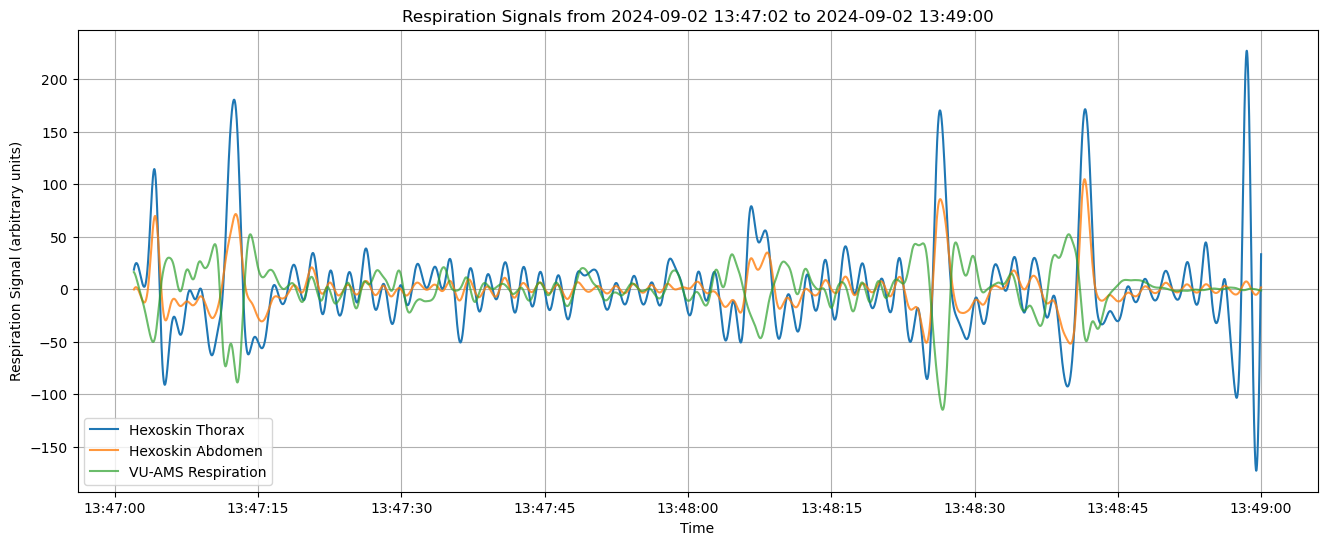

In [60]:
# visualizing all three respiration signals now that they are synced and trimmed
import matplotlib.pyplot as plt
import pandas as pd

# define here the datetime interval to visualize
start_time = pd.Timestamp("2024-09-02 13:47:02")
end_time   = pd.Timestamp("2024-09-02 13:49:00")

# from each pd.Series, selecting the part we want to visualize
thorax_seg = resp_hexoskin_thorax_trimmed[start_time:end_time]
abdomen_seg = resp_hexoskin_abdomen_trimmed[start_time:end_time]
vuams_seg = resp_vuams_trimmed[start_time:end_time]

# plot, with time (the datetime as the x axis)
plt.figure(figsize=(16,6))
plt.plot(thorax_seg.index, thorax_seg.values, label='Hexoskin Thorax')  # .index specifies the time along the x axis, 
                                                                         # .values returns the actual signal values
plt.plot(abdomen_seg.index, abdomen_seg.values, label='Hexoskin Abdomen', alpha=0.8)
plt.plot(vuams_seg.index, vuams_seg.values, label='VU-AMS Respiration', alpha=0.7)

plt.xlabel('Time')
plt.ylabel('Respiration Signal (arbitrary units)')
plt.title(f'Respiration Signals from {start_time} to {end_time}')
plt.legend()
plt.grid(True)
plt.show()


In [61]:
# the signals are synced in time but note the peaks (could be due to signal interference - these should be removed in physiodata toolbox via the
#local outlier removal algorithm

In [62]:
# download as tsv files to be imported in PhysioData Toolbox
# we will enter all three respiration signals to the same tsv - these all start at the same time, are synced, and can be matched to minute postures
# we first combine into a dataframe (otherwise we would have three different tsv files which would be more time consuming)

resp_df = pd.DataFrame({
    'Hexoskin_Thorax': resp_hexoskin_thorax_trimmed.values,
    'Hexoskin_Abdomen': resp_hexoskin_abdomen_trimmed.values,
    'VUAMS_Respiration': resp_vuams_trimmed.values
})

# insert a Time column that goes like 0, 1/128, 2/128, 3/128...
time_seconds = np.arange(len(resp_df)) / fs
resp_df.insert(0, 'Time', time_seconds)   #entering the time this way allows the data to be read by PhysioData toolbox

resp_df

,Time,Hexoskin_Thorax,Hexoskin_Abdomen,VUAMS_Respiration
0,0.000000,18.819048,9.039472,-19.734964
1,0.015625,18.042518,8.974336,-20.184855
2,0.031250,17.263366,8.906190,-20.627201
3,0.046875,16.481620,8.835033,-21.062128
4,0.062500,15.697306,8.760864,-21.488780
...,...,...,...,...
4629947,72342.921875,7.064952,7.009723,-42.789529
4629948,72342.937500,6.925584,6.922420,-42.739298
4629949,72342.953125,6.796252,6.839105,-42.681167
4629950,72342.968750,6.676901,6.759770,-42.615837


In [63]:
# save to tsv - using the to_csv function but with t as the separator
resp_df.to_csv(f'resp_combined_{ppid}.tsv', sep='\t', index=False) #NOTE: This data is already filtered! Not entering the raw data to Physiodata toolbox

# CALCULATION OF CALIBRATION FACTORS

## Uploading the label file

In [64]:
import pandas as pd
import matplotlib.pyplot as plt

# loading the file with the spirometer calibration task labels, skipping the comment lines
# note that you should change the path to the current participant's directory
labels_df = pd.read_csv(
    r"C:\Users\msa583\OneDrive - Vrije Universiteit Amsterdam\Desktop\Ambulatory Speech and IE-ratio\RQ1\Physiodata\12008\timelabelsPPID_12008.txt",
    sep="\t", #there is a tab seperator in the text file
    comment="#",
    names=["StartTime", "StopTime", "Label"] #sequence of column labels to apply
)

labels_df

,StartTime,StopTime,Label
0,02-09-24/10:15:51,02-09-24/10:15:52,2
1,02-09-24/10:15:52,02-09-24/10:15:55,3
2,02-09-24/10:15:55,02-09-24/10:16:57,4
3,02-09-24/10:16:57,02-09-24/10:39:52,5
4,02-09-24/10:39:52,02-09-24/10:39:59,6
5,02-09-24/10:39:59,02-09-24/10:43:57,7
6,02-09-24/10:43:57,02-09-24/10:45:57,8
7,02-09-24/10:45:57,02-09-24/10:47:07,9
8,02-09-24/10:47:07,02-09-24/10:49:07,10
9,02-09-24/10:49:07,02-09-24/10:51:03,11


In [65]:
#converting the start and stop times to datetime objects
time_format = "%d-%m-%y/%H:%M:%S" #we first define the time format, this is the datetime format for each task (in labels_df) that we see from what we read in
labels_df["StartTime"] = pd.to_datetime(labels_df["StartTime"], format=time_format)  #converts into a pandas datetime object
labels_df["StopTime"] = pd.to_datetime(labels_df["StopTime"], format=time_format) #converts into a pandas datetime object
labels_df

,StartTime,StopTime,Label
0,2024-09-02 10:15:51,2024-09-02 10:15:52,2
1,2024-09-02 10:15:52,2024-09-02 10:15:55,3
2,2024-09-02 10:15:55,2024-09-02 10:16:57,4
3,2024-09-02 10:16:57,2024-09-02 10:39:52,5
4,2024-09-02 10:39:52,2024-09-02 10:39:59,6
5,2024-09-02 10:39:59,2024-09-02 10:43:57,7
6,2024-09-02 10:43:57,2024-09-02 10:45:57,8
7,2024-09-02 10:45:57,2024-09-02 10:47:07,9
8,2024-09-02 10:47:07,2024-09-02 10:49:07,10
9,2024-09-02 10:49:07,2024-09-02 10:51:03,11


In [66]:
labels_df["Label"] = pd.to_numeric(labels_df["Label"])
print(labels_df)

#check if the Label column is now numeric
pd.api.types.is_numeric_dtype(labels_df["Label"])

             StartTime            StopTime  Label
0  2024-09-02 10:15:51 2024-09-02 10:15:52      2
1  2024-09-02 10:15:52 2024-09-02 10:15:55      3
2  2024-09-02 10:15:55 2024-09-02 10:16:57      4
3  2024-09-02 10:16:57 2024-09-02 10:39:52      5
4  2024-09-02 10:39:52 2024-09-02 10:39:59      6
5  2024-09-02 10:39:59 2024-09-02 10:43:57      7
6  2024-09-02 10:43:57 2024-09-02 10:45:57      8
7  2024-09-02 10:45:57 2024-09-02 10:47:07      9
8  2024-09-02 10:47:07 2024-09-02 10:49:07     10
9  2024-09-02 10:49:07 2024-09-02 10:51:03     11
10 2024-09-02 10:51:03 2024-09-02 10:53:03     12
11 2024-09-02 10:53:03 2024-09-02 10:57:27     13
12 2024-09-02 10:57:27 2024-09-02 10:59:57     14
13 2024-09-02 10:59:57 2024-09-02 11:00:31     15
14 2024-09-02 11:00:31 2024-09-02 11:03:01     16
15 2024-09-02 11:03:01 2024-09-02 11:03:28     17
16 2024-09-02 11:03:28 2024-09-02 11:05:58     18
17 2024-09-02 11:05:58 2024-09-02 11:06:36     19
18 2024-09-02 11:06:36 2024-09-02 11:09:06     20


True

In [67]:
# defining the function to assign the task labels to the signals
def assign_labels(series, labels_df):
    df = series.to_frame(name="signal") # convert the given series into a dataframe and let the signal values column have the name signal
    df["Label"] = None # add new column called label
    for _, row in labels_df.iterrows(): #loop over each row in labels_df, and access the StartTime, StopTime, and Label
        mask = (df.index >= row["StartTime"]) & (df.index < row["StopTime"]) #create a boolean mask array that, for the signal dataframe, is True for all timestamps within the task and False elsewhere
        df.loc[mask, "Label"] = row["Label"] #for all rows where mask is True, assigns's the row's Label value to the current row's (from the labels_df) label
    return df

# assign the labels to each respiration signal
vuams_df = assign_labels(resp_vuams_trimmed, labels_df)
hexoskin_thorax_df = assign_labels(resp_hexoskin_thorax_trimmed, labels_df)
hexoskin_abdomen_df = assign_labels(resp_hexoskin_abdomen_trimmed, labels_df)

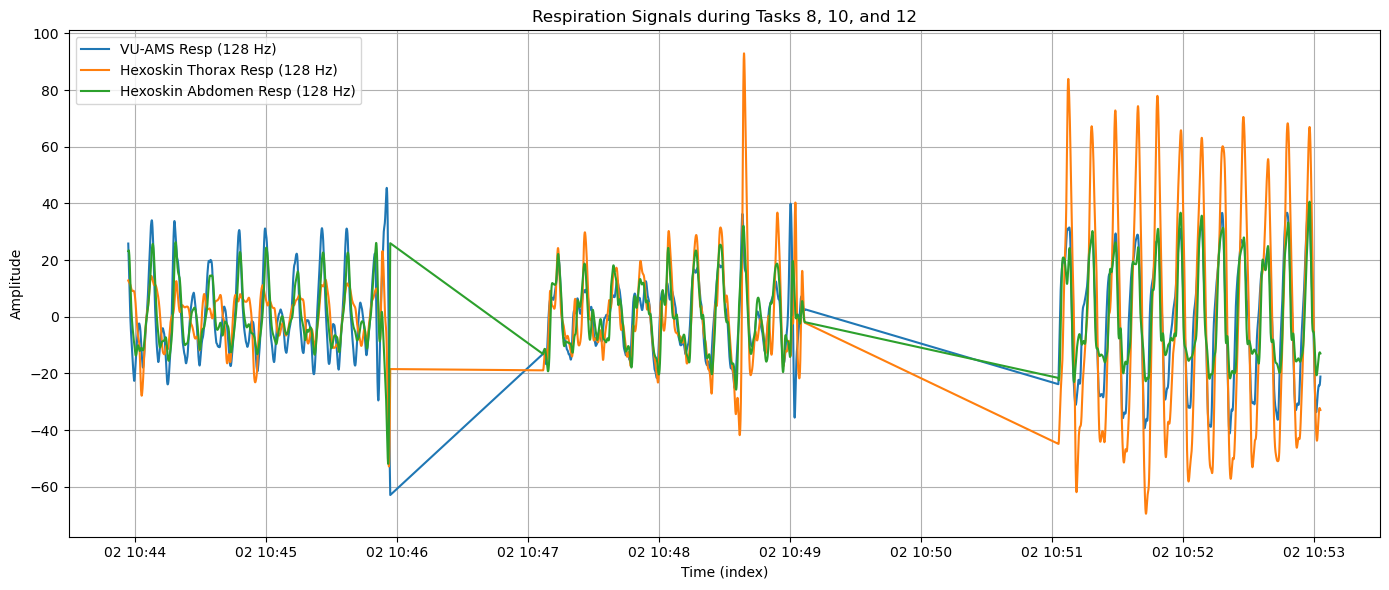

In [68]:
import matplotlib.pyplot as plt

# tasks to plot list
tasks_to_plot = [8, 10, 12]

#Label 8: Spirometer breathing supine
#Label 10: Spirometer breathing sitting
#Label 12: Spirometer breathing standing

# filtering each dataframe
vuams_subset = vuams_df[vuams_df["Label"].isin(tasks_to_plot)] #the argument inside with .isin just creates a boolean mask (F, F, F, T...) which should be again inserted into the dataframe name to display the wanted data
thorax_subset = hexoskin_thorax_df[hexoskin_thorax_df["Label"].isin(tasks_to_plot)]
abdomen_subset = hexoskin_abdomen_df[hexoskin_abdomen_df["Label"].isin(tasks_to_plot)]

plt.figure(figsize=(14, 6))
plt.plot(vuams_subset.index, vuams_subset["signal"], label="VU-AMS Resp (128 Hz)")
plt.plot(thorax_subset.index, thorax_subset["signal"], label="Hexoskin Thorax Resp (128 Hz)")
plt.plot(abdomen_subset.index, abdomen_subset["signal"], label="Hexoskin Abdomen Resp (128 Hz)")

plt.xlabel("Time (index)")
plt.ylabel("Amplitude")
plt.title("Respiration Signals during Tasks 8, 10, and 12")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


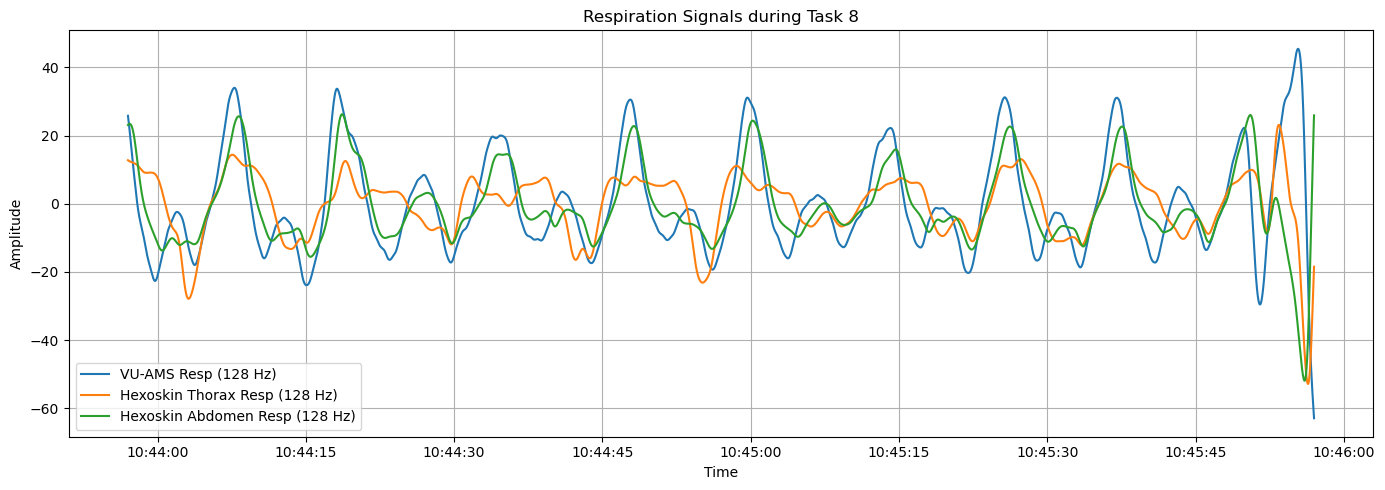

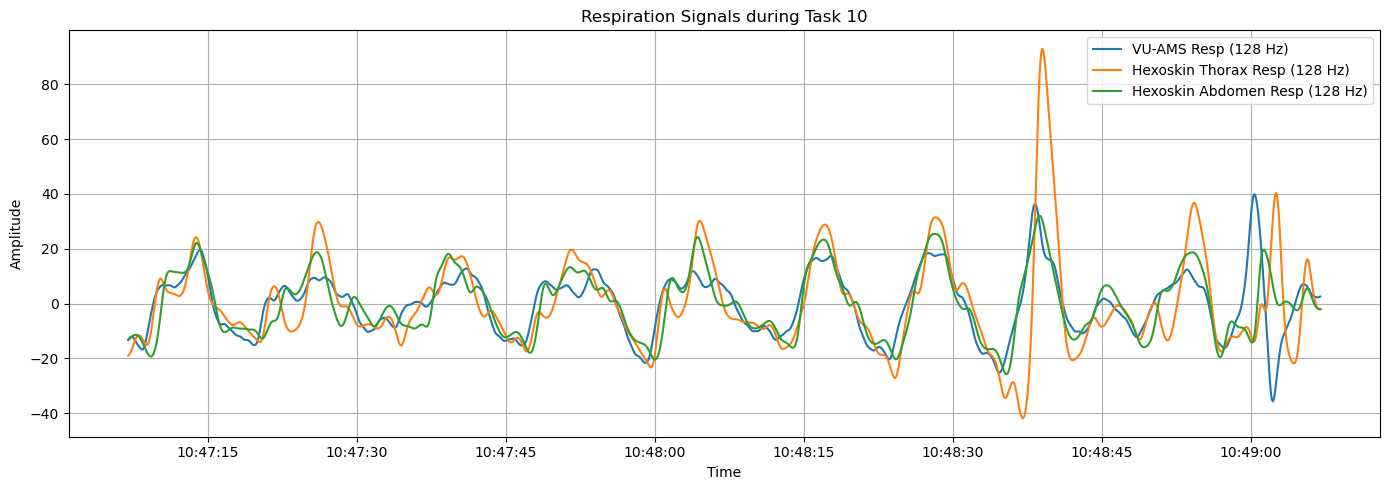

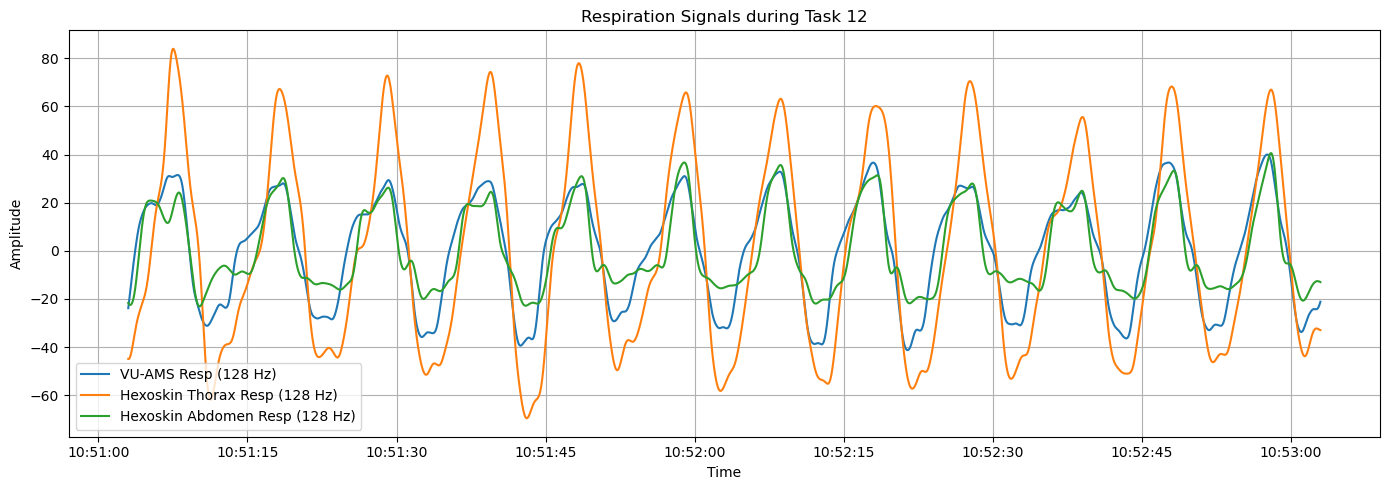

In [69]:
#also plot the three signals on top of each other, separately for each task (easier to take a look at each individual posture's task)
import matplotlib.pyplot as plt

tasks_to_plot = [8, 10, 12] #same

for task in tasks_to_plot:
    vuams_task = vuams_df[vuams_df["Label"] == task]   # == is simpler than .isin - better here as we want to return Trues for only one task per iteration
    thorax_task = hexoskin_thorax_df[hexoskin_thorax_df["Label"] == task]
    abdomen_task = hexoskin_abdomen_df[hexoskin_abdomen_df["Label"] == task]

    plt.figure(figsize=(14, 5))
    plt.plot(vuams_task.index, vuams_task["signal"], label="VU-AMS Resp (128 Hz)", color='tab:blue')
    plt.plot(thorax_task.index, thorax_task["signal"], label="Hexoskin Thorax Resp (128 Hz)", color='tab:orange')
    plt.plot(abdomen_task.index, abdomen_task["signal"], label="Hexoskin Abdomen Resp (128 Hz)", color='tab:green')

    plt.title(f"Respiration Signals during Task {task}")
    plt.xlabel("Time")
    plt.ylabel("Amplitude")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


In [70]:
#note: the signals are almost perfectly synced in the lab - we will be able to match which is which easily

In [71]:
# convert vuams signal sections into arrays
vuams_resp_8  = vuams_df[vuams_df["Label"] == 8]["signal"].to_numpy()
vuams_resp_10 = vuams_df[vuams_df["Label"] == 10]["signal"].to_numpy()
vuams_resp_12 = vuams_df[vuams_df["Label"] == 12]["signal"].to_numpy()

# convert hexoskin thorax signal sections into arrays
hexoskin_thorax_8  = hexoskin_thorax_df[hexoskin_thorax_df["Label"] == 8]["signal"].to_numpy()
hexoskin_thorax_10 = hexoskin_thorax_df[hexoskin_thorax_df["Label"] == 10]["signal"].to_numpy()
hexoskin_thorax_12 = hexoskin_thorax_df[hexoskin_thorax_df["Label"] == 12]["signal"].to_numpy()

# convert hexoskin abdomen signal sections into arrays
hexoskin_abdomen_8  = hexoskin_abdomen_df[hexoskin_abdomen_df["Label"] == 8]["signal"].to_numpy()
hexoskin_abdomen_10 = hexoskin_abdomen_df[hexoskin_abdomen_df["Label"] == 10]["signal"].to_numpy()
hexoskin_abdomen_12 = hexoskin_abdomen_df[hexoskin_abdomen_df["Label"] == 12]["signal"].to_numpy()

#doing zero padding of 10 seconds (signal sampling rate was 128 Hz, so 1280 samples) to the beginning and ending of each array 
vuams_resp_8 = np.concatenate([np.zeros(1280), vuams_resp_8, np.zeros(1280)])
vuams_resp_10 = np.concatenate([np.zeros(1280), vuams_resp_10, np.zeros(1280)])
vuams_resp_12 = np.concatenate([np.zeros(1280), vuams_resp_12, np.zeros(1280)])

hexoskin_thorax_8 = np.concatenate([np.zeros(1280), hexoskin_thorax_8, np.zeros(1280)])
hexoskin_thorax_10 = np.concatenate([np.zeros(1280), hexoskin_thorax_10, np.zeros(1280)])
hexoskin_thorax_12 = np.concatenate([np.zeros(1280), hexoskin_thorax_12, np.zeros(1280)])

hexoskin_abdomen_8 = np.concatenate([np.zeros(1280), hexoskin_abdomen_8, np.zeros(1280)])
hexoskin_abdomen_10 = np.concatenate([np.zeros(1280), hexoskin_abdomen_10, np.zeros(1280)])
hexoskin_abdomen_12 = np.concatenate([np.zeros(1280), hexoskin_abdomen_12, np.zeros(1280)])

## SUPINE

### READING IN SPIROMETER

In [91]:
#enter the participant id here, you won't need to reenter later on
ppid = "12008"

In [92]:
#reading the supine csv recording from the spirometer (script should be in the same directory as the csv files for spirometry)
volume_supine = pd.read_csv(f'supine_{ppid}.csv')
#viewing the dataframe
volume_supine.head()

,Data Set 1:Time(s),Data Set 1:Flow Rate(L/s),Data Set 1:Volume(L),Data Set 2:Time(s),Data Set 2:Flow Rate(L/s),Data Set 2:Volume(L)
0,0.000,0.0,0.0,0.000,-0.331608,0.0
1,0.005,0.0,0.0,0.005,-0.331608,0.0
2,0.010,0.0,0.0,0.010,-0.331608,0.0
3,0.015,0.0,0.0,0.015,-0.328198,0.0
4,0.020,0.0,0.0,0.020,-0.324762,0.0


In [93]:
#the dataframe also has the flow rate and time but we are not interested in those, so selecting the tidal volume column
spirometer_supine = volume_supine['Data Set 2:Volume(L)'] #here, you might need to change the number of the data set

#converting the data format from float64 to numpy array format for later peak valley detection using neurokit2
spirometer_supine = np.array(spirometer_supine)

# only select the first 120 seconds of the signal (the first 2400 rows due to the sampling rate being 200)
spirometer_supine = spirometer_supine[:24000]

#doing zero padding of 10 seconds (signal sampling rate was 200 Hz) to the beginning and ending of the signal
spirometer_supine = np.concatenate([np.zeros(2000), spirometer_supine, np.zeros(2000)])
print(spirometer_supine)

[0. 0. 0. ... 0. 0. 0.]


In [94]:
import neurokit2 as nk
#implementing the respiratory processing function from neurokit2 to automatically detect the peaks and troughs
signals, info = nk.rsp_process(spirometer_supine, sampling_rate=200)
signals       #the first output (signals) generates a  dataframe that includes the raw signal values and RSP_Peaks and RSP_Troughs
              #info stores a dictionary with the arrays for the RSP_Peaks, RSP_Troughs, sampling rate

,RSP_Raw,RSP_Clean,RSP_Amplitude,RSP_Rate,RSP_RVT,RSP_Phase,RSP_Phase_Completion,RSP_Symmetry_PeakTrough,RSP_Symmetry_RiseDecay,RSP_Peaks,RSP_Troughs
0,0.0,0.000221,1.300282,4.853933,0.003006,NaN,0.0,0.612684,0.435206,0,0
1,0.0,0.000183,1.300282,4.853933,0.003007,NaN,0.0,0.612684,0.435206,0,0
2,0.0,0.000144,1.300282,4.853933,0.003009,NaN,0.0,0.612684,0.435206,0,0
3,0.0,0.000106,1.300282,4.853933,0.003010,NaN,0.0,0.612684,0.435206,0,0
4,0.0,0.000067,1.300282,4.853933,0.003011,NaN,0.0,0.612684,0.435206,0,0
...,...,...,...,...,...,...,...,...,...,...,...
27995,0.0,-0.000162,1.160698,5.342832,0.001304,NaN,0.0,0.621644,0.315672,0,0
27996,0.0,-0.000143,1.160698,5.342832,0.001307,NaN,0.0,0.621644,0.315672,0,0
27997,0.0,-0.000125,1.160698,5.342832,0.001310,NaN,0.0,0.621644,0.315672,0,0
27998,0.0,-0.000108,1.160698,5.342832,0.001313,NaN,0.0,0.621644,0.315672,0,0


Index([2576, 4986, 7185, 9292, 12397, 15154, 17744, 20491, 22708, 24986], dtype='int64')
Index([1995, 3330, 5936, 8560, 11478, 13761, 16803, 18641, 21999, 24245], dtype='int64')


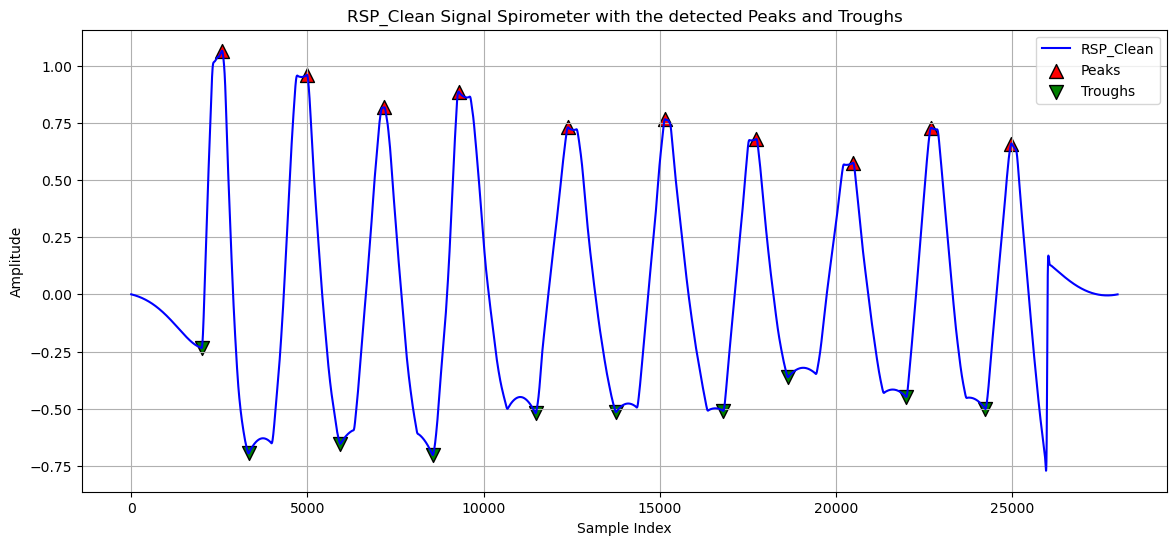

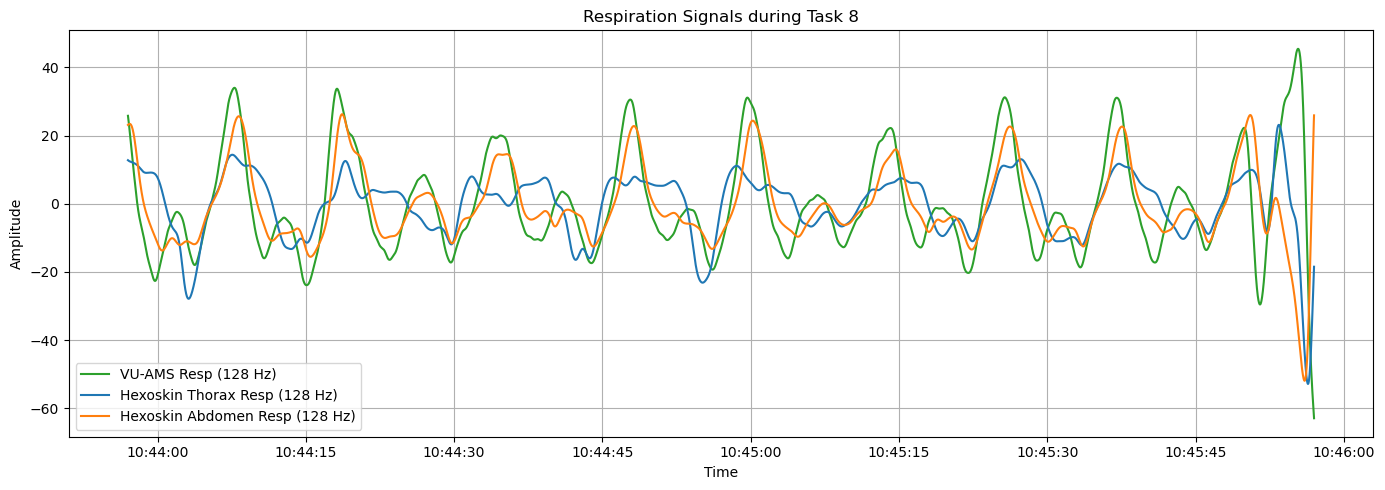

In [95]:
import matplotlib.pyplot as plt
plt.figure(figsize=(14, 6))

# plot the filtered (by neurokit 2) spirometer signal (note this is for visualization, and the amplitude calculations are later performed on the raw values)
plt.plot(signals['RSP_Clean'], label="RSP_Clean", color='blue')

# plot a red triangle for when there are detected peaks
if signals['RSP_Peaks'].sum() > 0:  #if at least one peak exists, proceed with plotting
    peak_indices = signals.index[signals['RSP_Peaks'] == 1] #makes an array for the index of each peak
    print(peak_indices)
    plt.scatter(peak_indices, signals.loc[peak_indices, 'RSP_Clean'], color='red', label='Peaks', marker='^', s=100, edgecolor='black') #X is peak indices
                                                                                                                 #Y is the signals value at the index

# plot a green triangle for when there are detected troughs
if signals['RSP_Troughs'].sum() > 0:  #if at least one trough exists, proceed with plotting
    trough_indices = signals.index[signals['RSP_Troughs'] == 1] #makes an array for the index of each trough
    print(trough_indices)
    plt.scatter(trough_indices, signals.loc[trough_indices, 'RSP_Clean'], color='green', label='Troughs', marker='v', s=100, edgecolor='black')

plt.title('RSP_Clean Signal Spirometer with the detected Peaks and Troughs')
plt.xlabel('Sample Index')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True)
plt.show()

#plot the three signals on top of each other, separately for each task
import matplotlib.pyplot as plt

tasks_to_plot = [8] #same code from above, only for task label 8

for task in tasks_to_plot:
    vuams_task = vuams_df[vuams_df["Label"] == task]
    thorax_task = hexoskin_thorax_df[hexoskin_thorax_df["Label"] == task]
    abdomen_task = hexoskin_abdomen_df[hexoskin_abdomen_df["Label"] == task]

    plt.figure(figsize=(14, 5))
    plt.plot(vuams_task.index, vuams_task["signal"], label="VU-AMS Resp (128 Hz)", color='tab:green')
    plt.plot(thorax_task.index, thorax_task["signal"], label="Hexoskin Thorax Resp (128 Hz)", color='tab:blue')
    plt.plot(abdomen_task.index, abdomen_task["signal"], label="Hexoskin Abdomen Resp (128 Hz)", color='tab:orange')

    plt.title(f"Respiration Signals during Task {task}")
    plt.xlabel("Time")
    plt.ylabel("Amplitude")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


In [96]:
# define a list to store the tidal volume values for each peak
tidal_volumes_supine = []

for peak_idx in signals.index[signals['RSP_Peaks'] == 1]: #identify where there are peaks
    # find the preceding trough
    preceding_troughs = signals.index[(signals['RSP_Troughs'] == 1) & (signals.index < peak_idx)] #gives list of all preceding troughs for a given peak
    
    if not preceding_troughs.empty:
        trough_idx = preceding_troughs[-1]  # select the last trough in the list (to get the most recent trough)
        tidal_volume = signals.loc[peak_idx, 'RSP_Raw'] - signals.loc[trough_idx, 'RSP_Raw']  #subtract the value of the give peak from that of the
                                                                                                #preceding trough
        tidal_volumes_supine.append(tidal_volume) #the calculated tidal volume gets appended to the previously created list

# make the tidal volume list a mumpy array
tv_supine_spiro = np.array(tidal_volumes_supine)
print(tv_supine_spiro)
print(len(tv_supine_spiro))


[1.20977533 1.75793892 1.41731778 1.84688199 1.55642605 1.39112541
 1.26200905 1.02277975 1.29152939 1.36358264]
10


### CALIBRATING VUAMS RESPIRATION

In [97]:
import neurokit2 as nk
#implementing the respiratory processing function from neurokit2 to automatically detect the peaks and troughs
signals_vuams_8, info = nk.rsp_process(vuams_resp_8, sampling_rate=128)
signals_vuams_8       #the first output (signals) generates a  dataframe that includes the raw signal values and RSP_Peaks and RSP_Troughs
              #info stores a dictionary with the arrays for the RSP_Peaks, RSP_Troughs, sampling rate

,RSP_Raw,RSP_Clean,RSP_Amplitude,RSP_Rate,RSP_RVT,RSP_Phase,RSP_Phase_Completion,RSP_Symmetry_PeakTrough,RSP_Symmetry_RiseDecay,RSP_Peaks,RSP_Troughs
0,0.0,-0.254543,19.508045,8.587002,0.290323,NaN,0.0,0.504403,0.542471,0,0
1,0.0,-0.254507,19.508045,8.587002,0.290599,NaN,0.0,0.504403,0.542471,0,0
2,0.0,-0.254470,19.508045,8.587002,0.290856,NaN,0.0,0.504403,0.542471,0,0
3,0.0,-0.254431,19.508045,8.587002,0.291095,NaN,0.0,0.504403,0.542471,0,0
4,0.0,-0.254391,19.508045,8.587002,0.291315,NaN,0.0,0.504403,0.542471,0,0
...,...,...,...,...,...,...,...,...,...,...,...
17915,0.0,0.020476,73.886209,11.066282,0.292320,NaN,0.0,0.557241,0.697406,0,0
17916,0.0,0.018377,73.886209,11.066282,0.294073,NaN,0.0,0.557241,0.697406,0,0
17917,0.0,0.016345,73.886209,11.066282,0.295797,NaN,0.0,0.557241,0.697406,0,0
17918,0.0,0.014390,73.886209,11.066282,0.297494,NaN,0.0,0.557241,0.697406,0,0


Index([ 1911,  2659,  3986,  5113,  6108,  6905,  7785,  8530,  9300, 10212,
       11156, 11826, 12634, 14084, 14884, 15730, 16433],
      dtype='int64')
Index([ 1630,  2148,  3598,  4664,  5463,  6538,  7285,  8259,  8853,  9823,
       10549, 11539, 12166, 13615, 14574, 15246, 15940],
      dtype='int64')


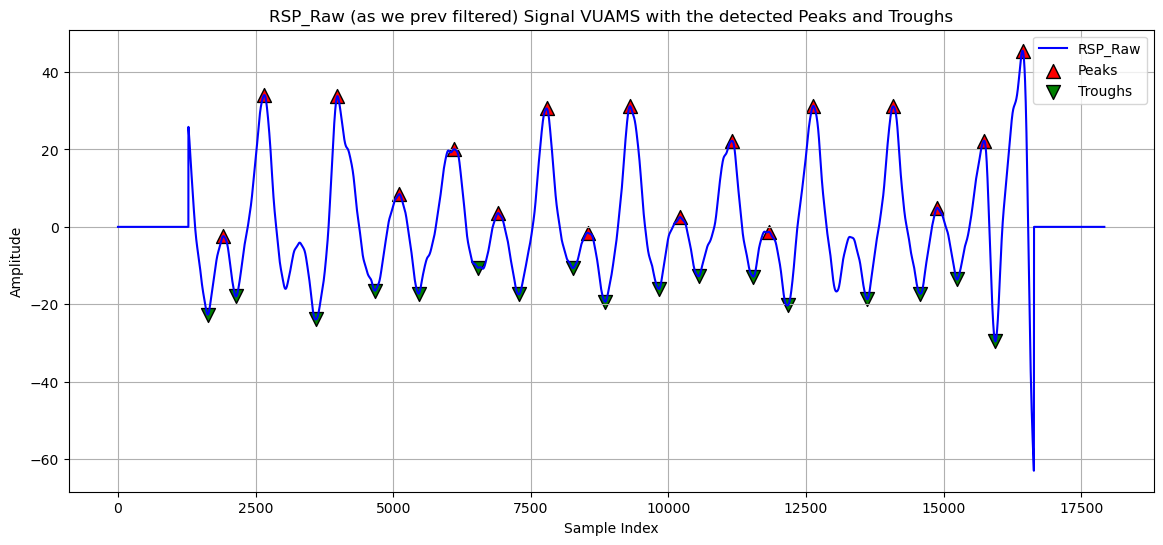

In [98]:
import matplotlib.pyplot as plt
plt.figure(figsize=(14, 6))

# plot the "raw" VUAMS respiration - supine (note that this "Raw" column contains the signal we already filtered previously)
plt.plot(signals_vuams_8['RSP_Raw'], label="RSP_Raw", color='blue')

# plot a red triangle for when there are detected peaks
if signals_vuams_8['RSP_Peaks'].sum() > 0:  #if at least one peak exists, proceed with plotting
    peak_indices = signals_vuams_8.index[signals_vuams_8['RSP_Peaks'] == 1] #makes an array for the index of each peak
    print(peak_indices)
    plt.scatter(peak_indices, signals_vuams_8.loc[peak_indices, 'RSP_Raw'], color='red', label='Peaks', marker='^', s=100, edgecolor='black') #X is peak indices
                                                                                                                 #Y is the signals value at the index
# plot a green triangle for when there are detected troughs
if signals_vuams_8['RSP_Troughs'].sum() > 0:  #if at least one trough exists, proceed with plotting
    trough_indices = signals_vuams_8.index[signals_vuams_8['RSP_Troughs'] == 1] #makes an array for the index of each trough
    print(trough_indices)
    plt.scatter(trough_indices, signals_vuams_8.loc[trough_indices, 'RSP_Raw'], color='green', label='Troughs', marker='v', s=100, edgecolor='black')

plt.title('RSP_Raw (as we prev filtered) Signal VUAMS with the detected Peaks and Troughs')
plt.xlabel('Sample Index')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True)
plt.show()

In [99]:
# define a list to store the tidal volume values for each peak
vuams_depths_supine = []

for peak_idx in signals_vuams_8.index[signals_vuams_8['RSP_Peaks'] == 1]: #identify where there are peaks (only picks the indices where mask is True)
    # find the preceding trough (per peak)
    preceding_troughs = signals_vuams_8.index[(signals_vuams_8['RSP_Troughs'] == 1) & (signals_vuams_8.index < peak_idx)] #gives list of all preceding troughs for a given peak
    
    if not preceding_troughs.empty:
        trough_idx = preceding_troughs[-1]  # select the last trough in the list (to get the most recent trough)
        tidal_volume = signals_vuams_8.loc[peak_idx, 'RSP_Raw'] - signals_vuams_8.loc[trough_idx, 'RSP_Raw']  #subtract the value of the give peak from that of the
                                                                                                #preceding trough
        vuams_depths_supine.append(tidal_volume) #the calculated respiratory depths gets appended to the previously created list

# make the tidal volume list a numpy array
vuams_depths_supine = np.array(vuams_depths_supine)
print(vuams_depths_supine)
print(len(vuams_depths_supine))

[20.24978401 51.97405433 57.63725167 24.90988843 37.28014198 14.07750676
 47.98313947  9.12860967 50.47542702 18.55243731 34.98117011 11.53265114
 51.52623604 49.77502437 22.20556706 35.83683353 75.03459956]
17


Index([2576, 4986, 7185, 9292, 12397, 15154, 17744, 20491, 22708, 24986], dtype='int64')
Index([1995, 3330, 5936, 8560, 11478, 13761, 16803, 18641, 21999, 24245], dtype='int64')


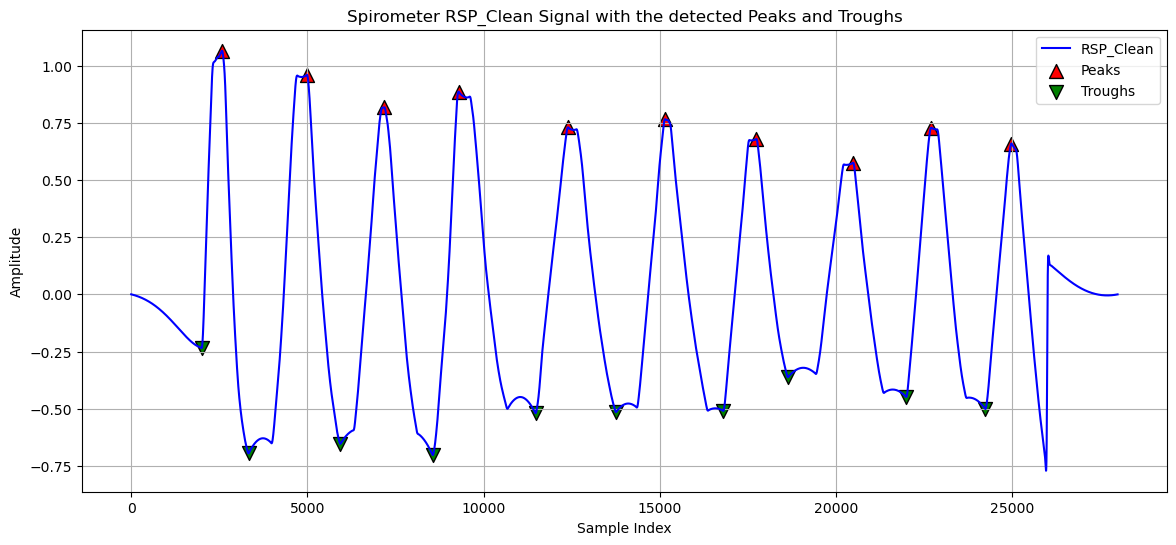

10
Index([ 1911,  2659,  3986,  5113,  6108,  6905,  7785,  8530,  9300, 10212,
       11156, 11826, 12634, 14084, 14884, 15730, 16433],
      dtype='int64')
Index([ 1630,  2148,  3598,  4664,  5463,  6538,  7285,  8259,  8853,  9823,
       10549, 11539, 12166, 13615, 14574, 15246, 15940],
      dtype='int64')


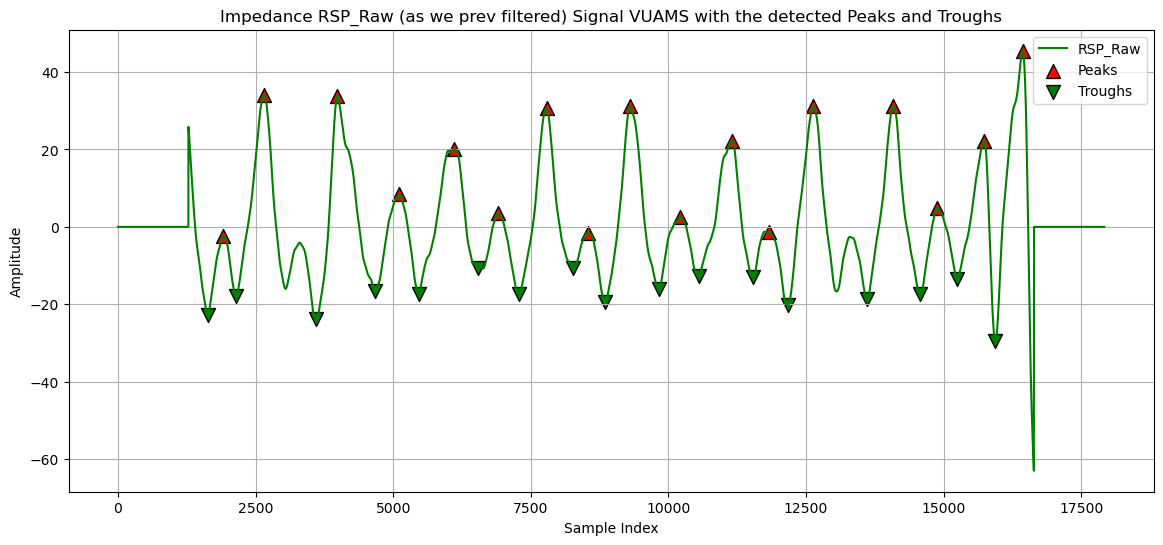

17


In [100]:
#PLOT THE SPIROMETER AGAINST THE IMPEDANCE - SUPINE

import matplotlib.pyplot as plt
plt.figure(figsize=(14, 6))

# plot the cleaned spirometer signal from the signals dataframe - supine - for visualization purposes
plt.plot(signals['RSP_Clean'], label="RSP_Clean", color='blue')

# plot a red triangle for when there are detected peaks
if signals['RSP_Peaks'].sum() > 0:  #if at least one peak exists, proceed with plotting
    peak_indices = signals.index[signals['RSP_Peaks'] == 1] #makes an array for the index of each peak
    print(peak_indices)
    plt.scatter(peak_indices, signals.loc[peak_indices, 'RSP_Clean'], color='red', label='Peaks', marker='^', s=100, edgecolor='black') #X is peak indices
                                                                                                                 #Y is the signals value at the index

# plot a green triangle for when there are detected troughs
if signals['RSP_Troughs'].sum() > 0:  #if at least one trough exists, proceed with plotting
    trough_indices = signals.index[signals['RSP_Troughs'] == 1] #makes an array for the index of each trough
    print(trough_indices)
    plt.scatter(trough_indices, signals.loc[trough_indices, 'RSP_Clean'], color='green', label='Troughs', marker='v', s=100, edgecolor='black')

plt.title('Spirometer RSP_Clean Signal with the detected Peaks and Troughs')
plt.xlabel('Sample Index')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True)
plt.show()
print(len(tv_supine_spiro))

import matplotlib.pyplot as plt
plt.figure(figsize=(14, 6))

# plot the "raw" (previously filtered) VUAMS signal - supine
plt.plot(signals_vuams_8['RSP_Raw'], label="RSP_Raw", color='green')

# plot a red triangle for when there are detected peaks
if signals_vuams_8['RSP_Peaks'].sum() > 0:  #if at least one peak exists, proceed with plotting
    peak_indices = signals_vuams_8.index[signals_vuams_8['RSP_Peaks'] == 1] #makes an array for the index of each peak
    print(peak_indices)
    plt.scatter(peak_indices, signals_vuams_8.loc[peak_indices, 'RSP_Raw'], color='red', label='Peaks', marker='^', s=100, edgecolor='black') #X is peak indices
                                                                                                                 #Y is the signals value at the index

# plot a green triangle for when there are detected troughs
if signals_vuams_8['RSP_Troughs'].sum() > 0:  #if at least one trough exists, proceed with plotting
    trough_indices = signals_vuams_8.index[signals_vuams_8['RSP_Troughs'] == 1] #makes an array for the index of each trough
    print(trough_indices)
    plt.scatter(trough_indices, signals_vuams_8.loc[trough_indices, 'RSP_Raw'], color='green', label='Troughs', marker='v', s=100, edgecolor='black')

plt.title('Impedance RSP_Raw (as we prev filtered) Signal VUAMS with the detected Peaks and Troughs')
plt.xlabel('Sample Index')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True)
plt.show()
print(len(vuams_depths_supine))



In [101]:
#drop the first cycle from impedance
#vuams_depths_supine = vuams_depths_supine[1:]
#drop the last cycle from spirometer
#tv_supine_spiro = tv_supine_spiro[:-1]

In [102]:
import numpy as np
print(vuams_depths_supine)
indices_to_remove = [0, 3, 5, 7, 9, 11, 14, 16] #removing these "breaths" from vuams (they actually just belong to the larger breath"
vuams_depths_supine = np.delete(vuams_depths_supine, indices_to_remove)
print(vuams_depths_supine)

[20.24978401 51.97405433 57.63725167 24.90988843 37.28014198 14.07750676
 47.98313947  9.12860967 50.47542702 18.55243731 34.98117011 11.53265114
 51.52623604 49.77502437 22.20556706 35.83683353 75.03459956]
[51.97405433 57.63725167 37.28014198 47.98313947 50.47542702 34.98117011
 51.52623604 49.77502437 35.83683353]


In [103]:
print(len(vuams_depths_supine))

9


In [104]:
#drop the last cycle in spirometer
tv_supine_spiro = tv_supine_spiro[:-1]

In [105]:
#drop the last in impedance
#vuams_depths_supine = vuams_depths_supine[:-1]

In [106]:
#drop the last detected cycle in both
#tv_supine_spiro = tv_supine_spiro[:-1]
#vuams_depths_supine = vuams_depths_supine[:-1]

In [107]:
print(len(vuams_depths_supine))
print(len(tv_supine_spiro))

9
9


In [108]:
#here we solve for beta (slope and intercept) such that we create a least squares regression of spirometer volume being predicted by
#impedance value times some slope plus an intercept
#specifically, we use the Moore-Penrose pseudoinverse way of solving for the regression coefficients - using the ordinary least squares formula
#under statsmodels give the same answers
import numpy as np

assert len(vuams_depths_supine) == len(tv_supine_spiro) # ensure that the data sets have the same length
print(vuams_depths_supine)
X = vuams_depths_supine[:, np.newaxis]  # convert impedance to a 2D array, necessary for linear regression in matrix format
print(X)
y = tv_supine_spiro  # spirometer volumes
print(y)

# add a columns of ones to include an intercept in the regression
X = np.column_stack((np.ones(len(vuams_depths_supine)), X))  # Augment X with a column of ones
print(X)

# calculate the pseudoinverse of the matrix X
X_pinv = np.linalg.pinv(X)

# multiply the pseudoinverse of X with the outcome variable y to calculate the slope and intercept
conversion_coefficients_supine = np.dot(X_pinv, y) #dot product function for matrix multiplication
print(conversion_coefficients_supine)

# print the conversion coefficients
vuams_intercept_supine, vuams_slope_supine = conversion_coefficients_supine  #to be saved at the end  of the document
print(f"Conversion coefficients: Intercept = {vuams_intercept_supine}, Slope = {vuams_slope_supine}")


[51.97405433 57.63725167 37.28014198 47.98313947 50.47542702 34.98117011
 51.52623604 49.77502437 35.83683353]
[[51.97405433]
 [57.63725167]
 [37.28014198]
 [47.98313947]
 [50.47542702]
 [34.98117011]
 [51.52623604]
 [49.77502437]
 [35.83683353]]
[1.20977533 1.75793892 1.41731778 1.84688199 1.55642605 1.39112541
 1.26200905 1.02277975 1.29152939]
[[ 1.         51.97405433]
 [ 1.         57.63725167]
 [ 1.         37.28014198]
 [ 1.         47.98313947]
 [ 1.         50.47542702]
 [ 1.         34.98117011]
 [ 1.         51.52623604]
 [ 1.         49.77502437]
 [ 1.         35.83683353]]
[1.12332108 0.00633794]
Conversion coefficients: Intercept = 1.1233210784183632, Slope = 0.006337936927497955


In [109]:
import statsmodels.api as sm 
import pandas as pd          
import matplotlib.pyplot as plt 
import numpy as np
# cross-checking to see if we get the same parameters with the ordinary least squares function
x = vuams_depths_supine
y = tv_supine_spiro
x = sm.add_constant(x)
result = sm.OLS(y, x).fit()
print(result.summary()) #we do get the same findings

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.039
Model:                            OLS   Adj. R-squared:                 -0.099
Method:                 Least Squares   F-statistic:                    0.2821
Date:                Thu, 16 Apr 2026   Prob (F-statistic):              0.612
Time:                        11:31:03   Log-Likelihood:              -0.090060
No. Observations:                   9   AIC:                             4.180
Df Residuals:                       7   BIC:                             4.575
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.1233      0.561      2.002      0.0

C:\Users\msa583\AppData\Local\anaconda3\Lib\site-packages\scipy\stats\_axis_nan_policy.py:531: UserWarning: kurtosistest only valid for n>=20 ... continuing anyway, n=9
  res = hypotest_fun_out(*samples, **kwds)


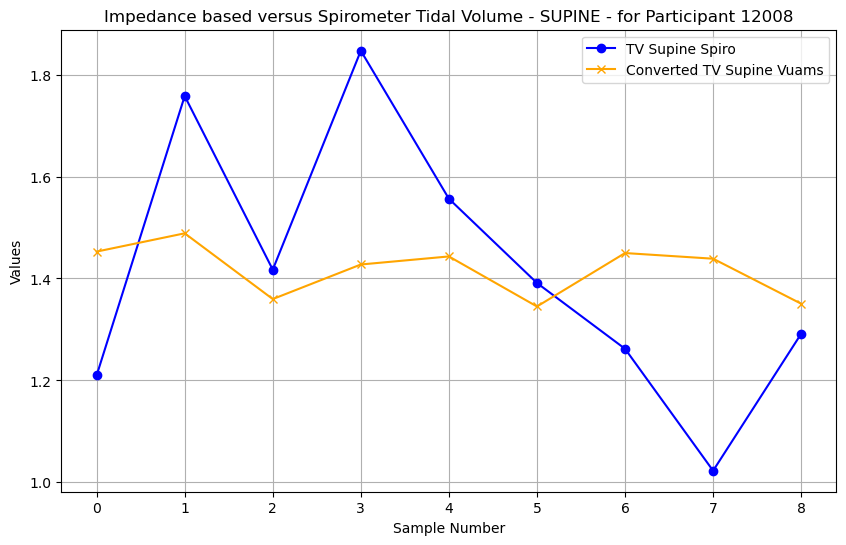

In [110]:
# applying the calculated conversion slope and intercept to the impedance amplitude values
tv_supine_vuams_converted = vuams_depths_supine * vuams_slope_supine + vuams_intercept_supine

plt.figure(figsize=(10, 6))
# plot the actual tidal volumes obtained via spirometer
plt.plot(tv_supine_spiro, label='TV Supine Spiro', color='blue', marker='o')

# plot the calibrated impedance-based tidal volumes
plt.plot(tv_supine_vuams_converted, label='Converted TV Supine Vuams', color='orange', marker='x')

plt.title(f'Impedance based versus Spirometer Tidal Volume - SUPINE - for Participant {ppid}')
plt.xlabel('Sample Number')
plt.ylabel('Values')
plt.legend() 
plt.grid()   
plt.show()

In [111]:
tv_supine_vuams_converted = vuams_depths_supine * vuams_slope_supine + vuams_intercept_supine
y = tv_supine_spiro  # spirometer volumes

# calculate mean absolute percentage error (MAPE) for the impedance supine calibration
vuams_mape_supine = np.mean(np.abs((y - tv_supine_vuams_converted) / (y))) * 100
print(f"mean absolute percentage error (MAPE): {vuams_mape_supine:.4f}%") #to be saved at the end of the script

mean absolute percentage error (MAPE): 14.7663%


In [112]:
#calculate the root mean squared errors (RMSE) for the impedance supine calibration
# calculate squared errors
actual = tv_supine_spiro
predicted = tv_supine_vuams_converted

squared_errors = (actual - predicted) ** 2

# find the mean of squared errors
mse = np.mean(squared_errors)

# take the square root to get RMSE
rmse = np.sqrt(mse)

vuams_rmse_supine = rmse
print("Root Mean Squared Error:", vuams_rmse_supine)

Root Mean Squared Error: 0.2444042121131153


### CALIBRATING HEXOSKIN RESPIRATION

In [113]:
# Repeating the supine spirometer peak-valley detection and amplitude calculation (same as done for VUAMS)
#the dataframe also has the flow rate and time but we are not interested in those, so selecting the tidal volume column
spirometer_supine = volume_supine['Data Set 2:Volume(L)'] #here, you might need to change the number of the data set

#converting the data format from float64 to numpy array format for later peak valley detection using neurokit2
spirometer_supine = np.array(spirometer_supine)

# only select the first 120 seconds of the signal (the first 2400 rows due to the sampling rate being 200)
spirometer_supine = spirometer_supine[:24000]

#doing zero padding of 10 seconds (signal sampling rate was 200 Hz) to the beginning and ending of the signal
spirometer_supine = np.concatenate([np.zeros(2000), spirometer_supine, np.zeros(2000)])
print(spirometer_supine)

import neurokit2 as nk
#implementing the respiratory processing function from neurokit2 to automatically detect the peaks and troughs
signals, info = nk.rsp_process(spirometer_supine, sampling_rate=200)
signals       #the first output (signals) generates a  dataframe that includes the raw signal values and RSP_Peaks and RSP_Troughs
              #info stores a dictionary with the arrays for the RSP_Peaks, RSP_Troughs, sampling rate

# define a list to store the tidal volume values for each peak
tidal_volumes_supine = []

for peak_idx in signals.index[signals['RSP_Peaks'] == 1]: #identify where there are peaks
    # find the preceding trough
    preceding_troughs = signals.index[(signals['RSP_Troughs'] == 1) & (signals.index < peak_idx)] #gives list of all preceding troughs for a given peak
    
    if not preceding_troughs.empty:
        trough_idx = preceding_troughs[-1]  # select the last trough in the list (to get the most recent trough)
        tidal_volume = signals.loc[peak_idx, 'RSP_Raw'] - signals.loc[trough_idx, 'RSP_Raw']  #subtract the value of the give peak from that of the
                                                                                                #preceding trough
        tidal_volumes_supine.append(tidal_volume) #the calculated tidal volume gets appended to the previously created list

# make the tidal volume list a mumpy array
tv_supine_spiro = np.array(tidal_volumes_supine)
print(tv_supine_spiro)
print(len(tv_supine_spiro))

[0. 0. 0. ... 0. 0. 0.]
[1.20977533 1.75793892 1.41731778 1.84688199 1.55642605 1.39112541
 1.26200905 1.02277975 1.29152939 1.36358264]
10


In [114]:
import neurokit2 as nk
#implementing the respiratory processing function from neurokit2 to automatically detect the peaks and troughs
signals_hexoskin_thorax_8, info = nk.rsp_process(hexoskin_thorax_8, sampling_rate=128)
signals_hexoskin_thorax_8       #the first output (signals) generates a  dataframe that includes the raw signal values and RSP_Peaks and RSP_Troughs
              #info stores a dictionary with the arrays for the RSP_Peaks, RSP_Troughs, sampling rate

,RSP_Raw,RSP_Clean,RSP_Amplitude,RSP_Rate,RSP_RVT,RSP_Phase,RSP_Phase_Completion,RSP_Symmetry_PeakTrough,RSP_Symmetry_RiseDecay,RSP_Peaks,RSP_Troughs
0,0.0,-0.120909,39.574045,5.497888,0.053338,NaN,0.0,0.549284,0.423921,0,0
1,0.0,-0.121631,39.574045,5.497888,0.053308,NaN,0.0,0.549284,0.423921,0,0
2,0.0,-0.122355,39.574045,5.497888,0.053277,NaN,0.0,0.549284,0.423921,0,0
3,0.0,-0.123081,39.574045,5.497888,0.053245,NaN,0.0,0.549284,0.423921,0,0
4,0.0,-0.123808,39.574045,5.497888,0.053211,NaN,0.0,0.549284,0.423921,0,0
...,...,...,...,...,...,...,...,...,...,...,...
17915,0.0,0.007475,32.386136,7.020110,0.060648,NaN,0.0,0.612291,0.813528,0,0
17916,0.0,0.006677,32.386136,7.020110,0.060884,NaN,0.0,0.612291,0.813528,0,0
17917,0.0,0.005912,32.386136,7.020110,0.061117,NaN,0.0,0.612291,0.813528,0,0
17918,0.0,0.005181,32.386136,7.020110,0.061349,NaN,0.0,0.612291,0.813528,0,0


Index([2626, 4093, 5729, 6685, 7558, 9155, 11292, 12844, 14109, 15831, 16185], dtype='int64')
Index([2066, 3387, 5469, 6207, 7077, 8721, 10120, 12219, 13633, 14941, 16035], dtype='int64')


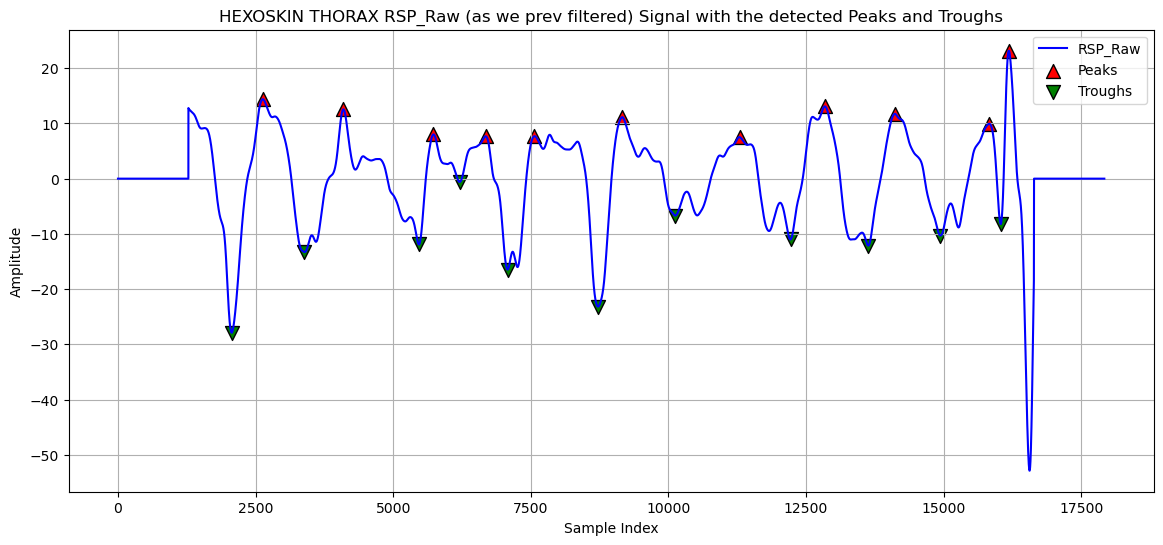

In [115]:
#import the library we will use to plot
import matplotlib.pyplot as plt
plt.figure(figsize=(14, 6))

# plot the "raw" (preivously filtered) hexoskin thorax signal - supine
plt.plot(signals_hexoskin_thorax_8['RSP_Raw'], label="RSP_Raw", color='blue')

# plot a red triangle for when there are detected peaks
if signals_hexoskin_thorax_8['RSP_Peaks'].sum() > 0:  #if at least one peak exists, proceed with plotting
    peak_indices = signals_hexoskin_thorax_8.index[signals_hexoskin_thorax_8['RSP_Peaks'] == 1] #makes an array for the index of each peak
    print(peak_indices)
    plt.scatter(peak_indices, signals_hexoskin_thorax_8.loc[peak_indices, 'RSP_Raw'], color='red', label='Peaks', marker='^', s=100, edgecolor='black') #X is peak indices
                                                                                                                 #Y is the signals value at the index

# plot a green triangle for when there are detected troughs
if signals_hexoskin_thorax_8['RSP_Troughs'].sum() > 0:  #if at least one trough exists, proceed with plotting
    trough_indices = signals_hexoskin_thorax_8.index[signals_hexoskin_thorax_8['RSP_Troughs'] == 1] #makes an array for the index of each trough
    print(trough_indices)
    plt.scatter(trough_indices, signals_hexoskin_thorax_8.loc[trough_indices, 'RSP_Raw'], color='green', label='Troughs', marker='v', s=100, edgecolor='black')

plt.title('HEXOSKIN THORAX RSP_Raw (as we prev filtered) Signal with the detected Peaks and Troughs')
plt.xlabel('Sample Index')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True)
plt.show()


In [116]:
# define a list to store the tidal volume values for each peak
hexoskin_thorax_depths_supine = []

for peak_idx in signals_hexoskin_thorax_8.index[signals_hexoskin_thorax_8['RSP_Peaks'] == 1]: #identify where there are peaks
    # find the preceding trough
    preceding_troughs = signals_hexoskin_thorax_8.index[(signals_hexoskin_thorax_8['RSP_Troughs'] == 1) & (signals_hexoskin_thorax_8.index < peak_idx)] #gives list of all preceding troughs for a given peak
    
    if not preceding_troughs.empty:
        trough_idx = preceding_troughs[-1]  # select the last trough in the list (to get the most recent trough)
        tidal_volume = signals_hexoskin_thorax_8.loc[peak_idx, 'RSP_Raw'] - signals_hexoskin_thorax_8.loc[trough_idx, 'RSP_Raw']  #subtract the value of the give peak from that of the
                                                                                                #preceding trough
        hexoskin_thorax_depths_supine.append(tidal_volume) #the calculated respiratory depths gets appended to the previously created list

# make the tidal volume list a mumpy array
hexoskin_thorax_depths_supine = np.array(hexoskin_thorax_depths_supine)
print(hexoskin_thorax_depths_supine)
print(len(hexoskin_thorax_depths_supine))

[42.2550405  25.82646079 19.92086017  8.25663979 24.11657575 34.27409905
 14.19548267 24.07242201 23.84824449 20.24830162 31.36601346]
11


Index([2576, 4986, 7185, 9292, 12397, 15154, 17744, 20491, 22708, 24986], dtype='int64')
Index([1995, 3330, 5936, 8560, 11478, 13761, 16803, 18641, 21999, 24245], dtype='int64')


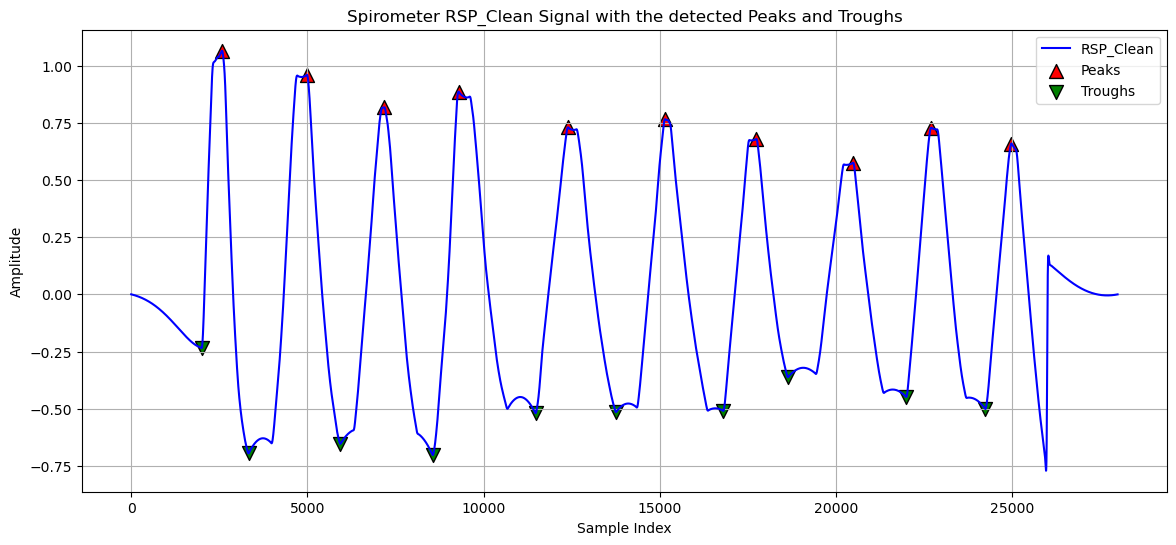

10
Index([2626, 4093, 5729, 6685, 7558, 9155, 11292, 12844, 14109, 15831, 16185], dtype='int64')
Index([2066, 3387, 5469, 6207, 7077, 8721, 10120, 12219, 13633, 14941, 16035], dtype='int64')


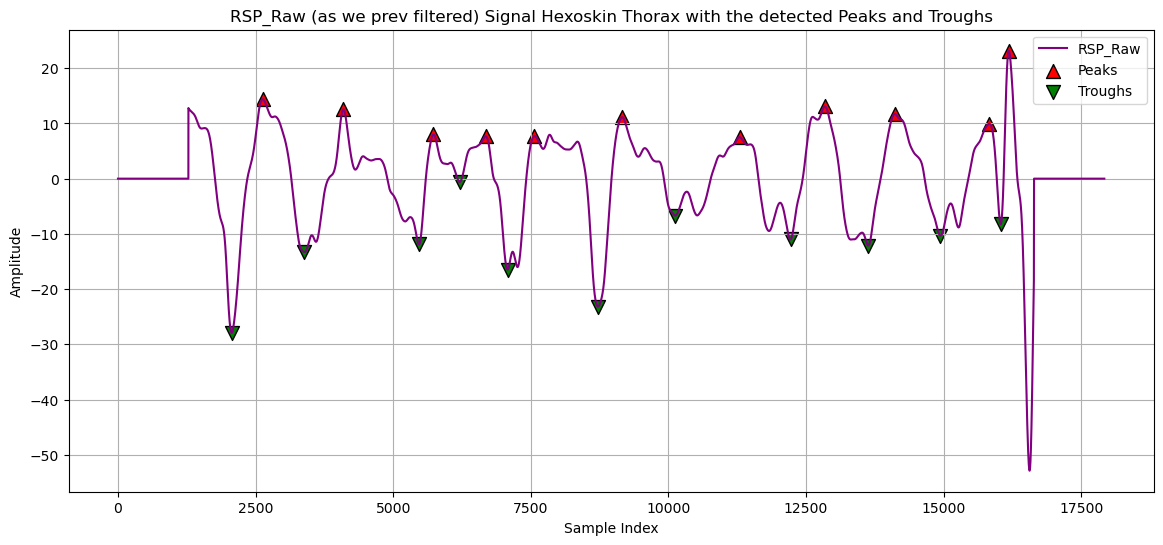

11


In [117]:
#PLOT THE SPIROMETER AGAINST THE HEXOSKIN THORAX - SUPINE

#import the library we will use to plot
import matplotlib.pyplot as plt
plt.figure(figsize=(14, 6))

# plot the cleaned spirometer signal from the signals dataframe - for visualization purposes
plt.plot(signals['RSP_Clean'], label="RSP_Clean", color='blue')

# plot a red triangle for when there are detected peaks
if signals['RSP_Peaks'].sum() > 0:  #if at least one peak exists, proceed with plotting
    peak_indices = signals.index[signals['RSP_Peaks'] == 1] #makes an array for the index of each peak
    print(peak_indices)
    plt.scatter(peak_indices, signals.loc[peak_indices, 'RSP_Clean'], color='red', label='Peaks', marker='^', s=100, edgecolor='black') #X is peak indices
                                                                                                                 #Y is the signals value at the index

# plot a green triangle for when there are detected troughs
if signals['RSP_Troughs'].sum() > 0:  #if at least one trough exists, proceed with plotting
    trough_indices = signals.index[signals['RSP_Troughs'] == 1] #makes an array for the index of each trough
    print(trough_indices)
    plt.scatter(trough_indices, signals.loc[trough_indices, 'RSP_Clean'], color='green', label='Troughs', marker='v', s=100, edgecolor='black')

plt.title('Spirometer RSP_Clean Signal with the detected Peaks and Troughs')
plt.xlabel('Sample Index')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True)
plt.show()
print(len(tv_supine_spiro))


import matplotlib.pyplot as plt
plt.figure(figsize=(14, 6))

# plot the "raw" (previously filtered) hexoskin thorax signal
plt.plot(signals_hexoskin_thorax_8['RSP_Raw'], label="RSP_Raw", color='purple')

# plot a red triangle for when there are detected peaks
if signals_hexoskin_thorax_8['RSP_Peaks'].sum() > 0:  #if at least one peak exists, proceed with plotting
    peak_indices = signals_hexoskin_thorax_8.index[signals_hexoskin_thorax_8['RSP_Peaks'] == 1] #makes an array for the index of each peak
    print(peak_indices)
    plt.scatter(peak_indices, signals_hexoskin_thorax_8.loc[peak_indices, 'RSP_Raw'], color='red', label='Peaks', marker='^', s=100, edgecolor='black') #X is peak indices
                                                                                                                 #Y is the signals value at the index

# plot a green triangle for when there are detected troughs
if signals_hexoskin_thorax_8['RSP_Troughs'].sum() > 0:  #if at least one trough exists, proceed with plotting
    trough_indices = signals_hexoskin_thorax_8.index[signals_hexoskin_thorax_8['RSP_Troughs'] == 1] #makes an array for the index of each trough
    print(trough_indices)
    plt.scatter(trough_indices, signals_hexoskin_thorax_8.loc[trough_indices, 'RSP_Raw'], color='green', label='Troughs', marker='v', s=100, edgecolor='black')

plt.title('RSP_Raw (as we prev filtered) Signal Hexoskin Thorax with the detected Peaks and Troughs')
plt.xlabel('Sample Index')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True)
plt.show()

print(len(hexoskin_thorax_depths_supine))


In [ ]:
#drop the first three cycles from spirometer
#tv_supine_spiro = tv_supine_spiro[3:]
#drop the first cycle from both arrays
#hexoskin_thorax_depths_supine = hexoskin_thorax_depths_supine[1:]
#tv_supine_spiro = tv_supine_spiro[1:]

In [ ]:
#again, drop the first cycle from hexoskin thorax
#hexoskin_thorax_depths_supine = hexoskin_thorax_depths_supine[1:]
#drop the last cycle from spirometer
#tv_supine_spiro = tv_supine_spiro[:-1]

In [118]:
import numpy as np
hexoskin_thorax_depths_supine = np.delete(hexoskin_thorax_depths_supine, 3) #removing the 4th "breath" from hexoskin
#removing the last cycle from hexoskin thorax
hexoskin_thorax_depths_supine = hexoskin_thorax_depths_supine[:-1]

In [119]:
print(len(hexoskin_thorax_depths_supine))
print(len(tv_supine_spiro))

9
10


In [120]:
#drop the first cycle from spirometer
tv_supine_spiro = tv_supine_spiro[1:]

In [121]:
#hexoskin_thorax_depths_supine = hexoskin_thorax_depths_supine[0:len(tv_supine_spiro)]

In [122]:
print(len(hexoskin_thorax_depths_supine))
print(len(tv_supine_spiro))

9
9


In [123]:
#THIS IS FOR RIP - THORAX ONLY CALIBRATION, NOT THE THORACOABDOMINAL CALIBRATION!!
#here we solve for beta (slope and intercept) such that we create a least squares regression of spirometer volume being predicted by
#impedance value times some slope plus an intercept
#specifically, we use the Moore-Penrose pseudoinverse way of solving for the regression coefficients - using the ordinary least squares formula
#under statsmodels give the same answers
import numpy as np

# ensure that the data sets have the same length
assert len(hexoskin_thorax_depths_supine) == len(tv_supine_spiro)
print(hexoskin_thorax_depths_supine)
X = hexoskin_thorax_depths_supine[:, np.newaxis]  # convert impedance to a 2D array, necessary for linear regression in matrix format
print(X)
y = tv_supine_spiro  # spirometer volumes
print(y)

# add a columns of ones to include an intercept in the regression
X = np.column_stack((np.ones(len(hexoskin_thorax_depths_supine)), X))  # Augment X with a column of ones
print(X)

# calculate the pseudoinverse of the matrix X
X_pinv = np.linalg.pinv(X)

# multiply the pseudoinverse of X with the outcome variable y to calculate the slope and intercept
conversion_coefficients_supine = np.dot(X_pinv, y) #dot product function for matrix multiplication
print(conversion_coefficients_supine)

# print the conversion coefficients
hexoskin_thorax_intercept_supine, hexoskin_thorax_slope_supine = conversion_coefficients_supine  #to be saved at the end  of the document
print(f"Conversion coefficients: Intercept = {hexoskin_thorax_intercept_supine}, Slope = {hexoskin_thorax_slope_supine}")


[42.2550405  25.82646079 19.92086017 24.11657575 34.27409905 14.19548267
 24.07242201 23.84824449 20.24830162]
[[42.2550405 ]
 [25.82646079]
 [19.92086017]
 [24.11657575]
 [34.27409905]
 [14.19548267]
 [24.07242201]
 [23.84824449]
 [20.24830162]]
[1.75793892 1.41731778 1.84688199 1.55642605 1.39112541 1.26200905
 1.02277975 1.29152939 1.36358264]
[[ 1.         42.2550405 ]
 [ 1.         25.82646079]
 [ 1.         19.92086017]
 [ 1.         24.11657575]
 [ 1.         34.27409905]
 [ 1.         14.19548267]
 [ 1.         24.07242201]
 [ 1.         23.84824449]
 [ 1.         20.24830162]]
[1.17097712 0.0103638 ]
Conversion coefficients: Intercept = 1.1709771175479218, Slope = 0.010363800315406665


In [124]:
import statsmodels.api as sm 
import pandas as pd          
import matplotlib.pyplot as plt 
import numpy as np
# cross-checking to see if we get the same parameters with the ordinary least squares function
x = hexoskin_thorax_depths_supine
y = tv_supine_spiro
x = sm.add_constant(x)
result = sm.OLS(y, x).fit()
print(result.summary()) #we do get the same findings

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.115
Model:                            OLS   Adj. R-squared:                 -0.012
Method:                 Least Squares   F-statistic:                    0.9059
Date:                Thu, 16 Apr 2026   Prob (F-statistic):              0.373
Time:                        11:36:39   Log-Likelihood:                0.63818
No. Observations:                   9   AIC:                             2.724
Df Residuals:                       7   BIC:                             3.118
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.1710      0.290      4.044      0.0

C:\Users\msa583\AppData\Local\anaconda3\Lib\site-packages\scipy\stats\_axis_nan_policy.py:531: UserWarning: kurtosistest only valid for n>=20 ... continuing anyway, n=9
  res = hypotest_fun_out(*samples, **kwds)


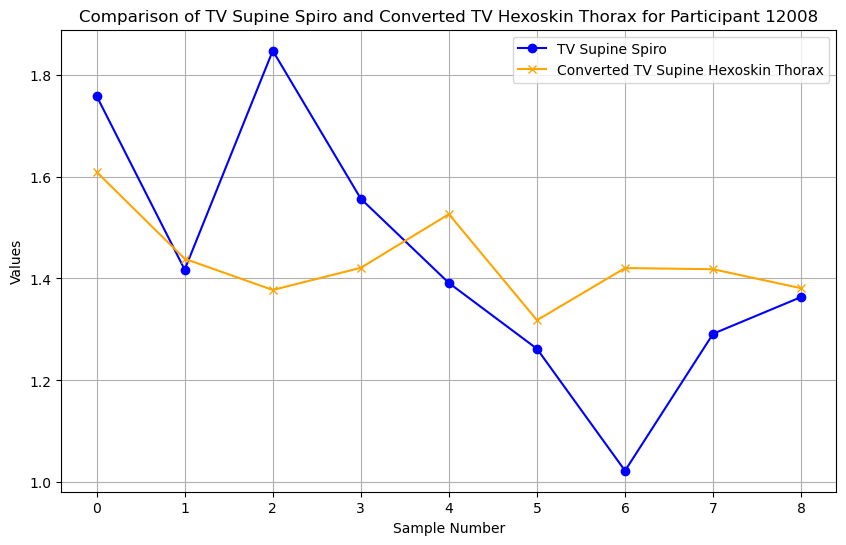

In [125]:
# applying the calculated conversion slope and intercept to the impedance amplitude values
tv_supine_hexoskin_thorax_converted = hexoskin_thorax_depths_supine * hexoskin_thorax_slope_supine + hexoskin_thorax_intercept_supine

plt.figure(figsize=(10, 6))
# plot the actual tidal volumes obtained via spirometer
plt.plot(tv_supine_spiro, label='TV Supine Spiro', color='blue', marker='o')

# plot the calibrated impedance volumes
plt.plot(tv_supine_hexoskin_thorax_converted, label='Converted TV Supine Hexoskin Thorax', color='orange', marker='x')

plt.title(f'Comparison of TV Supine Spiro and Converted TV Hexoskin Thorax for Participant {ppid}')
plt.xlabel('Sample Number')
plt.ylabel('Values')
plt.legend() 
plt.grid()   
plt.show()

In [126]:
tv_supine_hexoskin_thorax_converted = hexoskin_thorax_depths_supine * hexoskin_thorax_slope_supine + hexoskin_thorax_intercept_supine
y = tv_supine_spiro  # spirometer volumes

# calculate mean absolute percentage error (MAPE) for the supine spirometer calibration
hexoskin_thorax_mape_supine = np.mean(np.abs((y - tv_supine_hexoskin_thorax_converted) / (y))) * 100
print(f"mean absolute percentage error (MAPE): {hexoskin_thorax_mape_supine:.4f}%") #to be saved at the end of the script

mean absolute percentage error (MAPE): 12.0233%


In [127]:
#calculate the root mean squared errors (RMSE) for the Hexoskin thorax-only calibration
# calculate squared errors
actual = tv_supine_spiro
predicted = tv_supine_hexoskin_thorax_converted

squared_errors = (actual - predicted) ** 2

# find the mean of squared errors
mse = np.mean(squared_errors)

# take the square root to get RMSE
rmse = np.sqrt(mse)

hexoskin_thorax_rmse_supine = rmse
print("Root Mean Squared Error:", hexoskin_thorax_rmse_supine)

Root Mean Squared Error: 0.22540703785536798


In [128]:
#now, we need to find the amplitudes for hexoskin abdomen using the RSP_Raw of the abdomen hexoskin

#We will start by applying the resp process function on the hexoskin abdomen function and visualizing just to see
import neurokit2 as nk
#implementing the respiratory processing function from neurokit2 to automatically detect the peaks and troughs
signals_hexoskin_abdomen_8, info = nk.rsp_process(hexoskin_abdomen_8, sampling_rate=128)
signals_hexoskin_abdomen_8       #the first output (signals) generates a  dataframe that includes the raw signal values and RSP_Peaks and RSP_Troughs
              #info stores a dictionary with the arrays for the RSP_Peaks, RSP_Troughs, sampling rate

,RSP_Raw,RSP_Clean,RSP_Amplitude,RSP_Rate,RSP_RVT,RSP_Phase,RSP_Phase_Completion,RSP_Symmetry_PeakTrough,RSP_Symmetry_RiseDecay,RSP_Peaks,RSP_Troughs
0,0.0,-0.217341,25.359310,5.722027,0.069274,NaN,0.0,0.727023,0.096774,0,0
1,0.0,-0.217865,25.359310,5.722027,0.069215,NaN,0.0,0.727023,0.096774,0,0
2,0.0,-0.218389,25.359310,5.722027,0.069151,NaN,0.0,0.727023,0.096774,0,0
3,0.0,-0.218914,25.359310,5.722027,0.069082,NaN,0.0,0.727023,0.096774,0,0
4,0.0,-0.219439,25.359310,5.722027,0.069009,NaN,0.0,0.727023,0.096774,0,0
...,...,...,...,...,...,...,...,...,...,...,...
17915,0.0,-0.005448,11.952477,10.336474,0.075788,NaN,0.0,0.795398,0.724092,0,0
17916,0.0,-0.004922,11.952477,10.336474,0.075939,NaN,0.0,0.795398,0.724092,0,0
17917,0.0,-0.004405,11.952477,10.336474,0.076085,NaN,0.0,0.795398,0.724092,0,0
17918,0.0,-0.003902,11.952477,10.336474,0.076229,NaN,0.0,0.795398,0.724092,0,0


Index([1302, 2715, 4052, 5160, 6186, 7831, 9369, 11223, 12701, 14152, 15816,
       16147],
      dtype='int64')
Index([1257, 1722, 3649, 4599, 5480, 7310, 8848, 9950, 12209, 13653, 15278,
       16021],
      dtype='int64')


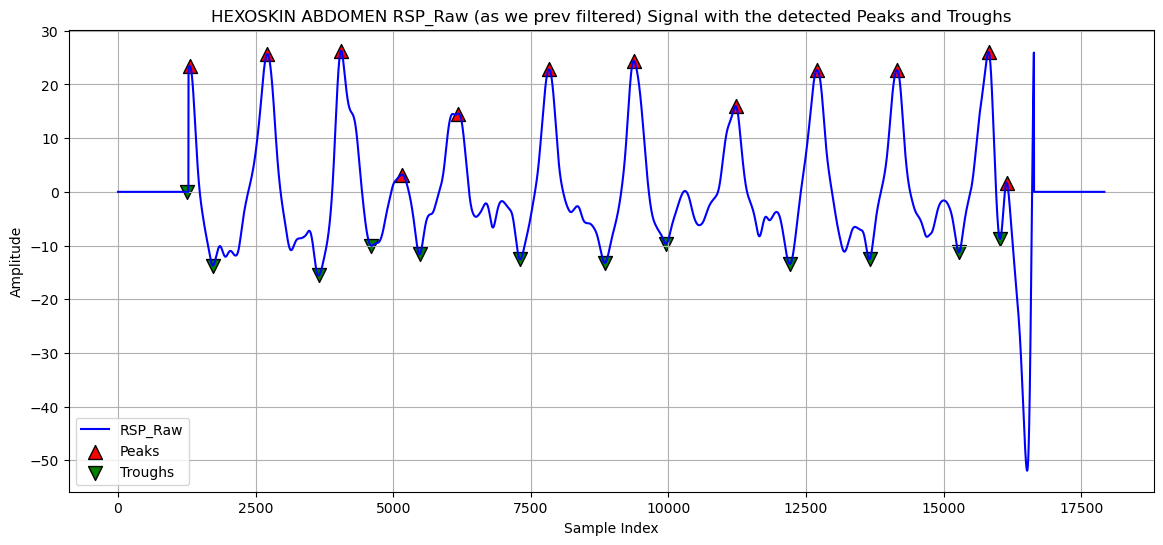

In [129]:
import matplotlib.pyplot as plt
plt.figure(figsize=(14, 6))

# plot the "raw" (preivously filtered) hexoskin abdomen signal
plt.plot(signals_hexoskin_abdomen_8['RSP_Raw'], label="RSP_Raw", color='blue')

# plot a red triangle for when there are detected peaks
if signals_hexoskin_abdomen_8['RSP_Peaks'].sum() > 0:  #if at least one peak exists, proceed with plotting
    peak_indices = signals_hexoskin_abdomen_8.index[signals_hexoskin_abdomen_8['RSP_Peaks'] == 1] #makes an array for the index of each peak
    print(peak_indices)
    plt.scatter(peak_indices, signals_hexoskin_abdomen_8.loc[peak_indices, 'RSP_Raw'], color='red', label='Peaks', marker='^', s=100, edgecolor='black') #X is peak indices
                                                                                                                 #Y is the signals value at the index

# plot a green triangle for when there are detected troughs
if signals_hexoskin_abdomen_8['RSP_Troughs'].sum() > 0:  #if at least one trough exists, proceed with plotting
    trough_indices = signals_hexoskin_abdomen_8.index[signals_hexoskin_abdomen_8['RSP_Troughs'] == 1] #makes an array for the index of each trough
    print(trough_indices)
    plt.scatter(trough_indices, signals_hexoskin_abdomen_8.loc[trough_indices, 'RSP_Raw'], color='green', label='Troughs', marker='v', s=100, edgecolor='black')

plt.title('HEXOSKIN ABDOMEN RSP_Raw (as we prev filtered) Signal with the detected Peaks and Troughs')
plt.xlabel('Sample Index')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True)
plt.show()


In [130]:
# define a list to store the tidal volume values for each peak
hexoskin_abdomen_depths_supine = []

for peak_idx in signals_hexoskin_abdomen_8.index[signals_hexoskin_abdomen_8['RSP_Peaks'] == 1]: #identify where there are peaks
    # find the preceding trough
    preceding_troughs = signals_hexoskin_abdomen_8.index[(signals_hexoskin_abdomen_8['RSP_Troughs'] == 1) & (signals_hexoskin_abdomen_8.index < peak_idx)] #gives list of all preceding troughs for a given peak
    
    if not preceding_troughs.empty:
        trough_idx = preceding_troughs[-1]  # select the last trough in the list (to get the most recent trough)
        tidal_volume = signals_hexoskin_abdomen_8.loc[peak_idx, 'RSP_Raw'] - signals_hexoskin_abdomen_8.loc[trough_idx, 'RSP_Raw']  #subtract the value of the give peak from that of the
                                                                                                #preceding trough
        hexoskin_abdomen_depths_supine.append(tidal_volume) #the calculated respiratory depths gets appended to the previously created list

# make the tidal volume list a mumpy array
hexoskin_abdomen_depths_supine = np.array(hexoskin_abdomen_depths_supine)
print(hexoskin_abdomen_depths_supine)
print(len(hexoskin_abdomen_depths_supine))

[23.43827725 39.40666191 41.83877246 13.21023162 26.19019124 35.36622474
 37.61798096 25.62593797 36.07800602 35.18070006 37.27902213 10.44282371]
12


In [131]:
import numpy as np
hexoskin_abdomen_depths_supine = np.delete(hexoskin_abdomen_depths_supine, 3) #removing the 4th "breath" from hexoskin
#removing the first cycle from hexoskin abdomen
hexoskin_abdomen_depths_supine = hexoskin_abdomen_depths_supine[1:]
#removing the last cycle from hexoskin thorax
hexoskin_abdomen_depths_supine = hexoskin_abdomen_depths_supine[:-1]

In [ ]:
#hexoskin_abdomen_depths_supine = hexoskin_abdomen_depths_supine[1:]

In [132]:
print(tv_supine_spiro)
print(hexoskin_thorax_depths_supine)
print(hexoskin_abdomen_depths_supine)

print(len(tv_supine_spiro))
print(len(hexoskin_thorax_depths_supine))
print(len(hexoskin_abdomen_depths_supine))

[1.75793892 1.41731778 1.84688199 1.55642605 1.39112541 1.26200905
 1.02277975 1.29152939 1.36358264]
[42.2550405  25.82646079 19.92086017 24.11657575 34.27409905 14.19548267
 24.07242201 23.84824449 20.24830162]
[39.40666191 41.83877246 26.19019124 35.36622474 37.61798096 25.62593797
 36.07800602 35.18070006 37.27902213]
9
9
9


In [133]:
import numpy as np
assert len(tv_supine_spiro) == len(hexoskin_thorax_depths_supine) == len(hexoskin_abdomen_depths_supine)

print("TV array (y):")
print(tv_supine_spiro)
print("Thorax array:")
print(hexoskin_thorax_depths_supine)
print("Abdomen array:")
print(hexoskin_abdomen_depths_supine)

# turn predictors into a 2D array
X = np.column_stack((
    hexoskin_thorax_depths_supine,
    hexoskin_abdomen_depths_supine
))
print("\nStep 1: X (thorax and abdomen only)")
print(X)
print("Shape:", X.shape)

# adding a column of ones for the intercept
X = np.column_stack((
    np.ones(len(tv_supine_spiro)),  # intercept
    X
))
print("\nStep 2: X after adding intercept column")
print(X)
print("Shape:", X.shape)

# calculate the pseudoinverse
X_pinv = np.linalg.pinv(X)
print("\nStep 3: Pseudoinverse of X")
print(X_pinv)
print("Shape:", X_pinv.shape)

# product of the pseudoinverse with y to obtain the regression parameters
conversion_coefficients_supine = np.dot(X_pinv, tv_supine_spiro)
twodegrees_intercept_supine, twodegrees_slope_thorax_supine, twodegrees_slope_abdomen_supine = conversion_coefficients_supine

print("\nStep 4: Conversion coefficients")
print(f"Intercept: {twodegrees_intercept_supine}")  #twodegrees stands for two degrees of freedom: one for abdomen, and one for thorax
print(f"Slope Thorax: {twodegrees_slope_thorax_supine}")
print(f"Slope Abdomen: {twodegrees_slope_abdomen_supine}")


TV array (y):
[1.75793892 1.41731778 1.84688199 1.55642605 1.39112541 1.26200905
 1.02277975 1.29152939 1.36358264]
Thorax array:
[42.2550405  25.82646079 19.92086017 24.11657575 34.27409905 14.19548267
 24.07242201 23.84824449 20.24830162]
Abdomen array:
[39.40666191 41.83877246 26.19019124 35.36622474 37.61798096 25.62593797
 36.07800602 35.18070006 37.27902213]

Step 1: X (thorax and abdomen only)
[[42.2550405  39.40666191]
 [25.82646079 41.83877246]
 [19.92086017 26.19019124]
 [24.11657575 35.36622474]
 [34.27409905 37.61798096]
 [14.19548267 25.62593797]
 [24.07242201 36.07800602]
 [23.84824449 35.18070006]
 [20.24830162 37.27902213]]
Shape: (9, 2)

Step 2: X after adding intercept column
[[ 1.         42.2550405  39.40666191]
 [ 1.         25.82646079 41.83877246]
 [ 1.         19.92086017 26.19019124]
 [ 1.         24.11657575 35.36622474]
 [ 1.         34.27409905 37.61798096]
 [ 1.         14.19548267 25.62593797]
 [ 1.         24.07242201 36.07800602]
 [ 1.         23.8482444

In [134]:
import statsmodels.api as sm
#cross-checking with a package to see whether the results are the same
X_sm = sm.add_constant(np.column_stack((
    hexoskin_thorax_depths_supine,
    hexoskin_abdomen_depths_supine
)))
model = sm.OLS(tv_supine_spiro, X_sm).fit()
print(model.summary())


                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.323
Model:                            OLS   Adj. R-squared:                  0.098
Method:                 Least Squares   F-statistic:                     1.433
Date:                Thu, 16 Apr 2026   Prob (F-statistic):              0.310
Time:                        11:39:11   Log-Likelihood:                 1.8481
No. Observations:                   9   AIC:                             2.304
Df Residuals:                       6   BIC:                             2.896
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.8324      0.558      3.285      0.0

C:\Users\msa583\AppData\Local\anaconda3\Lib\site-packages\scipy\stats\_axis_nan_policy.py:531: UserWarning: kurtosistest only valid for n>=20 ... continuing anyway, n=9
  res = hypotest_fun_out(*samples, **kwds)


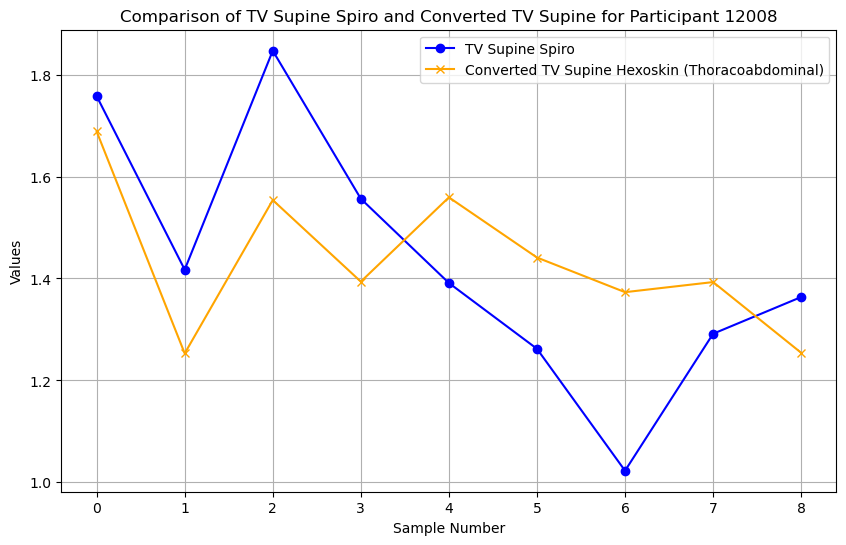

In [135]:
# applying the calculated conversion slope and intercept to the impedance amplitude values
tv_supine_hexoskin_converted = (hexoskin_thorax_depths_supine * twodegrees_slope_thorax_supine) + (hexoskin_abdomen_depths_supine * twodegrees_slope_abdomen_supine) + (twodegrees_intercept_supine) 

plt.figure(figsize=(10, 6))

# plot the actual tidal volumes obtained via spirometer
plt.plot(tv_supine_spiro, label='TV Supine Spiro', color='blue', marker='o')

# plot the calibrated tidal volumes (per two degrees of freedom principle, using both thorax and abdomen breathing belts)
plt.plot(tv_supine_hexoskin_converted, label='Converted TV Supine Hexoskin (Thoracoabdominal)', color='orange', marker='x')

plt.title(f'Comparison of TV Supine Spiro and Converted TV Supine for Participant {ppid}')
plt.xlabel('Sample Number')
plt.ylabel('Values')
plt.legend() 
plt.grid()   
plt.show()

In [136]:
y = tv_supine_spiro  # spirometer volumes
# calculate mean absolute percentage error (MAPE) for the supine spirometer calibration
twodegrees_mape_supine = np.mean(np.abs((y - tv_supine_hexoskin_converted) / (y))) * 100
print(f"mean absolute percentage error (MAPE): {twodegrees_mape_supine:.4f}%") #to be saved at the end of the script

mean absolute percentage error (MAPE): 13.1403%


In [137]:
#calculate the root mean squared errors (RMSE) for the impedance supine calibration
# calculate squared errors
actual = tv_supine_spiro
predicted = tv_supine_hexoskin_converted

squared_errors = (actual - predicted) ** 2

# find the mean of squared errors
mse = np.mean(squared_errors)

# take the square root to get RMSE
rmse = np.sqrt(mse)

twodegrees_rmse_supine = rmse
print("Root Mean Squared Error:", twodegrees_rmse_supine)

Root Mean Squared Error: 0.19705393642848104


In [138]:
#Also calculating a regression for calibrating the Hexoskin abdomen only to spirometer (won't be used in the main analysis but good to have)

#THIS IS FOR RIP - ABDOMEN ONLY CALIBRATION, NOT THE THORACOABDOMINAL CALIBRATION!!
#specifically, we use the Moore-Penrose pseudoinverse way of solving for the regression coefficients - using the ordinary least squares formula
#under statsmodels give the same answers
import numpy as np

# ensure that the data sets have the same length
assert len(hexoskin_abdomen_depths_supine) == len(tv_supine_spiro)
print(hexoskin_abdomen_depths_supine)
X = hexoskin_abdomen_depths_supine[:, np.newaxis]  # convert impedance to a 2D array, necessary for linear regression in matrix format
print(X)
y = tv_supine_spiro  # spirometer volumes
print(y)

# add a columns of ones to include an intercept in the regression
X = np.column_stack((np.ones(len(hexoskin_abdomen_depths_supine)), X))  # Augment X with a column of ones
print(X)

# calculate the pseudoinverse of the matrix X
X_pinv = np.linalg.pinv(X)

# multiply the pseudoinverse of X with the outcome variable y to calculate the slope and intercept
conversion_coefficients_supine = np.dot(X_pinv, y) #dot product function for matrix multiplication
print(conversion_coefficients_supine)

# print the conversion coefficients
hexoskin_abdomen_intercept_supine, hexoskin_abdomen_slope_supine = conversion_coefficients_supine  #to be saved at the end  of the document
print(f"Conversion coefficients: Intercept = {hexoskin_abdomen_intercept_supine}, Slope = {hexoskin_abdomen_slope_supine}")


[39.40666191 41.83877246 26.19019124 35.36622474 37.61798096 25.62593797
 36.07800602 35.18070006 37.27902213]
[[39.40666191]
 [41.83877246]
 [26.19019124]
 [35.36622474]
 [37.61798096]
 [25.62593797]
 [36.07800602]
 [35.18070006]
 [37.27902213]]
[1.75793892 1.41731778 1.84688199 1.55642605 1.39112541 1.26200905
 1.02277975 1.29152939 1.36358264]
[[ 1.         39.40666191]
 [ 1.         41.83877246]
 [ 1.         26.19019124]
 [ 1.         35.36622474]
 [ 1.         37.61798096]
 [ 1.         25.62593797]
 [ 1.         36.07800602]
 [ 1.         35.18070006]
 [ 1.         37.27902213]]
[ 1.63532533 -0.00574835]
Conversion coefficients: Intercept = 1.6353253335972817, Slope = -0.005748353115476487


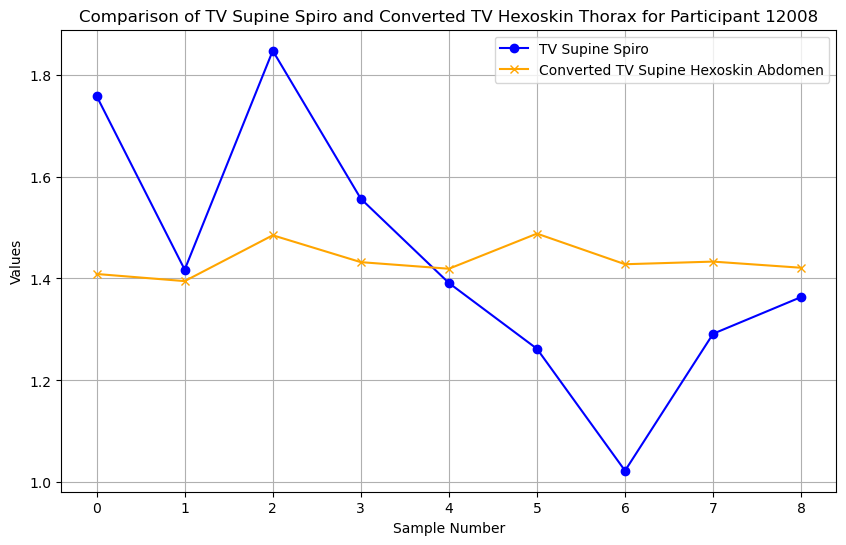

In [139]:
# applying the calculated conversion slope and intercept to the impedance amplitude values
tv_supine_hexoskin_abdomen_converted = (hexoskin_abdomen_depths_supine * hexoskin_abdomen_slope_supine) + (hexoskin_abdomen_intercept_supine)

plt.figure(figsize=(10, 6))
# plot the actual tidal volumes obtained via spirometer
plt.plot(tv_supine_spiro, label='TV Supine Spiro', color='blue', marker='o')

# plot the calibrated impedance volumes
plt.plot(tv_supine_hexoskin_abdomen_converted, label='Converted TV Supine Hexoskin Abdomen', color='orange', marker='x')

plt.title(f'Comparison of TV Supine Spiro and Converted TV Hexoskin Thorax for Participant {ppid}')
plt.xlabel('Sample Number')
plt.ylabel('Values')
plt.legend() 
plt.grid()   
plt.show()

In [140]:
y = tv_supine_spiro  # spirometer volumes

# calculate mean absolute percentage error (MAPE) for the supine spirometer calibration
hexoskin_abdomen_mape_supine = np.mean(np.abs((y - tv_supine_hexoskin_abdomen_converted) / (y))) * 100
print(f"mean absolute percentage error (MAPE): {hexoskin_abdomen_mape_supine:.4f}%") #to be saved at the end of the script

mean absolute percentage error (MAPE): 13.7503%


In [141]:
#calculate the root mean squared errors (RMSE) for the Hexoskin abdomen-only calibration
# calculate squared errors
actual = tv_supine_spiro
predicted = tv_supine_hexoskin_abdomen_converted

squared_errors = (actual - predicted) ** 2

# find the mean of squared errors
mse = np.mean(squared_errors)

# take the square root to get RMSE
rmse = np.sqrt(mse)

hexoskin_abdomen_rmse_supine = rmse
print("Root Mean Squared Error:", hexoskin_abdomen_rmse_supine)

Root Mean Squared Error: 0.2376631526119618


## SITTING

### READING IN SPIROMETER

In [142]:
#reading the supine csv recording from the spirometer
volume_sitting = pd.read_csv(f'sitting_{ppid}.csv')
#viewing the dataframe
volume_sitting.head()

,Data Set 1:Time(s),Data Set 1:Flow Rate(L/s),Data Set 1:Volume(L),Data Set 2:Time(s),Data Set 2:Flow Rate(L/s),Data Set 2:Volume(L),Data Set 3:Time(s),Data Set 3:Flow Rate(L/s),Data Set 3:Volume(L)
0,0.000,0.0,0.0,0.000,-0.331608,0.0,0.000,0.585815,0.000000
1,0.005,0.0,0.0,0.005,-0.331608,0.0,0.005,0.588038,-0.003090
2,0.010,0.0,0.0,0.010,-0.331608,0.0,0.010,0.588038,-0.006180
3,0.015,0.0,0.0,0.015,-0.328198,0.0,0.015,0.588038,-0.009270
4,0.020,0.0,0.0,0.020,-0.324762,0.0,0.020,0.588038,-0.012361


In [143]:
#the dataframe also has the flow rate and time but we are not interested in those, so selecting the tidal volume column
spirometer_sitting = volume_sitting['Data Set 3:Volume(L)'] #here, you might need to change the number of the data set

#converting the data format from float64 to numpy array format for later peak valley detection using neurokit2
spirometer_sitting = np.array(spirometer_sitting)

# only select the first 120 seconds of the signal (the first 2400 rows due to the sampling rate being 200)
spirometer_sitting = spirometer_sitting[:24000]

#doing zero padding of 10 seconds (signal sampling rate was 200 Hz) to the beginning and ending of the signal
spirometer_sitting = np.concatenate([np.zeros(2000), spirometer_sitting, np.zeros(2000)])
print(spirometer_sitting)

[0. 0. 0. ... 0. 0. 0.]


In [144]:
import neurokit2 as nk
#implementing the respiratory processing function from neurokit2 to automatically detect the peaks and troughs
signals, info = nk.rsp_process(spirometer_sitting, sampling_rate=200)
signals       #the first output (signals) generates a  dataframe that includes the raw signal values and RSP_Peaks and RSP_Troughs
              #info stores a dictionary with the arrays for the RSP_Peaks, RSP_Troughs, sampling rate

,RSP_Raw,RSP_Clean,RSP_Amplitude,RSP_Rate,RSP_RVT,RSP_Phase,RSP_Phase_Completion,RSP_Symmetry_PeakTrough,RSP_Symmetry_RiseDecay,RSP_Peaks,RSP_Troughs
0,0.0,-0.052521,1.486128,4.825818,0.006234,NaN,0.0,0.539648,0.582589,0,0
1,0.0,-0.052527,1.486128,4.825818,0.006234,NaN,0.0,0.539648,0.582589,0,0
2,0.0,-0.052532,1.486128,4.825818,0.006235,NaN,0.0,0.539648,0.582589,0,0
3,0.0,-0.052538,1.486128,4.825818,0.006236,NaN,0.0,0.539648,0.582589,0,0
4,0.0,-0.052543,1.486128,4.825818,0.006237,NaN,0.0,0.539648,0.582589,0,0
...,...,...,...,...,...,...,...,...,...,...,...
27995,0.0,-0.001940,2.184777,5.398111,0.003184,NaN,0.0,0.561072,0.342780,0,0
27996,0.0,-0.001708,2.184777,5.398111,0.003192,NaN,0.0,0.561072,0.342780,0,0
27997,0.0,-0.001491,2.184777,5.398111,0.003201,NaN,0.0,0.561072,0.342780,0,0
27998,0.0,-0.001287,2.184777,5.398111,0.003209,NaN,0.0,0.561072,0.342780,0,0


Index([4017, 6335, 8741, 11654, 14185, 16583, 19051, 21144, 23333], dtype='int64')
Index([2712, 4952, 7648, 9953, 12667, 15264, 17626, 20382, 22605], dtype='int64')


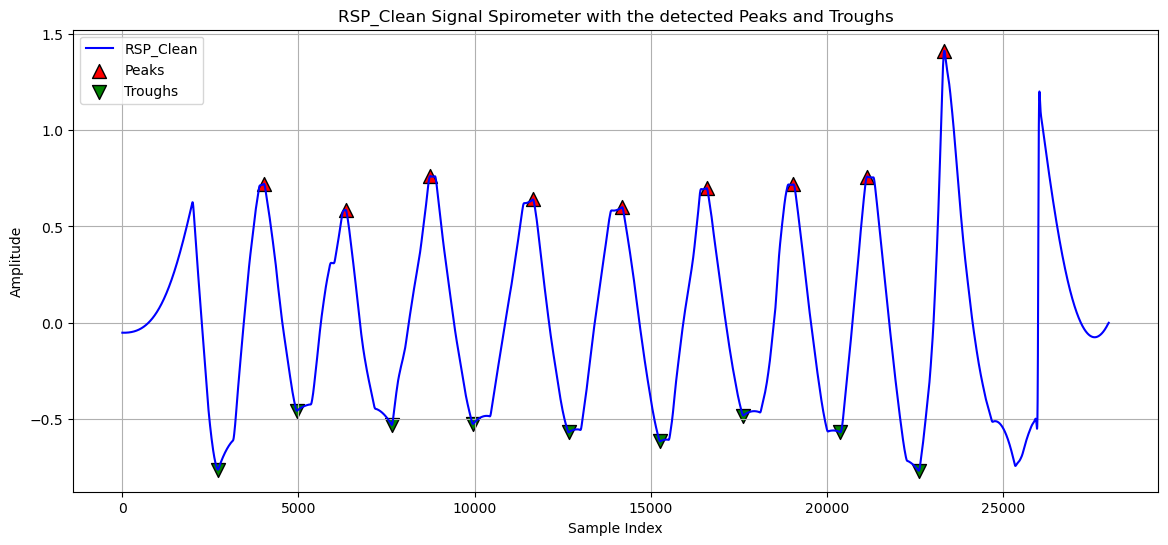

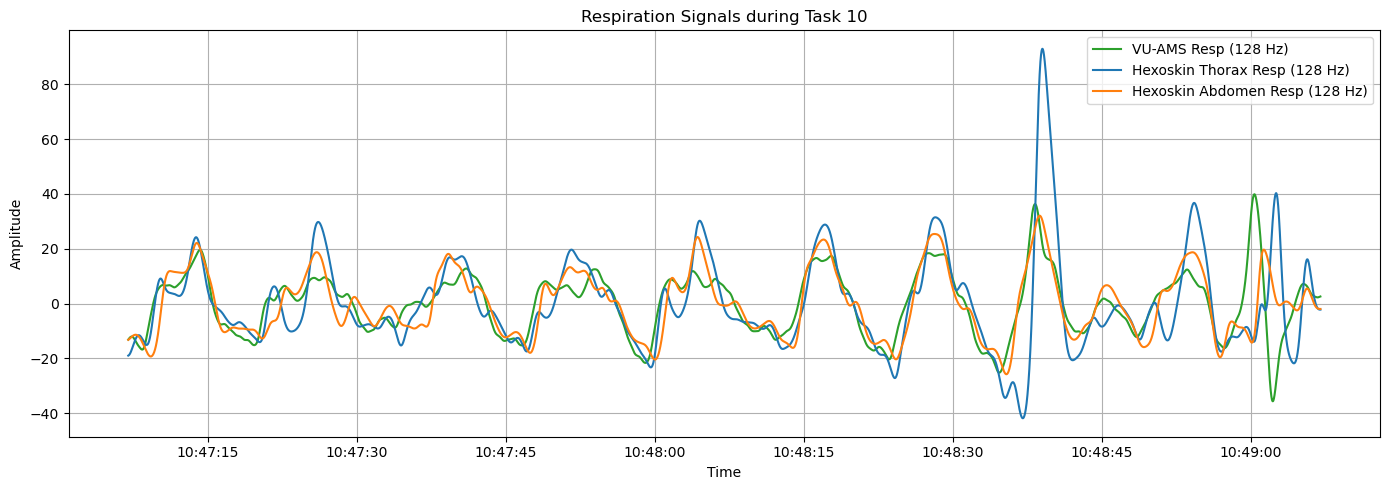

In [145]:
import matplotlib.pyplot as plt
plt.figure(figsize=(14, 6))

# plot the spirometer signal from the signals dataframe - again, plotting the cleaned just for the visualization (TV calculation will happen with raw)
plt.plot(signals['RSP_Clean'], label="RSP_Clean", color='blue') #note that the signals now represents the dataframe for the sitting spirometer signal
                                                                #overwrote the the supine spirometer
# plot a red triangle for when there are detected peaks
if signals['RSP_Peaks'].sum() > 0:  #if at least one peak exists, proceed with plotting
    peak_indices = signals.index[signals['RSP_Peaks'] == 1] #makes an array for the index of each peak
    print(peak_indices)
    plt.scatter(peak_indices, signals.loc[peak_indices, 'RSP_Clean'], color='red', label='Peaks', marker='^', s=100, edgecolor='black') #X is peak indices
                                                                                                                 #Y is the signals value at the index

# plot a green triangle for when there are detected troughs
if signals['RSP_Troughs'].sum() > 0:  #if at least one trough exists, proceed with plotting
    trough_indices = signals.index[signals['RSP_Troughs'] == 1] #makes an array for the index of each trough
    print(trough_indices)
    plt.scatter(trough_indices, signals.loc[trough_indices, 'RSP_Clean'], color='green', label='Troughs', marker='v', s=100, edgecolor='black')

plt.title('RSP_Clean Signal Spirometer with the detected Peaks and Troughs')
plt.xlabel('Sample Index')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True)
plt.show()


tasks_to_plot = [10] #plot the three respiration signals together for the sitting spirometer calibration task

for task in tasks_to_plot:
    # Filter each signal's DataFrame for the current task
    vuams_task = vuams_df[vuams_df["Label"] == task]
    thorax_task = hexoskin_thorax_df[hexoskin_thorax_df["Label"] == task]
    abdomen_task = hexoskin_abdomen_df[hexoskin_abdomen_df["Label"] == task]

    plt.figure(figsize=(14, 5))
    plt.plot(vuams_task.index, vuams_task["signal"], label="VU-AMS Resp (128 Hz)", color='tab:green')
    plt.plot(thorax_task.index, thorax_task["signal"], label="Hexoskin Thorax Resp (128 Hz)", color='tab:blue')
    plt.plot(abdomen_task.index, abdomen_task["signal"], label="Hexoskin Abdomen Resp (128 Hz)", color='tab:orange')

    plt.title(f"Respiration Signals during Task {task}")
    plt.xlabel("Time")
    plt.ylabel("Amplitude")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()
#if the signal overlap does not make direct sense, open the gambl file (spirometer recording) in which you can clearly see whether there was a 
#straight line perhaps for the first few cycles and get more understanding of the data for a correct matching

In [146]:
# define a list to store the tidal volume values (spirometer) for each peak
tidal_volumes_sitting = []

for peak_idx in signals.index[signals['RSP_Peaks'] == 1]: #identify where there are peaks
    # find the preceding trough
    preceding_troughs = signals.index[(signals['RSP_Troughs'] == 1) & (signals.index < peak_idx)] #gives list of all preceding troughs for a given peak
    
    if not preceding_troughs.empty:
        trough_idx = preceding_troughs[-1]  # select the last trough in the list (to get the most recent trough)
        tidal_volume = signals.loc[peak_idx, 'RSP_Raw'] - signals.loc[trough_idx, 'RSP_Raw']  #subtract the value of the give peak from that of the
                                                                                                #preceding trough
        tidal_volumes_sitting.append(tidal_volume) #the calculated tidal volume gets appended to the previously created list

# make the tidal volume list a mumpy array
tv_sitting_spiro = np.array(tidal_volumes_sitting)
print(tv_sitting_spiro)
print(len(tv_sitting_spiro))


[1.27993274 1.0093745  1.62991658 1.21372396 1.23830032 1.39481544
 1.27578878 1.42059994 2.34556323]
9


### CALIBRATING VUAMS RESPIRATION

In [147]:
import neurokit2 as nk
#implementing the respiratory processing function from neurokit2 to automatically detect the peaks and troughs
signals_vuams_10, info = nk.rsp_process(vuams_resp_10, sampling_rate=128)
signals_vuams_10       #the first output (signals) generates a  dataframe that includes the raw signal values and RSP_Peaks and RSP_Troughs
              #info stores a dictionary with the arrays for the RSP_Peaks, RSP_Troughs, sampling rate

,RSP_Raw,RSP_Clean,RSP_Amplitude,RSP_Rate,RSP_RVT,RSP_Phase,RSP_Phase_Completion,RSP_Symmetry_PeakTrough,RSP_Symmetry_RiseDecay,RSP_Peaks,RSP_Troughs
0,0.0,0.133932,34.571489,5.510116,0.055001,NaN,0.0,0.361459,0.517337,0,0
1,0.0,0.134633,34.571489,5.510116,0.055130,NaN,0.0,0.361459,0.517337,0,0
2,0.0,0.135334,34.571489,5.510116,0.055256,NaN,0.0,0.361459,0.517337,0,0
3,0.0,0.136038,34.571489,5.510116,0.055379,NaN,0.0,0.361459,0.517337,0,0
4,0.0,0.136743,34.571489,5.510116,0.055500,NaN,0.0,0.361459,0.517337,0,0
...,...,...,...,...,...,...,...,...,...,...,...
17915,0.0,-0.003841,56.753946,6.814552,0.029424,NaN,0.0,0.326568,0.574978,0,0
17916,0.0,-0.003445,56.753946,6.814552,0.029509,NaN,0.0,0.326568,0.574978,0,0
17917,0.0,-0.003063,56.753946,6.814552,0.029594,NaN,0.0,0.326568,0.574978,0,0
17918,0.0,-0.002695,56.753946,6.814552,0.029678,NaN,0.0,0.326568,0.574978,0,0


Index([2208, 3808, 5637, 7301, 8553, 10336, 11589, 12962, 13851, 14921, 15789], dtype='int64')
Index([1462, 2904, 4367, 6352, 7944, 9624, 11085, 12503, 13574, 14273, 15400], dtype='int64')


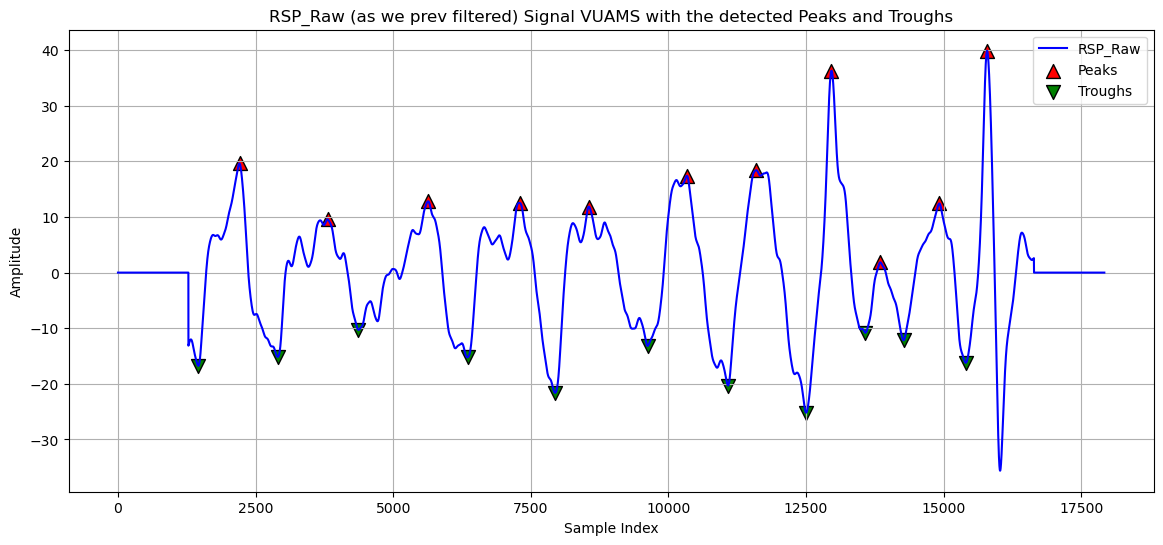

In [148]:
#import the library we will use to plot
import matplotlib.pyplot as plt
plt.figure(figsize=(14, 6))

# plot the "raw" VUAMS signal from the signals dataframe
plt.plot(signals_vuams_10['RSP_Raw'], label="RSP_Raw", color='blue')

# plot a red triangle for when there are detected peaks
if signals_vuams_10['RSP_Peaks'].sum() > 0:  #if at least one peak exists, proceed with plotting
    peak_indices = signals_vuams_10.index[signals_vuams_10['RSP_Peaks'] == 1] #makes an array for the index of each peak
    print(peak_indices)
    plt.scatter(peak_indices, signals_vuams_10.loc[peak_indices, 'RSP_Raw'], color='red', label='Peaks', marker='^', s=100, edgecolor='black') #X is peak indices
                                                                                                                 #Y is the signals value at the index

# plot a green triangle for when there are detected troughs
if signals_vuams_10['RSP_Troughs'].sum() > 0:  #if at least one trough exists, proceed with plotting
    trough_indices = signals_vuams_10.index[signals_vuams_10['RSP_Troughs'] == 1] #makes an array for the index of each trough
    print(trough_indices)
    plt.scatter(trough_indices, signals_vuams_10.loc[trough_indices, 'RSP_Raw'], color='green', label='Troughs', marker='v', s=100, edgecolor='black')

plt.title('RSP_Raw (as we prev filtered) Signal VUAMS with the detected Peaks and Troughs')
plt.xlabel('Sample Index')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True)
plt.show()


In [149]:
# define a list to store the tidal volume values for each peak
vuams_depths_sitting = []

for peak_idx in signals_vuams_10.index[signals_vuams_10['RSP_Peaks'] == 1]: #identify where there are peaks
    # find the preceding trough
    preceding_troughs = signals_vuams_10.index[(signals_vuams_10['RSP_Troughs'] == 1) & (signals_vuams_10.index < peak_idx)] #gives list of all preceding troughs for a given peak
    
    if not preceding_troughs.empty:
        trough_idx = preceding_troughs[-1]  # select the last trough in the list (to get the most recent trough)
        tidal_volume = signals_vuams_10.loc[peak_idx, 'RSP_Raw'] - signals_vuams_10.loc[trough_idx, 'RSP_Raw']  #subtract the value of the give peak from that of the
                                                                                                #preceding trough
        vuams_depths_sitting.append(tidal_volume) #the calculated respiratory depths gets appended to the previously created list

# make the tidal volume list a mumpy array
vuams_depths_sitting = np.array(vuams_depths_sitting)
print(vuams_depths_sitting)
print(len(vuams_depths_sitting))

[36.3780929  24.73935261 23.09930999 27.74398154 33.47464672 30.58307317
 38.70010764 61.48185974 12.63193172 24.59029573 56.11023498]
11


Index([4017, 6335, 8741, 11654, 14185, 16583, 19051, 21144, 23333], dtype='int64')
Index([2712, 4952, 7648, 9953, 12667, 15264, 17626, 20382, 22605], dtype='int64')


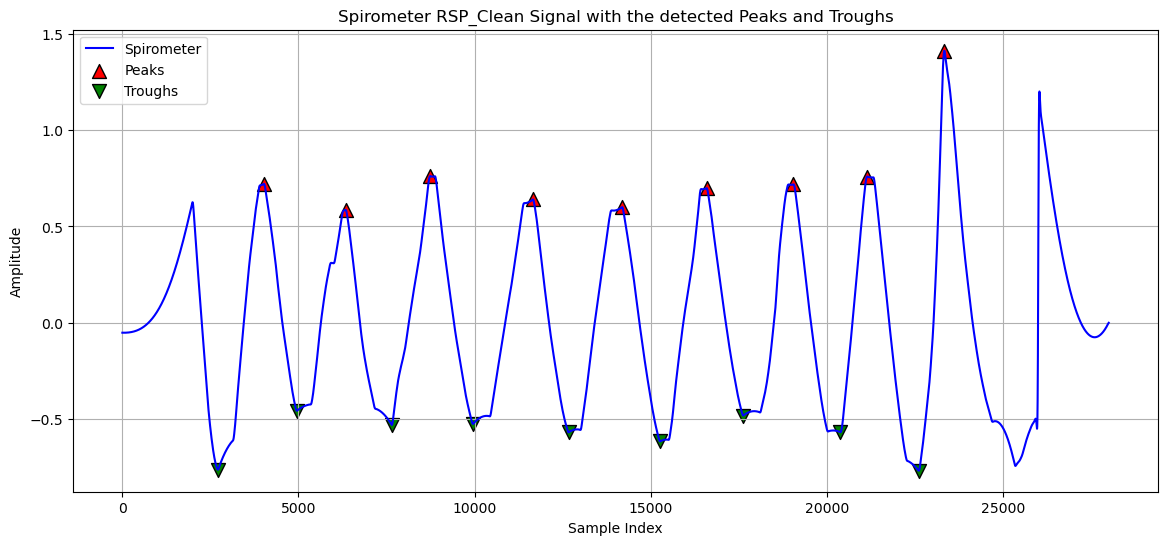

9
Index([2208, 3808, 5637, 7301, 8553, 10336, 11589, 12962, 13851, 14921, 15789], dtype='int64')
Index([1462, 2904, 4367, 6352, 7944, 9624, 11085, 12503, 13574, 14273, 15400], dtype='int64')


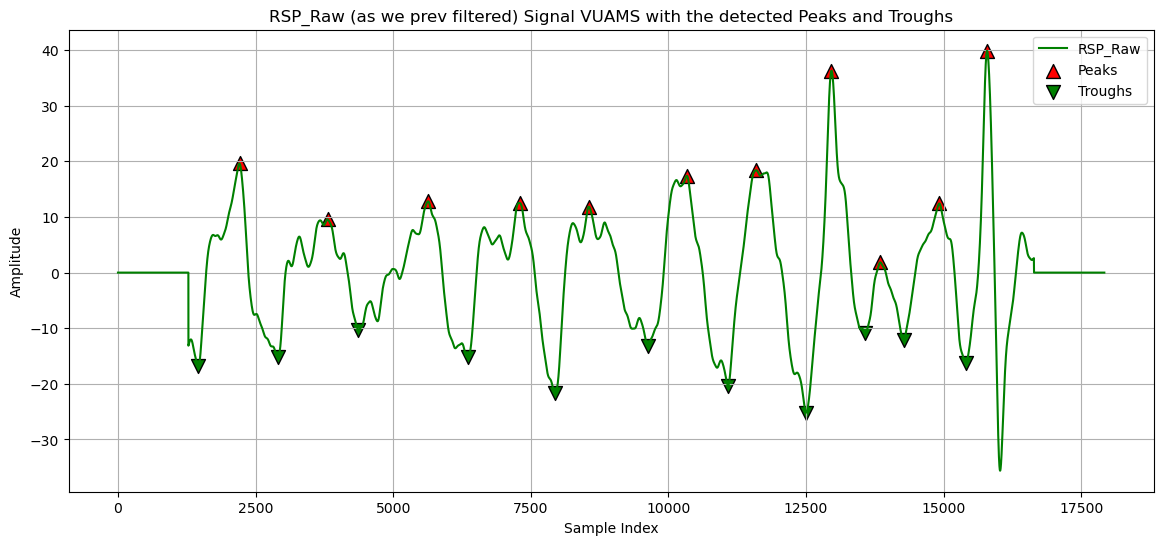

11


In [150]:
#PLOT THE SPIROMETER AND THE IMPEDANCE - SITTING

#import the library we will use to plot
import matplotlib.pyplot as plt
plt.figure(figsize=(14, 6))

# plot the cleaned spirometer signal from the signals dataframe
plt.plot(signals['RSP_Clean'], label="Spirometer", color='blue')

# plot a red triangle for when there are detected peaks
if signals['RSP_Peaks'].sum() > 0:  #if at least one peak exists, proceed with plotting
    peak_indices = signals.index[signals['RSP_Peaks'] == 1] #makes an array for the index of each peak
    print(peak_indices)
    plt.scatter(peak_indices, signals.loc[peak_indices, 'RSP_Clean'], color='red', label='Peaks', marker='^', s=100, edgecolor='black') #X is peak indices
                                                                                                                 #Y is the signals value at the index
# plot a green triangle for when there are detected troughs
if signals['RSP_Troughs'].sum() > 0:  #if at least one trough exists, proceed with plotting
    trough_indices = signals.index[signals['RSP_Troughs'] == 1] #makes an array for the index of each trough
    print(trough_indices)
    plt.scatter(trough_indices, signals.loc[trough_indices, 'RSP_Clean'], color='green', label='Troughs', marker='v', s=100, edgecolor='black')

plt.title('Spirometer RSP_Clean Signal with the detected Peaks and Troughs')
plt.xlabel('Sample Index')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True)
plt.show()

print(len(tv_sitting_spiro))


#import the library we will use to plot
import matplotlib.pyplot as plt
plt.figure(figsize=(14, 6))

# plot the "raw" vuams signal - sitting
plt.plot(signals_vuams_10['RSP_Raw'], label="RSP_Raw", color='green')

# plot a red triangle for when there are detected peaks
if signals_vuams_10['RSP_Peaks'].sum() > 0:  #if at least one peak exists, proceed with plotting
    peak_indices = signals_vuams_10.index[signals_vuams_10['RSP_Peaks'] == 1] #makes an array for the index of each peak
    print(peak_indices)
    plt.scatter(peak_indices, signals_vuams_10.loc[peak_indices, 'RSP_Raw'], color='red', label='Peaks', marker='^', s=100, edgecolor='black') #X is peak indices
                                                                                                                 #Y is the signals value at the index

# plot a green triangle for when there are detected troughs
if signals_vuams_10['RSP_Troughs'].sum() > 0:  #if at least one trough exists, proceed with plotting
    trough_indices = signals_vuams_10.index[signals_vuams_10['RSP_Troughs'] == 1] #makes an array for the index of each trough
    print(trough_indices)
    plt.scatter(trough_indices, signals_vuams_10.loc[trough_indices, 'RSP_Raw'], color='green', label='Troughs', marker='v', s=100, edgecolor='black')

plt.title('RSP_Raw (as we prev filtered) Signal VUAMS with the detected Peaks and Troughs')
plt.xlabel('Sample Index')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True)
plt.show()

print(len(vuams_depths_sitting))

In [ ]:
#remove the last five cycles from vuams 
#vuams_depths_sitting = vuams_depths_sitting[:-5]
#remove the first six cycles from spirometer
#tv_sitting_spiro = tv_sitting_spiro[6:]

In [ ]:
#remove the last cycle from both
#vuams_depths_sitting = vuams_depths_sitting[:-1]
#tv_sitting_spiro = tv_sitting_spiro[:-1]

In [ ]:
#remove the last cycle in the spirometer
#tv_sitting_spiro = tv_sitting_spiro[:-1]

In [151]:
#drop the first cycle in spirometer
tv_sitting_spiro = tv_sitting_spiro[1:]
#drop the last three cycles in vuams
vuams_depths_sitting = vuams_depths_sitting[:-3]

In [152]:
print(len(vuams_depths_sitting))
print(len(tv_sitting_spiro)) #ok, also approved they have the same length

8
8


In [153]:
#here we solve for beta (slope and intercept) such that we create a least squares regression of spirometer volume being predicted by
#impedance value times some slope plus an intercept

#specifically, we use the Moore-Penrose pseudoinverse way of solving for the regression coefficients - using the ordinary least squares formula
#under statsmodels give the same answers
import numpy as np

assert len(vuams_depths_sitting) == len(tv_sitting_spiro) #ensuring the arrays have the same length once again
print(vuams_depths_sitting)
X = vuams_depths_sitting[:, np.newaxis]  # convert impedance to a 2D array, necessary for linear regression in matrix format
print(X)
y = tv_sitting_spiro  # spirometer volumes
print(y)

# add a columns of ones to include an intercept in the regression
X = np.column_stack((np.ones(len(vuams_depths_sitting)), X))  # Augment X with a column of ones
print(X)

# calculate the pseudoinverse of the matrix X
X_pinv = np.linalg.pinv(X)

# multiply the pseudoinverse of X with the outcome variable y to calculate the slope and intercept
conversion_coefficients_sitting = np.dot(X_pinv, y) #dot product function for matrix multiplication
print(conversion_coefficients_sitting)

# print the conversion coefficients
vuams_intercept_sitting, vuams_slope_sitting = conversion_coefficients_sitting  
print(f"Conversion coefficients: Intercept = {vuams_intercept_sitting}, Slope = {vuams_slope_sitting}") #to be saved at the end  of the document


[36.3780929  24.73935261 23.09930999 27.74398154 33.47464672 30.58307317
 38.70010764 61.48185974]
[[36.3780929 ]
 [24.73935261]
 [23.09930999]
 [27.74398154]
 [33.47464672]
 [30.58307317]
 [38.70010764]
 [61.48185974]]
[1.0093745  1.62991658 1.21372396 1.23830032 1.39481544 1.27578878
 1.42059994 2.34556323]
[[ 1.         36.3780929 ]
 [ 1.         24.73935261]
 [ 1.         23.09930999]
 [ 1.         27.74398154]
 [ 1.         33.47464672]
 [ 1.         30.58307317]
 [ 1.         38.70010764]
 [ 1.         61.48185974]]
[0.56423103 0.02539545]
Conversion coefficients: Intercept = 0.5642310279665317, Slope = 0.02539545169617284


In [154]:
import statsmodels.api as sm 
import pandas as pd          
import matplotlib.pyplot as plt 
import numpy as np
# cross-checking to see if we get the same parameters with the ordinary least squares function
x = vuams_depths_sitting
y = tv_sitting_spiro
x = sm.add_constant(x)
result = sm.OLS(y, x).fit()
print(result.summary()) #we do get the same findings

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.575
Model:                            OLS   Adj. R-squared:                  0.504
Method:                 Least Squares   F-statistic:                     8.113
Date:                Thu, 16 Apr 2026   Prob (F-statistic):             0.0292
Time:                        11:44:31   Log-Likelihood:               -0.21580
No. Observations:                   8   AIC:                             4.432
Df Residuals:                       6   BIC:                             4.590
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.5642      0.324      1.741      0.1

C:\Users\msa583\AppData\Local\anaconda3\Lib\site-packages\scipy\stats\_axis_nan_policy.py:531: UserWarning: kurtosistest only valid for n>=20 ... continuing anyway, n=8
  res = hypotest_fun_out(*samples, **kwds)


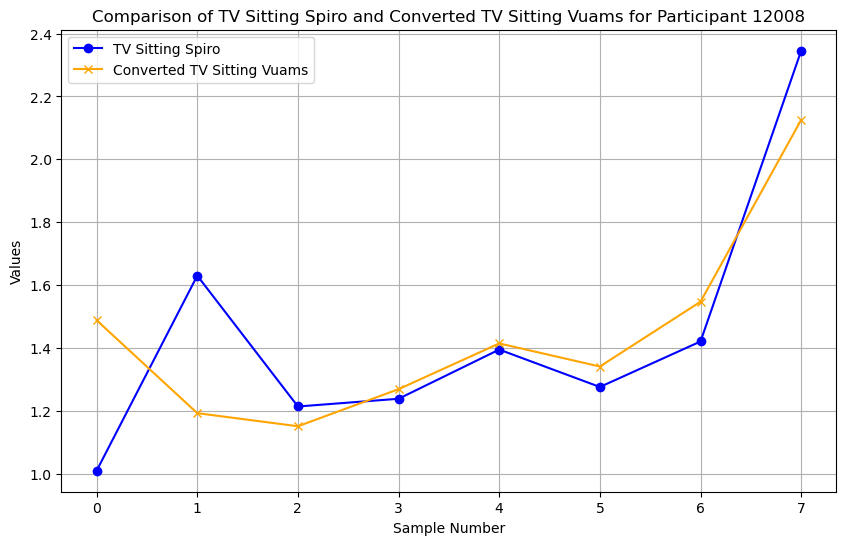

In [155]:
# applying the calculated conversion slope and intercept to the impedance amplitude values
tv_sitting_vuams_converted = (vuams_depths_sitting * vuams_slope_sitting) + (vuams_intercept_sitting)

plt.figure(figsize=(10, 6))

# plot the actual tidal volumes obtained via spirometer
plt.plot(tv_sitting_spiro, label='TV Sitting Spiro', color='blue', marker='o')

# plot the calibrated impedance volumes
plt.plot(tv_sitting_vuams_converted, label='Converted TV Sitting Vuams', color='orange', marker='x')

plt.title(f'Comparison of TV Sitting Spiro and Converted TV Sitting Vuams for Participant {ppid}')
plt.xlabel('Sample Number')
plt.ylabel('Values')
plt.legend() 
plt.grid()   
plt.show()

In [156]:
y = tv_sitting_spiro  # spirometer volumes

# calculate mean absolute percentage error (MAPE) for the supine spirometer calibration
vuams_mape_sitting = np.mean(np.abs((y - tv_sitting_vuams_converted) / (y))) * 100
print(f"mean absolute percentage error (MAPE): {vuams_mape_sitting:.4f}%") #to be saved at the end of the script

mean absolute percentage error (MAPE): 13.3359%


In [157]:
#calculate the root mean squared errors (RMSE) for the impedance supine calibration
# calculate squared errors
actual = tv_sitting_spiro
predicted = tv_sitting_vuams_converted

squared_errors = (actual - predicted) ** 2

# find the mean of squared errors
mse = np.mean(squared_errors)

# take the square root to get RMSE
rmse = np.sqrt(mse)

vuams_rmse_sitting = rmse
print("Root Mean Squared Error:", vuams_rmse_sitting)

Root Mean Squared Error: 0.24858660171536712


### CALIBRATING HEXOSKIN RESPIRATION

In [158]:
# Repeating the sitting spirometer peak-valley detection and amplitude calculation from the start (same as done for VUAMS)
#the dataframe also has the flow rate and time but we are not interested in those, so selecting the tidal volume column
spirometer_sitting = volume_sitting['Data Set 3:Volume(L)'] #here, you might need to change the number of the data set

#converting the data format from float64 to numpy array format for later peak valley detection using neurokit2
spirometer_sitting = np.array(spirometer_sitting)

# only select the first 120 seconds of the signal (the first 2400 rows due to the sampling rate being 200)
spirometer_sitting = spirometer_sitting[:24000]

#doing zero padding of 10 seconds (signal sampling rate was 200 Hz) to the beginning and ending of the signal
spirometer_sitting = np.concatenate([np.zeros(2000), spirometer_sitting, np.zeros(2000)])
print(spirometer_sitting)

import neurokit2 as nk
#implementing the respiratory processing function from neurokit2 to automatically detect the peaks and troughs
signals, info = nk.rsp_process(spirometer_sitting, sampling_rate=200) #overwriting the previous signals variable
signals       #the first output (signals) generates a  dataframe that includes the raw signal values and RSP_Peaks and RSP_Troughs
              #info stores a dictionary with the arrays for the RSP_Peaks, RSP_Troughs, sampling rate

# (re)define a list to store the (spirometer) tidal volume values for each peak for the sitting posture
tidal_volumes_sitting = []

for peak_idx in signals.index[signals['RSP_Peaks'] == 1]: #identify where there are peaks
    # find the preceding trough
    preceding_troughs = signals.index[(signals['RSP_Troughs'] == 1) & (signals.index < peak_idx)] #gives list of all preceding troughs for a given peak
    
    if not preceding_troughs.empty:
        trough_idx = preceding_troughs[-1]  # select the last trough in the list (to get the most recent trough)
        tidal_volume = signals.loc[peak_idx, 'RSP_Raw'] - signals.loc[trough_idx, 'RSP_Raw']  #subtract the value of the give peak from that of the
                                                                                                #preceding trough
        tidal_volumes_sitting.append(tidal_volume) #the calculated tidal volume gets appended to the previously created list

# make the tidal volume list a mumpy array
tv_sitting_spiro = np.array(tidal_volumes_sitting)
print(tv_sitting_spiro)
print(len(tv_sitting_spiro))

[0. 0. 0. ... 0. 0. 0.]
[1.27993274 1.0093745  1.62991658 1.21372396 1.23830032 1.39481544
 1.27578878 1.42059994 2.34556323]
9


In [159]:
import neurokit2 as nk
#implementing the respiratory processing function from neurokit2 to automatically detect the peaks and troughs
signals_hexoskin_thorax_10, info = nk.rsp_process(hexoskin_thorax_10, sampling_rate=128)
signals_hexoskin_thorax_10       #the first output (signals) generates a  dataframe that includes the raw signal values and RSP_Peaks and RSP_Troughs
              #info stores a dictionary with the arrays for the RSP_Peaks, RSP_Troughs, sampling rate

,RSP_Raw,RSP_Clean,RSP_Amplitude,RSP_Rate,RSP_RVT,RSP_Phase,RSP_Phase_Completion,RSP_Symmetry_PeakTrough,RSP_Symmetry_RiseDecay,RSP_Peaks,RSP_Troughs
0,0.0,0.121772,40.041472,7.101501,0.046758,NaN,0.0,0.796469,0.510155,0,0
1,0.0,0.122569,40.041472,7.101501,0.046887,NaN,0.0,0.796469,0.510155,0,0
2,0.0,0.123367,40.041472,7.101501,0.047014,NaN,0.0,0.796469,0.510155,0,0
3,0.0,0.124168,40.041472,7.101501,0.047140,NaN,0.0,0.796469,0.510155,0,0
4,0.0,0.124970,40.041472,7.101501,0.047264,NaN,0.0,0.796469,0.510155,0,0
...,...,...,...,...,...,...,...,...,...,...,...
17915,0.0,-0.000917,58.723815,11.179039,0.015639,NaN,0.0,0.458805,0.494905,0,0
17916,0.0,-0.000821,58.723815,11.179039,0.015613,NaN,0.0,0.458805,0.494905,0,0
17917,0.0,-0.000728,58.723815,11.179039,0.015587,NaN,0.0,0.458805,0.494905,0,0
17918,0.0,-0.000640,58.723815,11.179039,0.015560,NaN,0.0,0.458805,0.494905,0,0


Index([ 2154,  3157,  3727,  5579,  6988,  8192,  8642, 10255, 11677, 13057,
       14039, 14499, 15012, 16068],
      dtype='int64')
Index([ 1300,  2974,  3396,  4796,  6415,  8014,  8370,  9719, 11158, 12808,
       13440, 14313, 14672, 15359],
      dtype='int64')


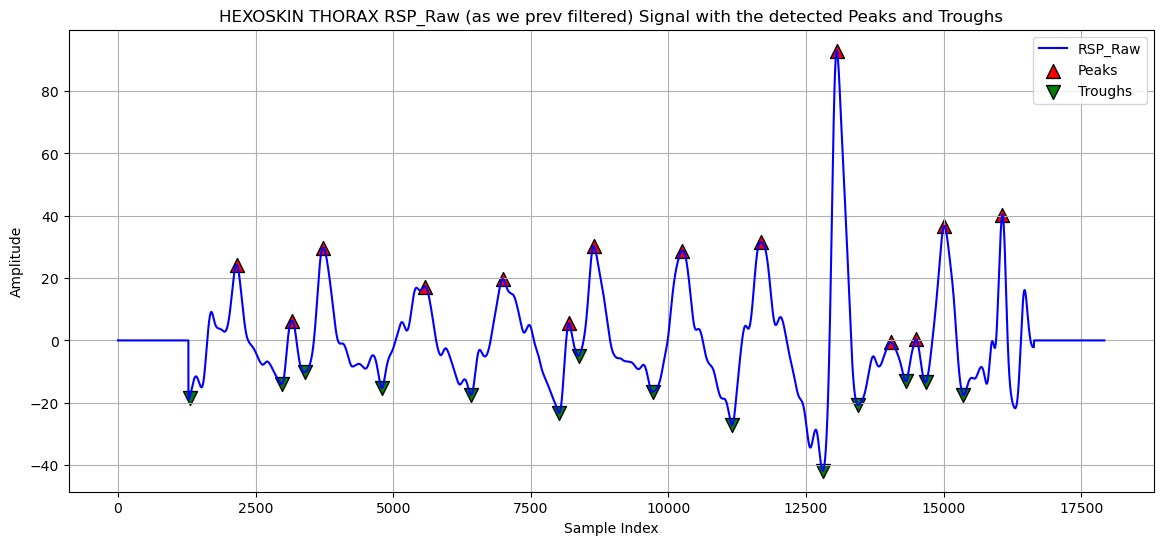

In [160]:
#import the library we will use to plot
import matplotlib.pyplot as plt
plt.figure(figsize=(14, 6))

# plot the "raw" (we already previously filtered) hexoskin signal from the signals dataframe
plt.plot(signals_hexoskin_thorax_10['RSP_Raw'], label="RSP_Raw", color='blue')

# plot a red triangle for when there are detected peaks
if signals_hexoskin_thorax_10['RSP_Peaks'].sum() > 0:  #if at least one peak exists, proceed with plotting
    peak_indices = signals_hexoskin_thorax_10.index[signals_hexoskin_thorax_10['RSP_Peaks'] == 1] #makes an array for the index of each peak
    print(peak_indices)
    plt.scatter(peak_indices, signals_hexoskin_thorax_10.loc[peak_indices, 'RSP_Raw'], color='red', label='Peaks', marker='^', s=100, edgecolor='black') #X is peak indices
                                                                                                                 #Y is the signals value at the index

# plot a green triangle for when there are detected troughs
if signals_hexoskin_thorax_10['RSP_Troughs'].sum() > 0:  #if at least one trough exists, proceed with plotting
    trough_indices = signals_hexoskin_thorax_10.index[signals_hexoskin_thorax_10['RSP_Troughs'] == 1] #makes an array for the index of each trough
    print(trough_indices)
    plt.scatter(trough_indices, signals_hexoskin_thorax_10.loc[trough_indices, 'RSP_Raw'], color='green', label='Troughs', marker='v', s=100, edgecolor='black')

plt.title('HEXOSKIN THORAX RSP_Raw (as we prev filtered) Signal with the detected Peaks and Troughs')
plt.xlabel('Sample Index')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True)
plt.show()

In [161]:
# define a list to store the tidal volume values for each peak
hexoskin_thorax_depths_sitting = []

for peak_idx in signals_hexoskin_thorax_10.index[signals_hexoskin_thorax_10['RSP_Peaks'] == 1]: #identify where there are peaks
    # find the preceding trough
    preceding_troughs = signals_hexoskin_thorax_10.index[(signals_hexoskin_thorax_10['RSP_Troughs'] == 1) & (signals_hexoskin_thorax_10.index < peak_idx)] #gives list of all preceding troughs for a given peak
    
    if not preceding_troughs.empty:
        trough_idx = preceding_troughs[-1]  # select the last trough in the list (to get the most recent trough)
        tidal_volume = signals_hexoskin_thorax_10.loc[peak_idx, 'RSP_Raw'] - signals_hexoskin_thorax_10.loc[trough_idx, 'RSP_Raw']  #subtract the value of the give peak from that of the
                                                                                                #preceding trough
        hexoskin_thorax_depths_sitting.append(tidal_volume) #the calculated respiratory depths gets appended to the previously created list

# make the tidal volume list a numpy array
hexoskin_thorax_depths_sitting = np.array(hexoskin_thorax_depths_sitting)
print(hexoskin_thorax_depths_sitting)
print(len(hexoskin_thorax_depths_sitting))

[ 42.59074773  20.33337716  39.89883112  32.54459155  37.13194091
  28.72803241  35.15060725  45.34834473  58.63955329 134.73815801
  19.96445232  13.43373363  50.14442506  57.80314802]
14


Index([4017, 6335, 8741, 11654, 14185, 16583, 19051, 21144, 23333], dtype='int64')
Index([2712, 4952, 7648, 9953, 12667, 15264, 17626, 20382, 22605], dtype='int64')


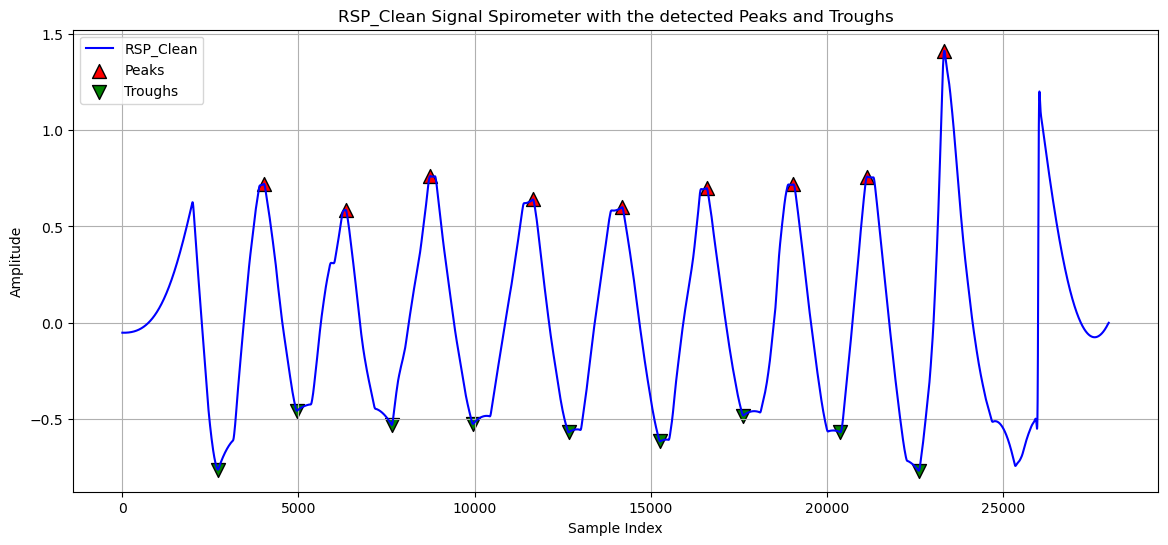

9
Index([ 2154,  3157,  3727,  5579,  6988,  8192,  8642, 10255, 11677, 13057,
       14039, 14499, 15012, 16068],
      dtype='int64')
Index([ 1300,  2974,  3396,  4796,  6415,  8014,  8370,  9719, 11158, 12808,
       13440, 14313, 14672, 15359],
      dtype='int64')


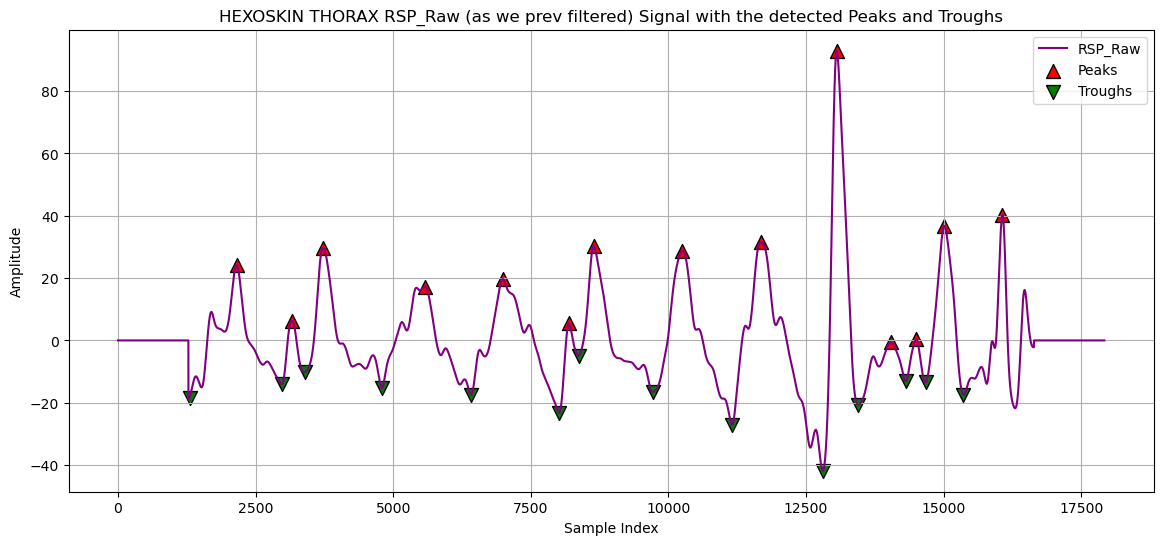

14


In [162]:
#PLOT THE SPIROMETER AGAINST THE HEXOSKIN THORAX - SITTING
import matplotlib.pyplot as plt
plt.figure(figsize=(14, 6))

# plot the spirometer signal from the signals dataframe
plt.plot(signals['RSP_Clean'], label="RSP_Clean", color='blue')

# plot a red triangle for when there are detected peaks
if signals['RSP_Peaks'].sum() > 0:  #if at least one peak exists, proceed with plotting
    peak_indices = signals.index[signals['RSP_Peaks'] == 1] #makes an array for the index of each peak
    print(peak_indices)
    plt.scatter(peak_indices, signals.loc[peak_indices, 'RSP_Clean'], color='red', label='Peaks', marker='^', s=100, edgecolor='black') #X is peak indices
                                                                                                                 #Y is the signals value at the index

# plot a green triangle for when there are detected troughs
if signals['RSP_Troughs'].sum() > 0:  #if at least one trough exists, proceed with plotting
    trough_indices = signals.index[signals['RSP_Troughs'] == 1] #makes an array for the index of each trough
    print(trough_indices)
    plt.scatter(trough_indices, signals.loc[trough_indices, 'RSP_Clean'], color='green', label='Troughs', marker='v', s=100, edgecolor='black')

plt.title('RSP_Clean Signal Spirometer with the detected Peaks and Troughs')
plt.xlabel('Sample Index')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True)
plt.show()

print(len(tv_sitting_spiro))

import matplotlib.pyplot as plt
plt.figure(figsize=(14, 6))

# plot the "raw" hexoskin thorax
plt.plot(signals_hexoskin_thorax_10['RSP_Raw'], label="RSP_Raw", color='purple')

# plot a red triangle for when there are detected peaks
if signals_hexoskin_thorax_10['RSP_Peaks'].sum() > 0:  #if at least one peak exists, proceed with plotting
    peak_indices = signals_hexoskin_thorax_10.index[signals_hexoskin_thorax_10['RSP_Peaks'] == 1] #makes an array for the index of each peak
    print(peak_indices)
    plt.scatter(peak_indices, signals_hexoskin_thorax_10.loc[peak_indices, 'RSP_Raw'], color='red', label='Peaks', marker='^', s=100, edgecolor='black') #X is peak indices
                                                                                                                 #Y is the signals value at the index
# plot a green triangle for when there are detected troughs
if signals_hexoskin_thorax_10['RSP_Troughs'].sum() > 0:  #if at least one trough exists, proceed with plotting
    trough_indices = signals_hexoskin_thorax_10.index[signals_hexoskin_thorax_10['RSP_Troughs'] == 1] #makes an array for the index of each trough
    print(trough_indices)
    plt.scatter(trough_indices, signals_hexoskin_thorax_10.loc[trough_indices, 'RSP_Raw'], color='green', label='Troughs', marker='v', s=100, edgecolor='black')

plt.title('HEXOSKIN THORAX RSP_Raw (as we prev filtered) Signal with the detected Peaks and Troughs')
plt.xlabel('Sample Index')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True)
plt.show()

print(len(hexoskin_thorax_depths_sitting))

In [ ]:
#drop the last 4 cycles from hexoskin thorax
#hexoskin_thorax_depths_sitting = hexoskin_thorax_depths_sitting[:-4]
#drop the first 6 cycles from the spirometer
#tv_sitting_spiro = tv_sitting_spiro[6:]

In [ ]:
#drop the last cycle in the spirometer
#tv_sitting_spiro = tv_sitting_spiro[:-1]

In [163]:
import numpy as np

hexoskin_thorax_depths_sitting = np.delete(hexoskin_thorax_depths_sitting, [1, 5]) #removing the second and 6th cycles from hexoskin
#drop the last 4 cycles in thorax
hexoskin_thorax_depths_sitting = hexoskin_thorax_depths_sitting[:-4]
#drop the first cycle in spirometer
tv_sitting_spiro = tv_sitting_spiro[1:]

In [164]:
print(len(hexoskin_thorax_depths_sitting))
print(len(tv_sitting_spiro))

8
8


In [165]:
#THIS IS FOR RIP - THORAX ONLY CALIBRATION, NOT THE THORACOABDOMINAL CALIBRATION!!
#here we solve for beta (slope and intercept) such that we create a least squares regression of spirometer volume being predicted by
#impedance value times some slope plus an intercept
#specifically, we use the Moore-Penrose pseudoinverse way of solving for the regression coefficients - using the ordinary least squares formula
#under statsmodels give the same answers
import numpy as np
assert len(hexoskin_thorax_depths_sitting) == len(tv_sitting_spiro)
print(hexoskin_thorax_depths_sitting)
X = hexoskin_thorax_depths_sitting[:, np.newaxis]  # convert impedance to a 2D array, necessary for linear regression in matrix format
print(X)
y = tv_sitting_spiro  # spirometer volumes
print(y)

# add a columns of ones to include an intercept in the regression
X = np.column_stack((np.ones(len(hexoskin_thorax_depths_sitting)), X))  # Augment X with a column of ones
print(X)

# calculate the pseudoinverse of the matrix X
X_pinv = np.linalg.pinv(X)

# multiply the pseudoinverse of X with the outcome variable y to calculate the slope and intercept
conversion_coefficients_sitting = np.dot(X_pinv, y) #dot product function for matrix multiplication
print(conversion_coefficients_sitting)

# print the conversion coefficients
hexoskin_thorax_intercept_sitting, hexoskin_thorax_slope_sitting = conversion_coefficients_sitting  #to be saved at the end  of the document
print(f"Conversion coefficients: Intercept = {hexoskin_thorax_intercept_sitting}, Slope = {hexoskin_thorax_slope_sitting}")


[ 42.59074773  39.89883112  32.54459155  37.13194091  35.15060725
  45.34834473  58.63955329 134.73815801]
[[ 42.59074773]
 [ 39.89883112]
 [ 32.54459155]
 [ 37.13194091]
 [ 35.15060725]
 [ 45.34834473]
 [ 58.63955329]
 [134.73815801]]
[1.0093745  1.62991658 1.21372396 1.23830032 1.39481544 1.27578878
 1.42059994 2.34556323]
[[  1.          42.59074773]
 [  1.          39.89883112]
 [  1.          32.54459155]
 [  1.          37.13194091]
 [  1.          35.15060725]
 [  1.          45.34834473]
 [  1.          58.63955329]
 [  1.         134.73815801]]
[0.8727111  0.01067121]
Conversion coefficients: Intercept = 0.8727111018987801, Slope = 0.010671214756224272


In [166]:
import statsmodels.api as sm 
import pandas as pd          
import matplotlib.pyplot as plt 
import numpy as np
# cross-checking to see if we get the same parameters with the ordinary least squares function
x = hexoskin_thorax_depths_sitting
y = tv_sitting_spiro
x = sm.add_constant(x)
result = sm.OLS(y, x).fit()
print(result.summary()) #we do get the same findings

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.787
Model:                            OLS   Adj. R-squared:                  0.752
Method:                 Least Squares   F-statistic:                     22.21
Date:                Thu, 16 Apr 2026   Prob (F-statistic):            0.00328
Time:                        11:48:37   Log-Likelihood:                 2.5551
No. Observations:                   8   AIC:                            -1.110
Df Residuals:                       6   BIC:                           -0.9514
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.8727      0.140      6.219      0.0

C:\Users\msa583\AppData\Local\anaconda3\Lib\site-packages\scipy\stats\_axis_nan_policy.py:531: UserWarning: kurtosistest only valid for n>=20 ... continuing anyway, n=8
  res = hypotest_fun_out(*samples, **kwds)


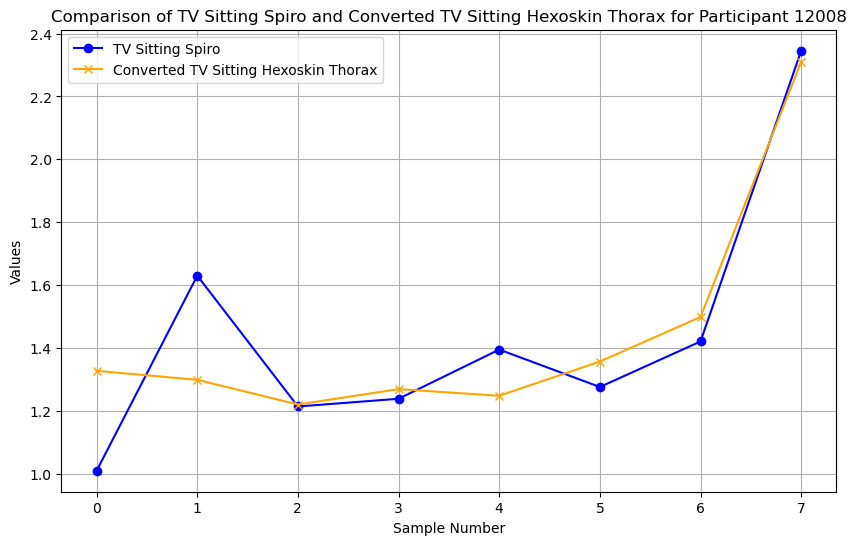

In [167]:
# applying the calculated conversion slope and intercept to the impedance amplitude values
tv_sitting_hexoskin_thorax_converted = (hexoskin_thorax_depths_sitting * hexoskin_thorax_slope_sitting) + hexoskin_thorax_intercept_sitting

plt.figure(figsize=(10, 6))

# plot the actual tidal volumes obtained via spirometer
plt.plot(tv_sitting_spiro, label='TV Sitting Spiro', color='blue', marker='o')

# plot the calibrated impedance volumes
plt.plot(tv_sitting_hexoskin_thorax_converted, label='Converted TV Sitting Hexoskin Thorax', color='orange', marker='x')

plt.title(f'Comparison of TV Sitting Spiro and Converted TV Sitting Hexoskin Thorax for Participant {ppid}')
plt.xlabel('Sample Number')
plt.ylabel('Values')
plt.legend() 
plt.grid()   
plt.show()

In [168]:
y = tv_sitting_spiro  # spirometer volumes

# calculate mean absolute percentage error (MAPE) for the supine spirometer calibration
hexoskin_thorax_mape_sitting = np.mean(np.abs((y - tv_sitting_hexoskin_thorax_converted) / (y))) * 100
print(f"mean absolute percentage error (MAPE): {hexoskin_thorax_mape_sitting:.4f}%") #to be saved at the end of the script

mean absolute percentage error (MAPE): 9.8333%


In [169]:
#calculate the root mean squared errors (RMSE) for the impedance supine calibration
# calculate squared errors
actual = tv_sitting_spiro
predicted = tv_sitting_hexoskin_thorax_converted

squared_errors = (actual - predicted) ** 2

# find the mean of squared errors
mse = np.mean(squared_errors)

# take the square root to get RMSE
rmse = np.sqrt(mse)

hexoskin_thorax_rmse_sitting = rmse
print("Root Mean Squared Error:", hexoskin_thorax_rmse_sitting)

Root Mean Squared Error: 0.1758133744757363


In [170]:
# applying the resp process function on the hexoskin abdomen function and visualizing
import neurokit2 as nk
#implementing the respiratory processing function from neurokit2 to automatically detect the peaks and troughs
signals_hexoskin_abdomen_10, info = nk.rsp_process(hexoskin_abdomen_10, sampling_rate=128)
signals_hexoskin_abdomen_10       #the first output (signals) generates a  dataframe that includes the raw signal values and RSP_Peaks and RSP_Troughs
              #info stores a dictionary with the arrays for the RSP_Peaks, RSP_Troughs, sampling rate

,RSP_Raw,RSP_Clean,RSP_Amplitude,RSP_Rate,RSP_RVT,RSP_Phase,RSP_Phase_Completion,RSP_Symmetry_PeakTrough,RSP_Symmetry_RiseDecay,RSP_Peaks,RSP_Troughs
0,0.0,0.099255,38.811428,6.762853,0.033559,NaN,0.0,0.696464,0.410453,0,0
1,0.0,0.100124,38.811428,6.762853,0.033680,NaN,0.0,0.696464,0.410453,0,0
2,0.0,0.100995,38.811428,6.762853,0.033802,NaN,0.0,0.696464,0.410453,0,0
3,0.0,0.101869,38.811428,6.762853,0.033924,NaN,0.0,0.696464,0.410453,0,0
4,0.0,0.102745,38.811428,6.762853,0.034045,NaN,0.0,0.696464,0.410453,0,0
...,...,...,...,...,...,...,...,...,...,...,...
17915,0.0,0.000617,7.910401,7.741935,0.031254,NaN,0.0,0.765370,0.569556,0,0
17916,0.0,0.000556,7.910401,7.741935,0.031311,NaN,0.0,0.765370,0.569556,0,0
17917,0.0,0.000496,7.910401,7.741935,0.031365,NaN,0.0,0.765370,0.569556,0,0
17918,0.0,0.000438,7.910401,7.741935,0.031418,NaN,0.0,0.765370,0.569556,0,0


Index([ 2163,  3708,  4196,  4645,  5403,  6968,  8614, 10237, 11663, 13021,
       13890, 14994, 15910, 16468],
      dtype='int64')
Index([ 1574,  3009,  4022,  4449,  5123,  6459,  8069,  9847, 11173, 12596,
       13460, 14371, 15345, 16337],
      dtype='int64')


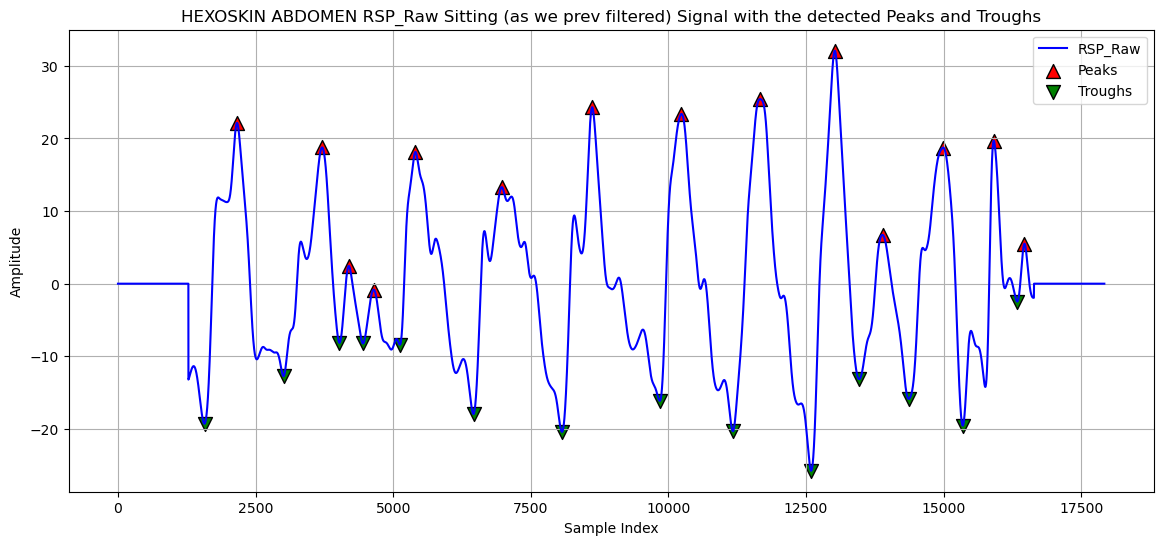

In [171]:
#import the library we will use to plot
import matplotlib.pyplot as plt
plt.figure(figsize=(14, 6))

# plot the hexoskin abdomen signal
plt.plot(signals_hexoskin_abdomen_10['RSP_Raw'], label="RSP_Raw", color='blue')

# plot a red triangle for when there are detected peaks
if signals_hexoskin_abdomen_10['RSP_Peaks'].sum() > 0:  #if at least one peak exists, proceed with plotting
    peak_indices = signals_hexoskin_abdomen_10.index[signals_hexoskin_abdomen_10['RSP_Peaks'] == 1] #makes an array for the index of each peak
    print(peak_indices)
    plt.scatter(peak_indices, signals_hexoskin_abdomen_10.loc[peak_indices, 'RSP_Raw'], color='red', label='Peaks', marker='^', s=100, edgecolor='black') #X is peak indices
                                                                                                                 #Y is the signals value at the index

# plot a green triangle for when there are detected troughs
if signals_hexoskin_abdomen_10['RSP_Troughs'].sum() > 0:  #if at least one trough exists, proceed with plotting
    trough_indices = signals_hexoskin_abdomen_10.index[signals_hexoskin_abdomen_10['RSP_Troughs'] == 1] #makes an array for the index of each trough
    print(trough_indices)
    plt.scatter(trough_indices, signals_hexoskin_abdomen_10.loc[trough_indices, 'RSP_Raw'], color='green', label='Troughs', marker='v', s=100, edgecolor='black')

plt.title('HEXOSKIN ABDOMEN RSP_Raw Sitting (as we prev filtered) Signal with the detected Peaks and Troughs')
plt.xlabel('Sample Index')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True)
plt.show()


In [172]:
# define a list to store the tidal volume values for each peak
hexoskin_abdomen_depths_sitting = []

for peak_idx in signals_hexoskin_abdomen_10.index[signals_hexoskin_abdomen_10['RSP_Peaks'] == 1]: #identify where there are peaks
    # find the preceding trough
    preceding_troughs = signals_hexoskin_abdomen_10.index[(signals_hexoskin_abdomen_10['RSP_Troughs'] == 1) & (signals_hexoskin_abdomen_10.index < peak_idx)] #gives list of all preceding troughs for a given peak
    
    if not preceding_troughs.empty:
        trough_idx = preceding_troughs[-1]  # select the last trough in the list (to get the most recent trough)
        tidal_volume = signals_hexoskin_abdomen_10.loc[peak_idx, 'RSP_Raw'] - signals_hexoskin_abdomen_10.loc[trough_idx, 'RSP_Raw']  #subtract the value of the give peak from that of the
                                                                                                #preceding trough
        hexoskin_abdomen_depths_sitting.append(tidal_volume) #the calculated respiratory depths gets appended to the previously created list

# make the tidal volume list a mumpy array
hexoskin_abdomen_depths_sitting = np.array(hexoskin_abdomen_depths_sitting)
print(hexoskin_abdomen_depths_sitting)
print(len(hexoskin_abdomen_depths_sitting))

[41.40153357 31.47982378 10.56768843  7.39888824 26.53048319 31.22466849
 44.68479493 39.49203913 45.71356924 57.81523101 19.85205446 34.5859242
 39.23535736  7.96463821]
14


In [173]:
import numpy as np

hexoskin_abdomen_depths_sitting = np.delete(
    hexoskin_abdomen_depths_sitting, [2, 3]   #deleting the 3rd and 4th cycles of hexoskin abdomen
)
#delete the last 4 cycles of hexoskin abdomen
hexoskin_abdomen_depths_sitting = hexoskin_abdomen_depths_sitting[:-4]

In [174]:
#delete the first two beginning cycles and the last cycle from the abdomen signal 
#hexoskin_abdomen_depths_sitting = hexoskin_abdomen_depths_sitting[2:]

In [175]:
print(tv_sitting_spiro)
print(hexoskin_thorax_depths_sitting)
print(hexoskin_abdomen_depths_sitting)

print(len(tv_sitting_spiro))
print(len(hexoskin_thorax_depths_sitting))
print(len(hexoskin_abdomen_depths_sitting))

[1.0093745  1.62991658 1.21372396 1.23830032 1.39481544 1.27578878
 1.42059994 2.34556323]
[ 42.59074773  39.89883112  32.54459155  37.13194091  35.15060725
  45.34834473  58.63955329 134.73815801]
[41.40153357 31.47982378 26.53048319 31.22466849 44.68479493 39.49203913
 45.71356924 57.81523101]
8
8
8


In [176]:
import numpy as np
assert len(tv_sitting_spiro) == len(hexoskin_thorax_depths_sitting) == len(hexoskin_abdomen_depths_sitting)

print("TV array (y):")
print(tv_sitting_spiro)
print("Thorax array:")
print(hexoskin_thorax_depths_sitting)
print("Abdomen array:")
print(hexoskin_abdomen_depths_sitting)

# turn predictors into a 2D array
X = np.column_stack((
    hexoskin_thorax_depths_sitting,
    hexoskin_abdomen_depths_sitting
))
print("\nStep 1: X (thorax and abdomen only)")
print(X)
print("Shape:", X.shape)

# add column of ones for intercept
X = np.column_stack((
    np.ones(len(tv_sitting_spiro)),  # intercept
    X
))
print("\nStep 2: X after adding intercept column")
print(X)
print("Shape:", X.shape)

# calculate pseudoinverse
X_pinv = np.linalg.pinv(X)
print("\nStep 3: Pseudoinverse of X")
print(X_pinv)
print("Shape:", X_pinv.shape)

# multiplying the pseudoinverse with y, and calculating the regression parameters
conversion_coefficients_sitting = np.dot(X_pinv, tv_sitting_spiro)
twodegrees_intercept_sitting, twodegrees_slope_thorax_sitting, twodegrees_slope_abdomen_sitting = conversion_coefficients_sitting

print("\nStep 4: Conversion coefficients")
print(f"Intercept: {twodegrees_intercept_sitting}")
print(f"Slope Thorax: {twodegrees_slope_thorax_sitting}")
print(f"Slope Abdomen: {twodegrees_slope_abdomen_sitting}")

TV array (y):
[1.0093745  1.62991658 1.21372396 1.23830032 1.39481544 1.27578878
 1.42059994 2.34556323]
Thorax array:
[ 42.59074773  39.89883112  32.54459155  37.13194091  35.15060725
  45.34834473  58.63955329 134.73815801]
Abdomen array:
[41.40153357 31.47982378 26.53048319 31.22466849 44.68479493 39.49203913
 45.71356924 57.81523101]

Step 1: X (thorax and abdomen only)
[[ 42.59074773  41.40153357]
 [ 39.89883112  31.47982378]
 [ 32.54459155  26.53048319]
 [ 37.13194091  31.22466849]
 [ 35.15060725  44.68479493]
 [ 45.34834473  39.49203913]
 [ 58.63955329  45.71356924]
 [134.73815801  57.81523101]]
Shape: (8, 2)

Step 2: X after adding intercept column
[[  1.          42.59074773  41.40153357]
 [  1.          39.89883112  31.47982378]
 [  1.          32.54459155  26.53048319]
 [  1.          37.13194091  31.22466849]
 [  1.          35.15060725  44.68479493]
 [  1.          45.34834473  39.49203913]
 [  1.          58.63955329  45.71356924]
 [  1.         134.73815801  57.81523101]

In [177]:
#add the OLS cross-check here
import statsmodels.api as sm
#cross-checking with a package to see whether the results are the same
X_sm = sm.add_constant(np.column_stack((
    hexoskin_thorax_depths_sitting,
    hexoskin_abdomen_depths_sitting
)))
model = sm.OLS(tv_sitting_spiro, X_sm).fit()
print(model.summary()) #regression parameters are the same

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.801
Model:                            OLS   Adj. R-squared:                  0.722
Method:                 Least Squares   F-statistic:                     10.09
Date:                Thu, 16 Apr 2026   Prob (F-statistic):             0.0176
Time:                        11:51:17   Log-Likelihood:                 2.8292
No. Observations:                   8   AIC:                            0.3415
Df Residuals:                       5   BIC:                            0.5799
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.0936      0.400      2.737      0.0

C:\Users\msa583\AppData\Local\anaconda3\Lib\site-packages\scipy\stats\_axis_nan_policy.py:531: UserWarning: kurtosistest only valid for n>=20 ... continuing anyway, n=8
  res = hypotest_fun_out(*samples, **kwds)


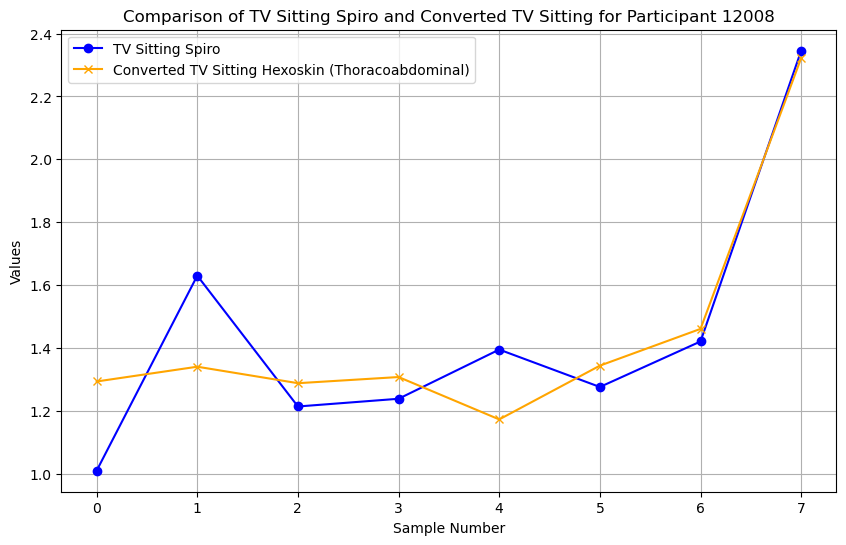

In [178]:
# applying the calculated conversion slope and intercept to the impedance amplitude values
tv_sitting_hexoskin_converted = (hexoskin_thorax_depths_sitting * twodegrees_slope_thorax_sitting) + (hexoskin_abdomen_depths_sitting * twodegrees_slope_abdomen_sitting) + twodegrees_intercept_sitting 

plt.figure(figsize=(10, 6))

# plot the actual tidal volumes obtained via spirometer
plt.plot(tv_sitting_spiro, label='TV Sitting Spiro', color='blue', marker='o')

# plot the calibrated impedance volumes
plt.plot(tv_sitting_hexoskin_converted, label='Converted TV Sitting Hexoskin (Thoracoabdominal)', color='orange', marker='x')

plt.title(f'Comparison of TV Sitting Spiro and Converted TV Sitting for Participant {ppid}')
plt.xlabel('Sample Number')
plt.ylabel('Values')
plt.legend() 
plt.grid()   
plt.show()

In [179]:
y = tv_sitting_spiro  # spirometer volumes

# calculate mean absolute percentage error (MAPE) for the supine spirometer calibration
twodegrees_mape_sitting = np.mean(np.abs((y - tv_sitting_hexoskin_converted) / (y))) * 100
print(f"mean absolute percentage error (MAPE): {twodegrees_mape_sitting:.4f}%") #to be saved at the end of the script

mean absolute percentage error (MAPE): 10.3313%


In [180]:
#add rmse calculation here
#calculate the root mean squared errors (RMSE) for the impedance supine calibration
# calculate squared errors
actual = tv_sitting_spiro
predicted = tv_sitting_hexoskin_converted

squared_errors = (actual - predicted) ** 2

# find the mean of squared errors
mse = np.mean(squared_errors)

# take the square root to get RMSE
rmse = np.sqrt(mse)

twodegrees_rmse_sitting = rmse
print("Root Mean Squared Error:", twodegrees_rmse_sitting)

Root Mean Squared Error: 0.16989209351887222


In [181]:
#Also calculating a regression for calibrating the Hexoskin abdomen only to spirometer (won't be used in the main analysis but good to have)

#THIS IS FOR RIP - ABDOMEN ONLY CALIBRATION, NOT THE THORACOABDOMINAL CALIBRATION!!
#specifically, we use the Moore-Penrose pseudoinverse way of solving for the regression coefficients - using the ordinary least squares formula
#under statsmodels give the same answers
import numpy as np

# ensure that the data sets have the same length
assert len(hexoskin_abdomen_depths_sitting) == len(tv_sitting_spiro)
print(hexoskin_abdomen_depths_sitting)
X = hexoskin_abdomen_depths_sitting[:, np.newaxis]  # convert impedance to a 2D array, necessary for linear regression in matrix format
print(X)
y = tv_sitting_spiro  # spirometer volumes
print(y)

# add a columns of ones to include an intercept in the regression
X = np.column_stack((np.ones(len(hexoskin_abdomen_depths_sitting)), X))  # Augment X with a column of ones
print(X)

# calculate the pseudoinverse of the matrix X
X_pinv = np.linalg.pinv(X)

# multiply the pseudoinverse of X with the outcome variable y to calculate the slope and intercept
conversion_coefficients_sitting = np.dot(X_pinv, y) #dot product function for matrix multiplication
print(conversion_coefficients_sitting)

# print the conversion coefficients
hexoskin_abdomen_intercept_sitting, hexoskin_abdomen_slope_sitting = conversion_coefficients_sitting  #to be saved at the end  of the document
print(f"Conversion coefficients: Intercept = {hexoskin_abdomen_intercept_sitting}, Slope = {hexoskin_abdomen_slope_sitting}")


[41.40153357 31.47982378 26.53048319 31.22466849 44.68479493 39.49203913
 45.71356924 57.81523101]
[[41.40153357]
 [31.47982378]
 [26.53048319]
 [31.22466849]
 [44.68479493]
 [39.49203913]
 [45.71356924]
 [57.81523101]]
[1.0093745  1.62991658 1.21372396 1.23830032 1.39481544 1.27578878
 1.42059994 2.34556323]
[[ 1.         41.40153357]
 [ 1.         31.47982378]
 [ 1.         26.53048319]
 [ 1.         31.22466849]
 [ 1.         44.68479493]
 [ 1.         39.49203913]
 [ 1.         45.71356924]
 [ 1.         57.81523101]]
[0.3971048  0.02623355]
Conversion coefficients: Intercept = 0.39710479941576715, Slope = 0.026233549460375878


In [182]:
import statsmodels.api as sm 
import pandas as pd          
import matplotlib.pyplot as plt 
import numpy as np
# cross-checking to see if we get the same parameters with the ordinary least squares function
x = hexoskin_abdomen_depths_sitting
y = tv_sitting_spiro
x = sm.add_constant(x)
result = sm.OLS(y, x).fit()
print(result.summary()) #we do get the same findings

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.417
Model:                            OLS   Adj. R-squared:                  0.320
Method:                 Least Squares   F-statistic:                     4.295
Date:                Thu, 16 Apr 2026   Prob (F-statistic):             0.0836
Time:                        11:51:34   Log-Likelihood:                -1.4776
No. Observations:                   8   AIC:                             6.955
Df Residuals:                       6   BIC:                             7.114
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.3971      0.518      0.767      0.4

C:\Users\msa583\AppData\Local\anaconda3\Lib\site-packages\scipy\stats\_axis_nan_policy.py:531: UserWarning: kurtosistest only valid for n>=20 ... continuing anyway, n=8
  res = hypotest_fun_out(*samples, **kwds)


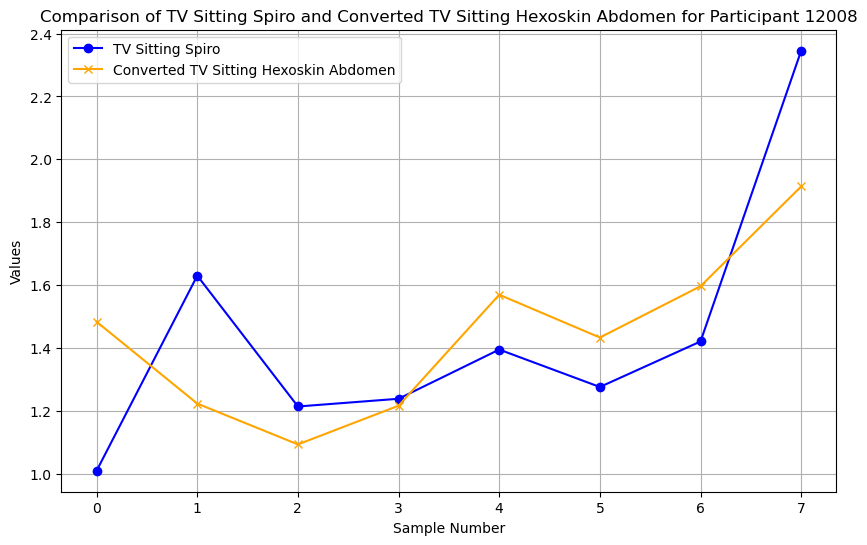

In [183]:
# applying the calculated conversion slope and intercept to the hexoskin abdomen amplitude values
tv_sitting_hexoskin_abdomen_converted = (hexoskin_abdomen_depths_sitting * hexoskin_abdomen_slope_sitting) + hexoskin_abdomen_intercept_sitting

plt.figure(figsize=(10, 6))

# plot the actual tidal volumes obtained via spirometer
plt.plot(tv_sitting_spiro, label='TV Sitting Spiro', color='blue', marker='o')

# plot the calibrated impedance volumes
plt.plot(tv_sitting_hexoskin_abdomen_converted, label='Converted TV Sitting Hexoskin Abdomen', color='orange', marker='x')

plt.title(f'Comparison of TV Sitting Spiro and Converted TV Sitting Hexoskin Abdomen for Participant {ppid}')
plt.xlabel('Sample Number')
plt.ylabel('Values')
plt.legend() 
plt.grid()   
plt.show()

In [184]:
y = tv_sitting_spiro  # spirometer volumes

# calculate mean absolute percentage error (MAPE) for the supine spirometer calibration
hexoskin_abdomen_mape_sitting = np.mean(np.abs((y - tv_sitting_hexoskin_abdomen_converted) / (y))) * 100
print(f"mean absolute percentage error (MAPE): {hexoskin_abdomen_mape_sitting:.4f}%") #to be saved at the end of the script

mean absolute percentage error (MAPE): 17.4071%


In [185]:
#calculate the root mean squared errors (RMSE) for the hexoskin abdomen sitting calibration
# calculate squared errors
actual = tv_sitting_spiro
predicted = tv_sitting_hexoskin_abdomen_converted

squared_errors = (actual - predicted) ** 2

# find the mean of squared errors
mse = np.mean(squared_errors)

# take the square root to get RMSE
rmse = np.sqrt(mse)

hexoskin_abdomen_rmse_sitting = rmse
print("Root Mean Squared Error:", hexoskin_abdomen_rmse_sitting)

Root Mean Squared Error: 0.2910566101130025


## STANDING

### READING IN SPIROMETER

In [216]:
import pandas as pd  #put the package imports also in the standing section as some participants started with the standing position and the calibration
                     # order in this script would also start from here the standing posture section
#reading the supine csv recording from the spirometer
volume_standing = pd.read_csv(f'standing_{ppid}.csv')
#viewing the dataframe
volume_standing.head()

,Data Set 1:Time(s),Data Set 1:Flow Rate(L/s),Data Set 1:Volume(L),Data Set 2:Time(s),Data Set 2:Flow Rate(L/s),Data Set 2:Volume(L),Data Set 3:Time(s),Data Set 3:Flow Rate(L/s),Data Set 3:Volume(L),Data Set 4:Time(s),Data Set 4:Flow Rate(L/s),Data Set 4:Volume(L)
0,0.000,0.0,0.0,0.000,-0.331608,0.0,0.000,0.585815,0.000000,0.000,0.719374,0.000000
1,0.005,0.0,0.0,0.005,-0.331608,0.0,0.005,0.588038,-0.003090,0.005,0.721282,-0.003790
2,0.010,0.0,0.0,0.010,-0.331608,0.0,0.010,0.588038,-0.006180,0.010,0.721282,-0.007581
3,0.015,0.0,0.0,0.015,-0.328198,0.0,0.015,0.588038,-0.009270,0.015,0.723187,-0.011381
4,0.020,0.0,0.0,0.020,-0.324762,0.0,0.020,0.588038,-0.012361,0.020,0.723187,-0.015181


In [217]:
import numpy as np
#the dataframe also has the flow rate and time but we are not interested in those, so selecting the tidal volume column
spirometer_standing = volume_standing['Data Set 4:Volume(L)'] #here, you might need to change the number of the data set

#converting the data format from float64 to numpy array format for later peak valley detection using neurokit2
spirometer_standing = np.array(spirometer_standing)

# only select the first 120 seconds of the signal (the first 2400 rows due to the sampling rate being 200)
spirometer_standing = spirometer_standing[:24000]

#doing zero padding of 10 seconds (signal sampling rate was 200 Hz) to the beginning and ending of the signal
spirometer_standing = np.concatenate([np.zeros(2000), spirometer_standing, np.zeros(2000)])
print(spirometer_standing)

[0. 0. 0. ... 0. 0. 0.]


In [218]:
import neurokit2 as nk
#implementing the respiratory processing function from neurokit2 to automatically detect the peaks and troughs
signals, info = nk.rsp_process(spirometer_standing, sampling_rate=200)
signals       #the first output (signals) generates a  dataframe that includes the raw signal values and RSP_Peaks and RSP_Troughs
              #info stores a dictionary with the arrays for the RSP_Peaks, RSP_Troughs, sampling rate

,RSP_Raw,RSP_Clean,RSP_Amplitude,RSP_Rate,RSP_RVT,RSP_Phase,RSP_Phase_Completion,RSP_Symmetry_PeakTrough,RSP_Symmetry_RiseDecay,RSP_Peaks,RSP_Troughs
0,0.0,-0.031230,2.111848,5.926511,0.004931,NaN,0.0,0.601137,0.486188,0,0
1,0.0,-0.031212,2.111848,5.926511,0.004931,NaN,0.0,0.601137,0.486188,0,0
2,0.0,-0.031195,2.111848,5.926511,0.004931,NaN,0.0,0.601137,0.486188,0,0
3,0.0,-0.031177,2.111848,5.926511,0.004931,NaN,0.0,0.601137,0.486188,0,0
4,0.0,-0.031159,2.111848,5.926511,0.004931,NaN,0.0,0.601137,0.486188,0,0
...,...,...,...,...,...,...,...,...,...,...,...
27995,0.0,-0.001537,1.882456,5.914243,0.004318,NaN,0.0,0.527834,0.561853,0,0
27996,0.0,-0.001354,1.882456,5.914243,0.004319,NaN,0.0,0.527834,0.561853,0,0
27997,0.0,-0.001181,1.882456,5.914243,0.004319,NaN,0.0,0.527834,0.561853,0,0
27998,0.0,-0.001020,1.882456,5.914243,0.004320,NaN,0.0,0.527834,0.561853,0,0


Index([3747, 5850, 8078, 10197, 12272, 14105, 16208, 18119, 20079, 21962,
       24172],
      dtype='int64')
Index([2603, 4956, 6736, 9175, 11020, 13028, 14882, 16968, 18899, 20822,
       22851],
      dtype='int64')


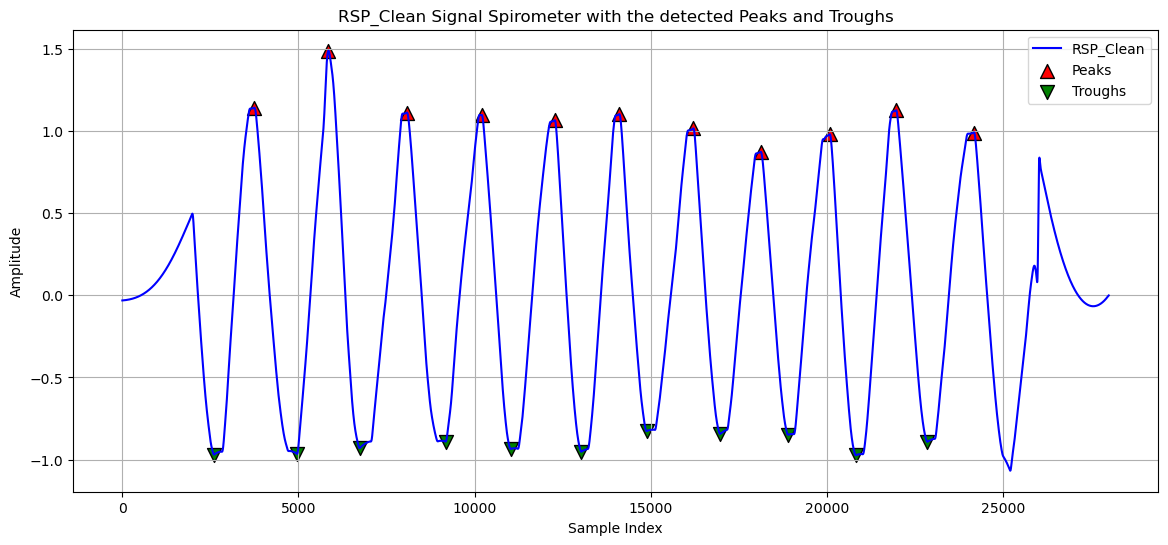

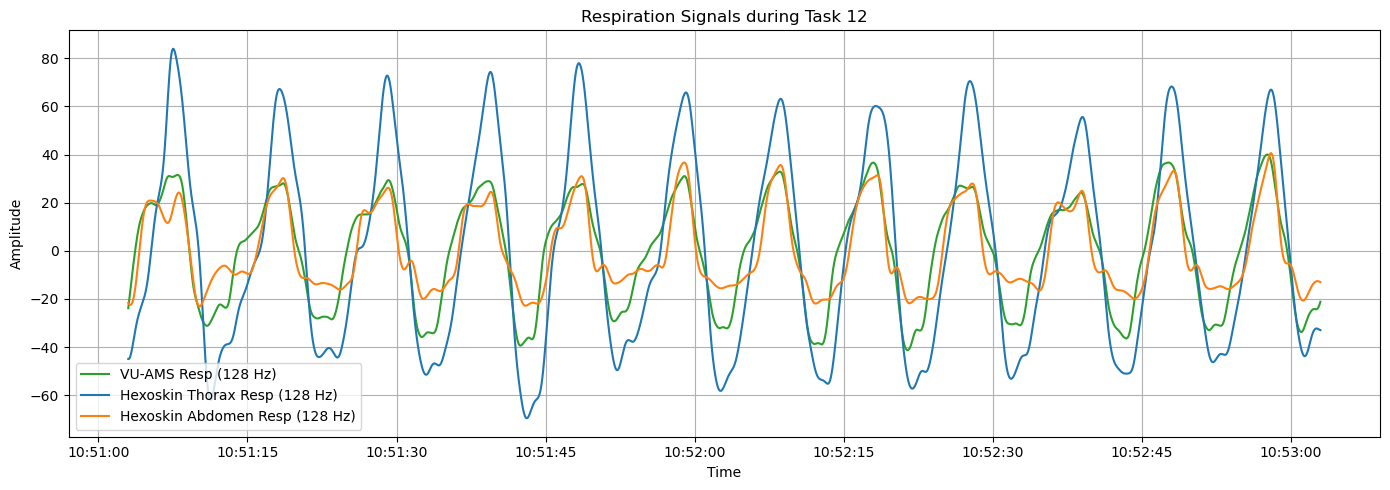

In [219]:
#import the library we will use to plot
import matplotlib.pyplot as plt
plt.figure(figsize=(14, 6))

# plot the spirometer signal from the signals dataframe - for visualization purposes
plt.plot(signals['RSP_Clean'], label="RSP_Clean", color='blue')

# plot a red triangle for when there are detected peaks
if signals['RSP_Peaks'].sum() > 0:  #if at least one peak exists, proceed with plotting
    peak_indices = signals.index[signals['RSP_Peaks'] == 1] #makes an array for the index of each peak
    print(peak_indices)
    plt.scatter(peak_indices, signals.loc[peak_indices, 'RSP_Clean'], color='red', label='Peaks', marker='^', s=100, edgecolor='black') #X is peak indices
                                                                                                                 #Y is the signals value at the index

# plot a green triangle for when there are detected troughs
if signals['RSP_Troughs'].sum() > 0:  #if at least one trough exists, proceed with plotting
    trough_indices = signals.index[signals['RSP_Troughs'] == 1] #makes an array for the index of each trough
    print(trough_indices)
    plt.scatter(trough_indices, signals.loc[trough_indices, 'RSP_Clean'], color='green', label='Troughs', marker='v', s=100, edgecolor='black')

plt.title('RSP_Clean Signal Spirometer with the detected Peaks and Troughs')
plt.xlabel('Sample Index')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True)
plt.show()

#plot the three signals on top of each other, separately for each task
import matplotlib.pyplot as plt

tasks_to_plot = [12] #the standing spirometer task

for task in tasks_to_plot:
    # Filter each signal's DataFrame for the current task
    vuams_task = vuams_df[vuams_df["Label"] == task]
    thorax_task = hexoskin_thorax_df[hexoskin_thorax_df["Label"] == task]
    abdomen_task = hexoskin_abdomen_df[hexoskin_abdomen_df["Label"] == task]

    plt.figure(figsize=(14, 5))
    plt.plot(vuams_task.index, vuams_task["signal"], label="VU-AMS Resp (128 Hz)", color='tab:green')
    plt.plot(thorax_task.index, thorax_task["signal"], label="Hexoskin Thorax Resp (128 Hz)", color='tab:blue')
    plt.plot(abdomen_task.index, abdomen_task["signal"], label="Hexoskin Abdomen Resp (128 Hz)", color='tab:orange')

    plt.title(f"Respiration Signals during Task {task}")
    plt.xlabel("Time")
    plt.ylabel("Amplitude")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [220]:
# define a list to store the tidal volume values for each peak
tidal_volumes_standing = []

for peak_idx in signals.index[signals['RSP_Peaks'] == 1]: #identify where there are peaks
    # find the preceding trough
    preceding_troughs = signals.index[(signals['RSP_Troughs'] == 1) & (signals.index < peak_idx)] #gives list of all preceding troughs for a given peak
    
    if not preceding_troughs.empty:
        trough_idx = preceding_troughs[-1]  # select the last trough in the list (to get the most recent trough)
        tidal_volume = signals.loc[peak_idx, 'RSP_Raw'] - signals.loc[trough_idx, 'RSP_Raw']  #subtract the value of the give peak from that of the
                                                                                                #preceding trough
        tidal_volumes_standing.append(tidal_volume) #the calculated tidal volume gets appended to the previously created list

# make the tidal volume list a mumpy array
tv_standing_spiro = np.array(tidal_volumes_standing)
print(tv_standing_spiro)
print(len(tv_standing_spiro))


[2.14765981 2.59810108 2.04987985 2.12560338 2.07429475 2.02826924
 1.90354675 1.66025174 1.82820472 2.14254895 1.91507655]
11


### CALIBRATING VUAMS RESPIRATION

In [221]:
import neurokit2 as nk
#implementing the respiratory processing function from neurokit2 to automatically detect the peaks and troughs
signals_vuams_12, info = nk.rsp_process(vuams_resp_12, sampling_rate=128)
signals_vuams_12       #the first output (signals) generates a  dataframe that includes the raw signal values and RSP_Peaks and RSP_Troughs
              #info stores a dictionary with the arrays for the RSP_Peaks, RSP_Troughs, sampling rate

,RSP_Raw,RSP_Clean,RSP_Amplitude,RSP_Rate,RSP_RVT,RSP_Phase,RSP_Phase_Completion,RSP_Symmetry_PeakTrough,RSP_Symmetry_RiseDecay,RSP_Peaks,RSP_Troughs
0,0.0,0.286037,53.100207,6.073329,0.076536,NaN,0.0,0.421090,0.634809,0,0
1,0.0,0.285514,53.100207,6.073329,0.076432,NaN,0.0,0.421090,0.634809,0,0
2,0.0,0.284986,53.100207,6.073329,0.076324,NaN,0.0,0.421090,0.634809,0,0
3,0.0,0.284456,53.100207,6.073329,0.076213,NaN,0.0,0.421090,0.634809,0,0
4,0.0,0.283921,53.100207,6.073329,0.076099,NaN,0.0,0.421090,0.634809,0,0
...,...,...,...,...,...,...,...,...,...,...,...
17915,0.0,0.008901,70.452675,7.218045,0.052993,NaN,0.0,0.468667,0.510338,0,0
17916,0.0,0.007957,70.452675,7.218045,0.053054,NaN,0.0,0.468667,0.510338,0,0
17917,0.0,0.007049,70.452675,7.218045,0.053115,NaN,0.0,0.468667,0.510338,0,0
17918,0.0,0.006182,70.452675,7.218045,0.053176,NaN,0.0,0.468667,0.510338,0,0


Index([1925, 3277, 4634, 5927, 7134, 8447, 9677, 10880, 11996, 13557, 14683,
       15957],
      dtype='int64')
Index([1294, 2288, 3903, 5062, 6332, 7537, 8991, 10214, 11319, 12768, 14140,
       15204],
      dtype='int64')


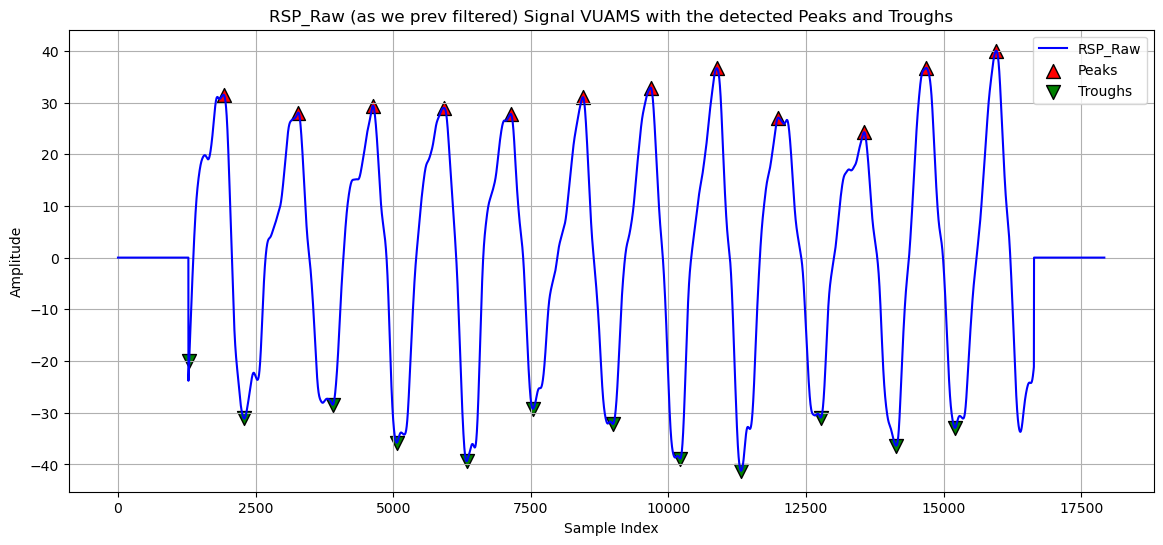

In [222]:
import matplotlib.pyplot as plt
plt.figure(figsize=(14, 6))

# plot the raw spirometer signal from the signals dataframe
plt.plot(signals_vuams_12['RSP_Raw'], label="RSP_Raw", color='blue')

# plot a red triangle for when there are detected peaks
if signals_vuams_12['RSP_Peaks'].sum() > 0:  #if at least one peak exists, proceed with plotting
    peak_indices = signals_vuams_12.index[signals_vuams_12['RSP_Peaks'] == 1] #makes an array for the index of each peak
    print(peak_indices)
    plt.scatter(peak_indices, signals_vuams_12.loc[peak_indices, 'RSP_Raw'], color='red', label='Peaks', marker='^', s=100, edgecolor='black') #X is peak indices
                                                                                                                 #Y is the signals value at the index

# plot a green triangle for when there are detected troughs
if signals_vuams_12['RSP_Troughs'].sum() > 0:  #if at least one trough exists, proceed with plotting
    trough_indices = signals_vuams_12.index[signals_vuams_12['RSP_Troughs'] == 1] #makes an array for the index of each trough
    print(trough_indices)
    plt.scatter(trough_indices, signals_vuams_12.loc[trough_indices, 'RSP_Raw'], color='green', label='Troughs', marker='v', s=100, edgecolor='black')

plt.title('RSP_Raw (as we prev filtered) Signal VUAMS with the detected Peaks and Troughs')
plt.xlabel('Sample Index')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True)
plt.show()


In [223]:
# define a list to store the tidal volume values for each peak
vuams_depths_standing = []

for peak_idx in signals_vuams_12.index[signals_vuams_12['RSP_Peaks'] == 1]: #identify where there are peaks
    # find the preceding trough
    preceding_troughs = signals_vuams_12.index[(signals_vuams_12['RSP_Troughs'] == 1) & (signals_vuams_12.index < peak_idx)] #gives list of all preceding troughs for a given peak
    
    if not preceding_troughs.empty:
        trough_idx = preceding_troughs[-1]  # select the last trough in the list (to get the most recent trough)
        tidal_volume = signals_vuams_12.loc[peak_idx, 'RSP_Raw'] - signals_vuams_12.loc[trough_idx, 'RSP_Raw']  #subtract the value of the give peak from that of the
                                                                                                #preceding trough
        vuams_depths_standing.append(tidal_volume) #the calculated respiratory depths gets appended to the previously created list

# make the tidal volume list a mumpy array
vuams_depths_standing = np.array(vuams_depths_standing)
print(vuams_depths_standing)
print(len(vuams_depths_standing))

[51.48485843 59.16163249 57.83041003 64.73942104 67.18394174 60.28071598
 65.07205775 75.51072656 68.30793261 55.18753057 73.05555716 72.9576902 ]
12


Index([3747, 5850, 8078, 10197, 12272, 14105, 16208, 18119, 20079, 21962,
       24172],
      dtype='int64')
Index([2603, 4956, 6736, 9175, 11020, 13028, 14882, 16968, 18899, 20822,
       22851],
      dtype='int64')


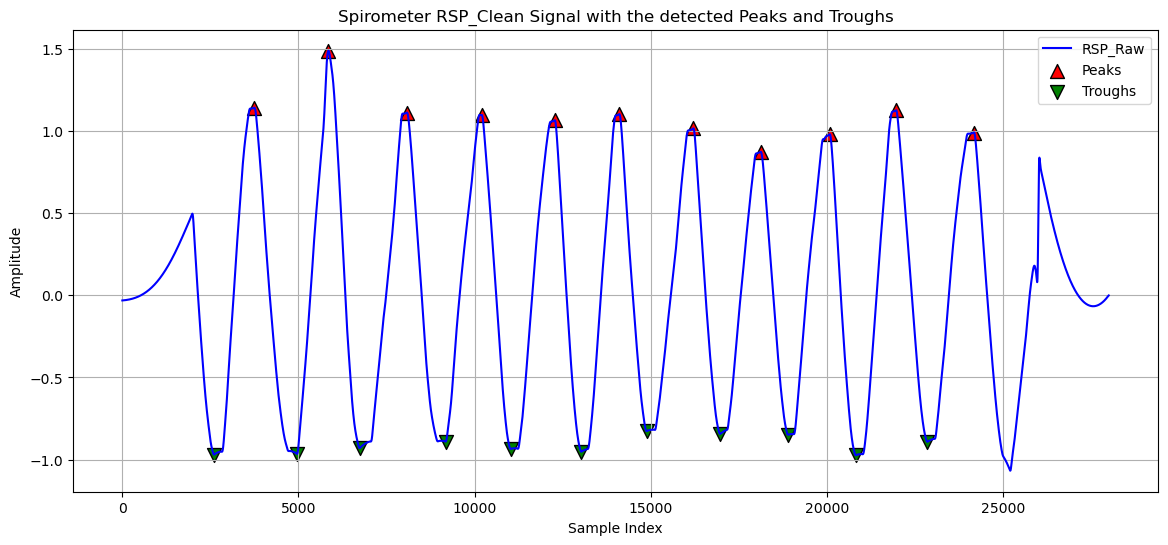

11
Index([1925, 3277, 4634, 5927, 7134, 8447, 9677, 10880, 11996, 13557, 14683,
       15957],
      dtype='int64')
Index([1294, 2288, 3903, 5062, 6332, 7537, 8991, 10214, 11319, 12768, 14140,
       15204],
      dtype='int64')


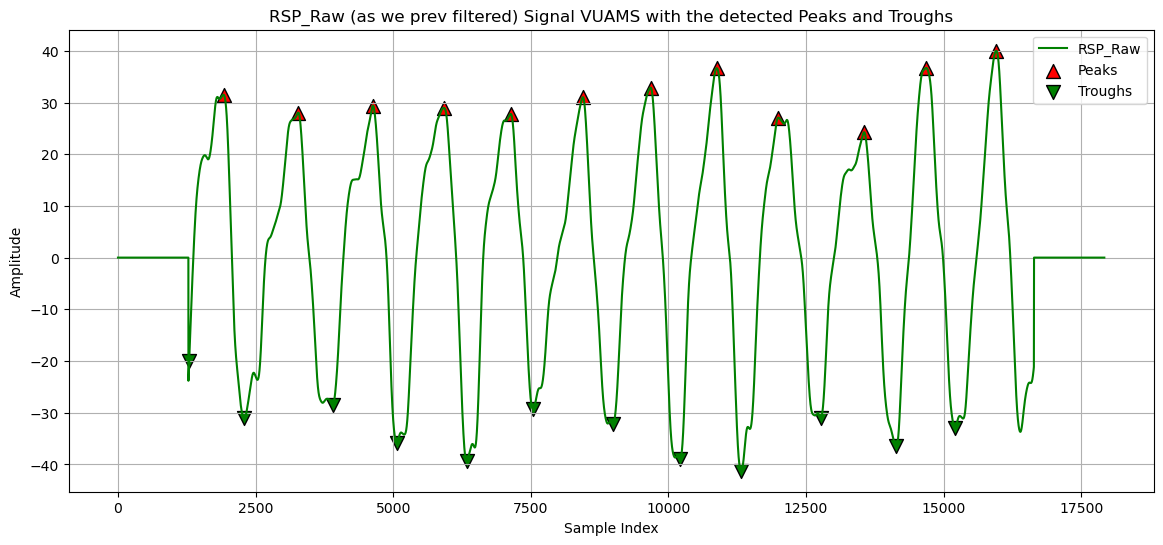

12


In [224]:
#PLOT THE SPIROMETER AND THE IMPEDANCE - STANDING
#import the library we will use to plot
import matplotlib.pyplot as plt
plt.figure(figsize=(14, 6))

# plot the raw spirometer signal from the signals dataframe
plt.plot(signals['RSP_Clean'], label="RSP_Raw", color='blue')

# plot a red triangle for when there are detected peaks
if signals['RSP_Peaks'].sum() > 0:  #if at least one peak exists, proceed with plotting
    peak_indices = signals.index[signals['RSP_Peaks'] == 1] #makes an array for the index of each peak
    print(peak_indices)
    plt.scatter(peak_indices, signals.loc[peak_indices, 'RSP_Clean'], color='red', label='Peaks', marker='^', s=100, edgecolor='black') #X is peak indices
                                                                                                                 #Y is the signals value at the index

# plot a green triangle for when there are detected troughs
if signals['RSP_Troughs'].sum() > 0:  #if at least one trough exists, proceed with plotting
    trough_indices = signals.index[signals['RSP_Troughs'] == 1] #makes an array for the index of each trough
    print(trough_indices)
    plt.scatter(trough_indices, signals.loc[trough_indices, 'RSP_Clean'], color='green', label='Troughs', marker='v', s=100, edgecolor='black')

plt.title('Spirometer RSP_Clean Signal with the detected Peaks and Troughs')
plt.xlabel('Sample Index')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True)
plt.show()

print(len(tv_standing_spiro))


import matplotlib.pyplot as plt
plt.figure(figsize=(14, 6))

# plot the "raw" (prev. filtered) impedance signal
plt.plot(signals_vuams_12['RSP_Raw'], label="RSP_Raw", color='green')

# plot a red triangle for when there are detected peaks
if signals_vuams_12['RSP_Peaks'].sum() > 0:  #if at least one peak exists, proceed with plotting
    peak_indices = signals_vuams_12.index[signals_vuams_12['RSP_Peaks'] == 1] #makes an array for the index of each peak
    print(peak_indices)
    plt.scatter(peak_indices, signals_vuams_12.loc[peak_indices, 'RSP_Raw'], color='red', label='Peaks', marker='^', s=100, edgecolor='black') #X is peak indices
                                                                                                                 #Y is the signals value at the index
# plot a green triangle for when there are detected troughs
if signals_vuams_12['RSP_Troughs'].sum() > 0:  #if at least one trough exists, proceed with plotting
    trough_indices = signals_vuams_12.index[signals_vuams_12['RSP_Troughs'] == 1] #makes an array for the index of each trough
    print(trough_indices)
    plt.scatter(trough_indices, signals_vuams_12.loc[trough_indices, 'RSP_Raw'], color='green', label='Troughs', marker='v', s=100, edgecolor='black')

plt.title('RSP_Raw (as we prev filtered) Signal VUAMS with the detected Peaks and Troughs')
plt.xlabel('Sample Index')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True)
plt.show()

print(len(vuams_depths_standing))


In [ ]:
#drop the first cycle from impedance
#vuams_depths_standing = vuams_depths_standing[1:]
#drop the last cycle from both arrays
#vuams_depths_standing = vuams_depths_standing[:-1]
#tv_standing_spiro = tv_standing_spiro[:-1]

In [225]:
#delete the last cycle of spirometer
tv_standing_spiro = tv_standing_spiro[:-1]
#delete the first two cycles of vuams
vuams_depths_standing = vuams_depths_standing[2:]

In [226]:
print(len(tv_standing_spiro))
print(len(vuams_depths_standing))

10
10


In [227]:
#here we solve for beta (slope and intercept) such that we create a least squares regression of spirometer volume being predicted by
#impedance value times some slope plus an intercept
#specifically, we use the Moore-Penrose pseudoinverse way of solving for the regression coefficients - using the ordinary least squares formula
#under statsmodels give the same answers
import numpy as np
assert len(vuams_depths_standing) == len(tv_standing_spiro)
print(vuams_depths_standing)
X = vuams_depths_standing[:, np.newaxis]  # convert impedance to a 2D array, necessary for linear regression in matrix format
print(X)
y = tv_standing_spiro  # spirometer volumes
print(y)

# add a columns of ones to include an intercept in the regression
X = np.column_stack((np.ones(len(vuams_depths_standing)), X))  # Augment X with a column of ones
print(X)

# calculate the pseudoinverse of the matrix X
X_pinv = np.linalg.pinv(X)

# multiply the pseudoinverse of X with the outcome variable y to calculate the slope and intercept
conversion_coefficients_standing = np.dot(X_pinv, y) #dot product function for matrix multiplication
print(conversion_coefficients_standing)

# print the conversion coefficients
vuams_intercept_standing, vuams_slope_standing = conversion_coefficients_standing  #to be saved at the end  of the document
print(f"Conversion coefficients: Intercept = {vuams_intercept_standing}, Slope = {vuams_slope_standing}")


[57.83041003 64.73942104 67.18394174 60.28071598 65.07205775 75.51072656
 68.30793261 55.18753057 73.05555716 72.9576902 ]
[[57.83041003]
 [64.73942104]
 [67.18394174]
 [60.28071598]
 [65.07205775]
 [75.51072656]
 [68.30793261]
 [55.18753057]
 [73.05555716]
 [72.9576902 ]]
[2.14765981 2.59810108 2.04987985 2.12560338 2.07429475 2.02826924
 1.90354675 1.66025174 1.82820472 2.14254895]
[[ 1.         57.83041003]
 [ 1.         64.73942104]
 [ 1.         67.18394174]
 [ 1.         60.28071598]
 [ 1.         65.07205775]
 [ 1.         75.51072656]
 [ 1.         68.30793261]
 [ 1.         55.18753057]
 [ 1.         73.05555716]
 [ 1.         72.9576902 ]]
[1.9277078  0.00194097]
Conversion coefficients: Intercept = 1.9277077966326521, Slope = 0.0019409663086008624


In [228]:
import statsmodels.api as sm 
import pandas as pd          
import matplotlib.pyplot as plt 
import numpy as np
# cross-checking to see if we get the same parameters with the ordinary least squares function
x = vuams_depths_standing
y = tv_standing_spiro
x = sm.add_constant(x)
result = sm.OLS(y, x).fit()
print(result.summary()) #we do get the same findings

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.003
Model:                            OLS   Adj. R-squared:                 -0.122
Method:                 Least Squares   F-statistic:                   0.02287
Date:                Thu, 16 Apr 2026   Prob (F-statistic):              0.884
Time:                        12:04:32   Log-Likelihood:                0.34977
No. Observations:                  10   AIC:                             3.300
Df Residuals:                       8   BIC:                             3.906
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.9277      0.851      2.264      0.0

C:\Users\msa583\AppData\Local\anaconda3\Lib\site-packages\scipy\stats\_axis_nan_policy.py:531: UserWarning: kurtosistest only valid for n>=20 ... continuing anyway, n=10
  res = hypotest_fun_out(*samples, **kwds)


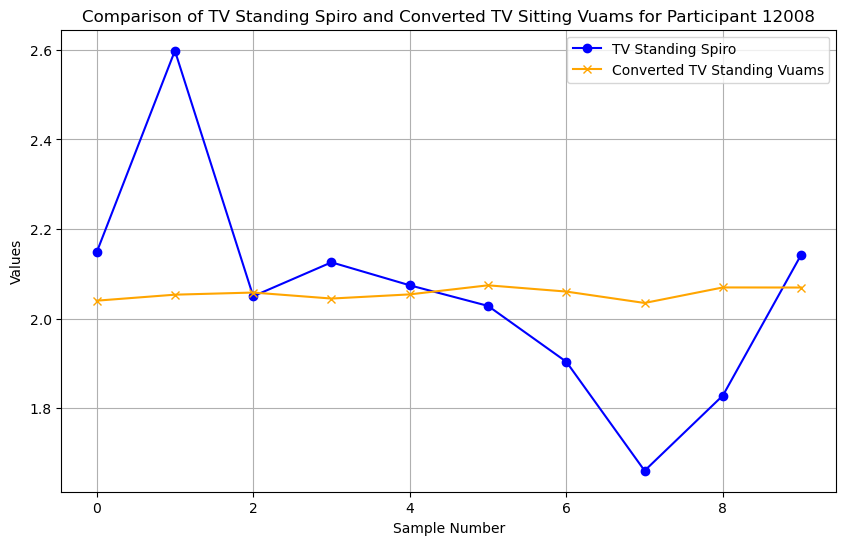

In [229]:
# applying the calculated conversion slope and intercept to the impedance amplitude values
tv_standing_vuams_converted = (vuams_depths_standing * vuams_slope_standing) + vuams_intercept_standing

plt.figure(figsize=(10, 6))

# plot the actual tidal volumes obtained via spirometer
plt.plot(tv_standing_spiro, label='TV Standing Spiro', color='blue', marker='o')

# plot the calibrated impedance volumes
plt.plot(tv_standing_vuams_converted, label='Converted TV Standing Vuams', color='orange', marker='x')

plt.title(f'Comparison of TV Standing Spiro and Converted TV Sitting Vuams for Participant {ppid}')
plt.xlabel('Sample Number')
plt.ylabel('Values')
plt.legend() 
plt.grid()   
plt.show()

In [230]:
y = tv_standing_spiro  # spirometer volumes

# calculate mean absolute percentage error (MAPE) for the supine spirometer calibration
vuams_mape_standing = np.mean(np.abs((y - tv_standing_vuams_converted) / (y))) * 100
print(f"mean absolute percentage error (MAPE): {vuams_mape_standing:.4f}%") #to be saved at the end of the script

mean absolute percentage error (MAPE): 8.0847%


In [231]:
#calculate the root mean squared errors (RMSE) for the impedance supine calibration
# calculate squared errors
actual = tv_standing_spiro
predicted = tv_standing_vuams_converted

squared_errors = (actual - predicted) ** 2

# find the mean of squared errors
mse = np.mean(squared_errors)

# take the square root to get RMSE
rmse = np.sqrt(mse)

vuams_rmse_standing = rmse
print("Root Mean Squared Error:", vuams_rmse_standing)

Root Mean Squared Error: 0.23365366024216772


### CALIBRATING HEXOSKIN RESPIRATION

In [232]:
# Repeating the sitting spirometer peak-valley detection and amplitude calculation from the start (same as done for VUAMS)
#the dataframe also has the flow rate and time but we are not interested in those, so selecting the tidal volume column
spirometer_standing = volume_standing['Data Set 4:Volume(L)'] #here, you might need to change the number of the data set

#converting the data format from float64 to numpy array format for later peak valley detection using neurokit2
spirometer_standing = np.array(spirometer_standing)

# only select the first 120 seconds of the signal (the first 2400 rows due to the sampling rate being 200)
spirometer_standing = spirometer_standing[:24000]

#doing zero padding of 10 seconds (signal sampling rate was 200 Hz) to the beginning and ending of the signal
spirometer_standing = np.concatenate([np.zeros(2000), spirometer_standing, np.zeros(2000)])
print(spirometer_standing)

import neurokit2 as nk
#implementing the respiratory processing function from neurokit2 to automatically detect the peaks and troughs
signals, info = nk.rsp_process(spirometer_standing, sampling_rate=200) #overwriting the previous signals variable
signals       #the first output (signals) generates a  dataframe that includes the raw signal values and RSP_Peaks and RSP_Troughs
              #info stores a dictionary with the arrays for the RSP_Peaks, RSP_Troughs, sampling rate

# (re)define a list to store the (spirometer) tidal volume values for each peak for the sitting posture
tidal_volumes_standing = []

for peak_idx in signals.index[signals['RSP_Peaks'] == 1]: #identify where there are peaks
    # find the preceding trough
    preceding_troughs = signals.index[(signals['RSP_Troughs'] == 1) & (signals.index < peak_idx)] #gives list of all preceding troughs for a given peak
    
    if not preceding_troughs.empty:
        trough_idx = preceding_troughs[-1]  # select the last trough in the list (to get the most recent trough)
        tidal_volume = signals.loc[peak_idx, 'RSP_Raw'] - signals.loc[trough_idx, 'RSP_Raw']  #subtract the value of the give peak from that of the
                                                                                                #preceding trough
        tidal_volumes_standing.append(tidal_volume) #the calculated tidal volume gets appended to the previously created list

# make the tidal volume list a mumpy array
tv_standing_spiro = np.array(tidal_volumes_standing)
print(tv_standing_spiro)
print(len(tv_standing_spiro))

[0. 0. 0. ... 0. 0. 0.]
[2.14765981 2.59810108 2.04987985 2.12560338 2.07429475 2.02826924
 1.90354675 1.66025174 1.82820472 2.14254895 1.91507655]
11


In [233]:
import neurokit2 as nk
#implementing the respiratory processing function from neurokit2 to automatically detect the peaks and troughs
signals_hexoskin_thorax_12, info = nk.rsp_process(hexoskin_thorax_12, sampling_rate=128)
signals_hexoskin_thorax_12       #the first output (signals) generates a  dataframe that includes the raw signal values and RSP_Peaks and RSP_Troughs
              #info stores a dictionary with the arrays for the RSP_Peaks, RSP_Troughs, sampling rate

,RSP_Raw,RSP_Clean,RSP_Amplitude,RSP_Rate,RSP_RVT,RSP_Phase,RSP_Phase_Completion,RSP_Symmetry_PeakTrough,RSP_Symmetry_RiseDecay,RSP_Peaks,RSP_Troughs
0,0.0,0.563904,125.473341,6.054612,0.080673,NaN,0.0,0.612082,0.539499,0,0
1,0.0,0.564948,125.473341,6.054612,0.080580,NaN,0.0,0.612082,0.539499,0,0
2,0.0,0.565991,125.473341,6.054612,0.080483,NaN,0.0,0.612082,0.539499,0,0
3,0.0,0.567034,125.473341,6.054612,0.080382,NaN,0.0,0.612082,0.539499,0,0
4,0.0,0.568078,125.473341,6.054612,0.080277,NaN,0.0,0.612082,0.539499,0,0
...,...,...,...,...,...,...,...,...,...,...,...
17915,0.0,0.018574,108.512609,6.962829,0.029357,NaN,0.0,0.597258,0.518586,0,0
17916,0.0,0.016630,108.512609,6.962829,0.029463,NaN,0.0,0.597258,0.518586,0,0
17917,0.0,0.014757,108.512609,6.962829,0.029569,NaN,0.0,0.597258,0.518586,0,0
17918,0.0,0.012962,108.512609,6.962829,0.029675,NaN,0.0,0.597258,0.518586,0,0


Index([1860, 3228, 4616, 5947, 7085, 8466, 9686, 10916, 12123, 13575, 14722,
       16003],
      dtype='int64')
Index([1300, 2338, 3730, 5114, 6413, 7577, 8908, 10293, 11378, 12650, 14150,
       15253],
      dtype='int64')


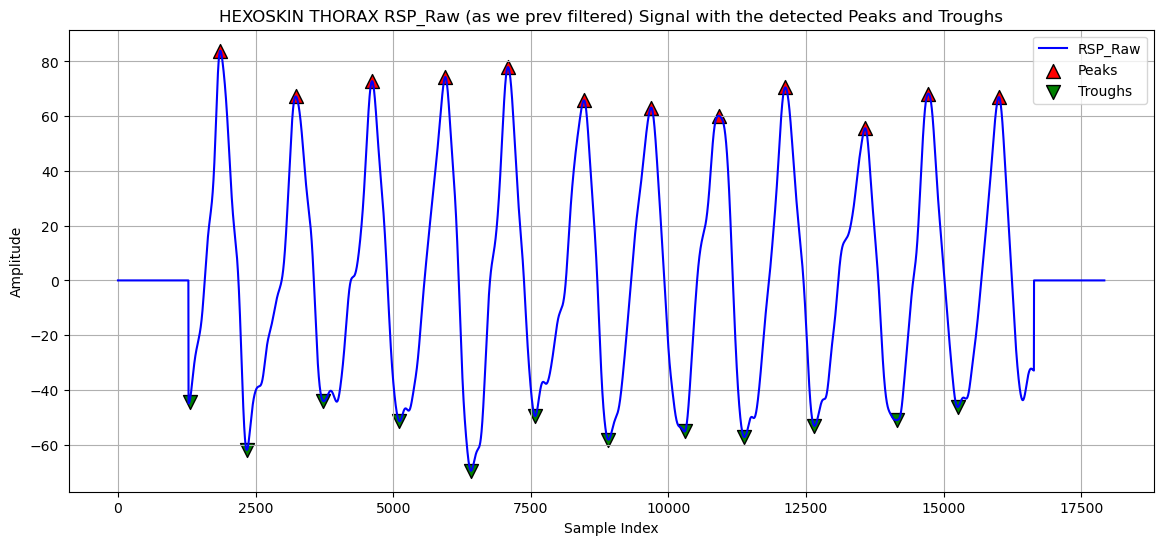

In [234]:
#import the library we will use to plot
import matplotlib.pyplot as plt
plt.figure(figsize=(14, 6))

# plot the "raw" (we already previously filtered) hexoskin signal from the signals dataframe
plt.plot(signals_hexoskin_thorax_12['RSP_Raw'], label="RSP_Raw", color='blue')

# plot a red triangle for when there are detected peaks
if signals_hexoskin_thorax_12['RSP_Peaks'].sum() > 0:  #if at least one peak exists, proceed with plotting
    peak_indices = signals_hexoskin_thorax_12.index[signals_hexoskin_thorax_12['RSP_Peaks'] == 1] #makes an array for the index of each peak
    print(peak_indices)
    plt.scatter(peak_indices, signals_hexoskin_thorax_12.loc[peak_indices, 'RSP_Raw'], color='red', label='Peaks', marker='^', s=100, edgecolor='black') #X is peak indices
                                                                                                                 #Y is the signals value at the index

# plot a green triangle for when there are detected troughs
if signals_hexoskin_thorax_12['RSP_Troughs'].sum() > 0:  #if at least one trough exists, proceed with plotting
    trough_indices = signals_hexoskin_thorax_12.index[signals_hexoskin_thorax_12['RSP_Troughs'] == 1] #makes an array for the index of each trough
    print(trough_indices)
    plt.scatter(trough_indices, signals_hexoskin_thorax_12.loc[trough_indices, 'RSP_Raw'], color='green', label='Troughs', marker='v', s=100, edgecolor='black')

plt.title('HEXOSKIN THORAX RSP_Raw (as we prev filtered) Signal with the detected Peaks and Troughs')
plt.xlabel('Sample Index')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True)
plt.show()

In [235]:
# define a list to store the tidal volume values for each peak
hexoskin_thorax_depths_standing = []

for peak_idx in signals_hexoskin_thorax_12.index[signals_hexoskin_thorax_12['RSP_Peaks'] == 1]: #identify where there are peaks
    # find the preceding trough
    preceding_troughs = signals_hexoskin_thorax_12.index[(signals_hexoskin_thorax_12['RSP_Troughs'] == 1) & (signals_hexoskin_thorax_12.index < peak_idx)] #gives list of all preceding troughs for a given peak
    
    if not preceding_troughs.empty:
        trough_idx = preceding_troughs[-1]  # select the last trough in the list (to get the most recent trough)
        tidal_volume = signals_hexoskin_thorax_12.loc[peak_idx, 'RSP_Raw'] - signals_hexoskin_thorax_12.loc[trough_idx, 'RSP_Raw']  #subtract the value of the give peak from that of the
                                                                                                #preceding trough
        hexoskin_thorax_depths_standing.append(tidal_volume) #the calculated respiratory depths gets appended to the previously created list

# make the tidal volume list a numpy array
hexoskin_thorax_depths_standing = np.array(hexoskin_thorax_depths_standing)
print(hexoskin_thorax_depths_standing)
print(len(hexoskin_thorax_depths_standing))

[128.27282514 129.13450661 116.89948604 125.76852837 147.47609114
 115.36355417 121.32316084 115.34567963 127.7271245  108.72384895
 119.25775732 113.20585803]
12


Index([3747, 5850, 8078, 10197, 12272, 14105, 16208, 18119, 20079, 21962,
       24172],
      dtype='int64')
Index([2603, 4956, 6736, 9175, 11020, 13028, 14882, 16968, 18899, 20822,
       22851],
      dtype='int64')


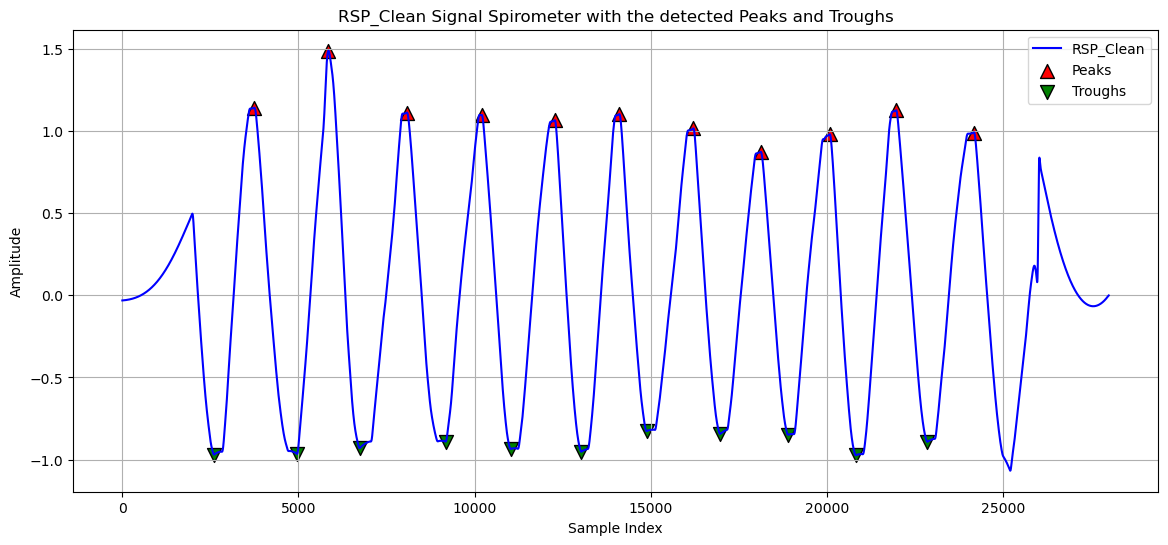

11
Index([1860, 3228, 4616, 5947, 7085, 8466, 9686, 10916, 12123, 13575, 14722,
       16003],
      dtype='int64')
Index([1300, 2338, 3730, 5114, 6413, 7577, 8908, 10293, 11378, 12650, 14150,
       15253],
      dtype='int64')


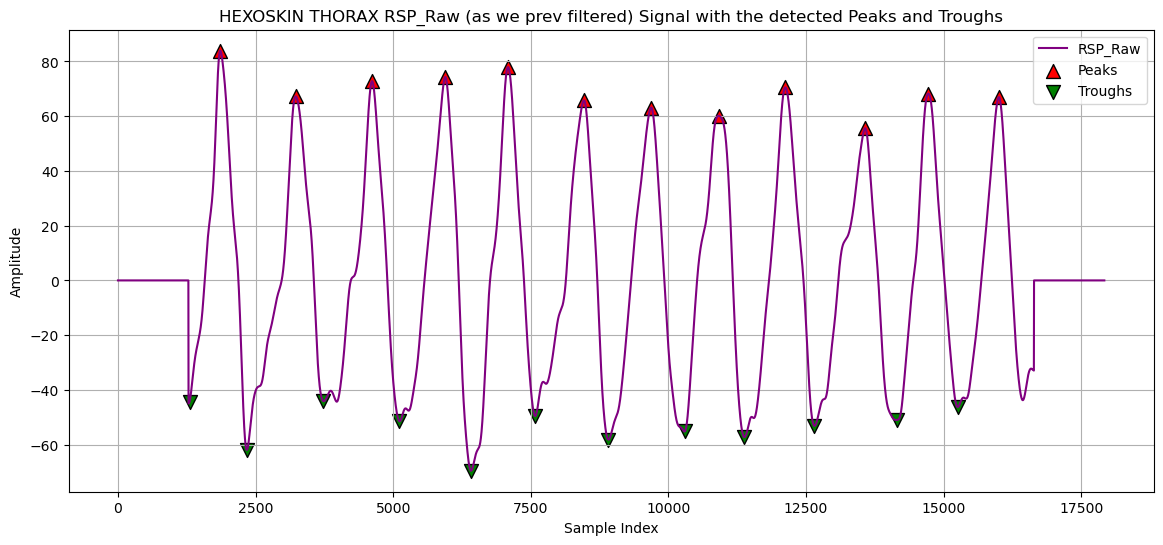

12


In [236]:
#PLOT THE SPIROMETER AGAINST THE HEXOSKIN THORAX - STANDING
import matplotlib.pyplot as plt
plt.figure(figsize=(14, 6))

# plot the spirometer signal from the signals dataframe
plt.plot(signals['RSP_Clean'], label="RSP_Clean", color='blue')

# plot a red triangle for when there are detected peaks
if signals['RSP_Peaks'].sum() > 0:  #if at least one peak exists, proceed with plotting
    peak_indices = signals.index[signals['RSP_Peaks'] == 1] #makes an array for the index of each peak
    print(peak_indices)
    plt.scatter(peak_indices, signals.loc[peak_indices, 'RSP_Clean'], color='red', label='Peaks', marker='^', s=100, edgecolor='black') #X is peak indices
                                                                                                                 #Y is the signals value at the index

# plot a green triangle for when there are detected troughs
if signals['RSP_Troughs'].sum() > 0:  #if at least one trough exists, proceed with plotting
    trough_indices = signals.index[signals['RSP_Troughs'] == 1] #makes an array for the index of each trough
    print(trough_indices)
    plt.scatter(trough_indices, signals.loc[trough_indices, 'RSP_Clean'], color='green', label='Troughs', marker='v', s=100, edgecolor='black')

plt.title('RSP_Clean Signal Spirometer with the detected Peaks and Troughs')
plt.xlabel('Sample Index')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True)
plt.show()

print(len(tv_standing_spiro))

import matplotlib.pyplot as plt
plt.figure(figsize=(14, 6))

# plot the "raw" hexoskin thorax
plt.plot(signals_hexoskin_thorax_12['RSP_Raw'], label="RSP_Raw", color='purple')

# plot a red triangle for when there are detected peaks
if signals_hexoskin_thorax_12['RSP_Peaks'].sum() > 0:  #if at least one peak exists, proceed with plotting
    peak_indices = signals_hexoskin_thorax_12.index[signals_hexoskin_thorax_12['RSP_Peaks'] == 1] #makes an array for the index of each peak
    print(peak_indices)
    plt.scatter(peak_indices, signals_hexoskin_thorax_12.loc[peak_indices, 'RSP_Raw'], color='red', label='Peaks', marker='^', s=100, edgecolor='black') #X is peak indices
                                                                                                                 #Y is the signals value at the index
# plot a green triangle for when there are detected troughs
if signals_hexoskin_thorax_12['RSP_Troughs'].sum() > 0:  #if at least one trough exists, proceed with plotting
    trough_indices = signals_hexoskin_thorax_12.index[signals_hexoskin_thorax_12['RSP_Troughs'] == 1] #makes an array for the index of each trough
    print(trough_indices)
    plt.scatter(trough_indices, signals_hexoskin_thorax_12.loc[trough_indices, 'RSP_Raw'], color='green', label='Troughs', marker='v', s=100, edgecolor='black')

plt.title('HEXOSKIN THORAX RSP_Raw (as we prev filtered) Signal with the detected Peaks and Troughs')
plt.xlabel('Sample Index')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True)
plt.show()

print(len(hexoskin_thorax_depths_standing))

In [ ]:
#drop the first cycle from both arrays
#tv_standing_spiro = tv_standing_spiro[1:]
#hexoskin_thorax_depths_standing = hexoskin_thorax_depths_standing[1:]

In [237]:
#delete the last cycle of spirometer
tv_standing_spiro = tv_standing_spiro[:-1]
#delete the first two cycles of hexoskin thorax
hexoskin_thorax_depths_standing = hexoskin_thorax_depths_standing[2:]

In [238]:
print(len(hexoskin_thorax_depths_standing))
print(len(tv_standing_spiro))

10
10


In [239]:
#THIS IS FOR RIP - THORAX ONLY CALIBRATION, NOT THE THORACOABDOMINAL CALIBRATION!!
#here we solve for beta (slope and intercept) such that we create a least squares regression of spirometer volume being predicted by
#impedance value times some slope plus an intercept
#specifically, we use the Moore-Penrose pseudoinverse way of solving for the regression coefficients - using the ordinary least squares formula
#under statsmodels give the same answers
import numpy as np
assert len(hexoskin_thorax_depths_standing) == len(tv_standing_spiro)
print(hexoskin_thorax_depths_standing)
X = hexoskin_thorax_depths_standing[:, np.newaxis]  # convert impedance to a 2D array, necessary for linear regression in matrix format
print(X)
y = tv_standing_spiro  # spirometer volumes
print(y)

# add a columns of ones to include an intercept in the regression
X = np.column_stack((np.ones(len(hexoskin_thorax_depths_standing)), X))  # Augment X with a column of ones
print(X)

# calculate the pseudoinverse of the matrix X
X_pinv = np.linalg.pinv(X)

# multiply the pseudoinverse of X with the outcome variable y to calculate the slope and intercept
conversion_coefficients_standing = np.dot(X_pinv, y) #dot product function for matrix multiplication
print(conversion_coefficients_standing)

# print the conversion coefficients
hexoskin_thorax_intercept_standing, hexoskin_thorax_slope_standing = conversion_coefficients_standing  #to be saved at the end  of the document
print(f"Conversion coefficients: Intercept = {hexoskin_thorax_intercept_standing}, Slope = {hexoskin_thorax_slope_standing}")


[116.89948604 125.76852837 147.47609114 115.36355417 121.32316084
 115.34567963 127.7271245  108.72384895 119.25775732 113.20585803]
[[116.89948604]
 [125.76852837]
 [147.47609114]
 [115.36355417]
 [121.32316084]
 [115.34567963]
 [127.7271245 ]
 [108.72384895]
 [119.25775732]
 [113.20585803]]
[2.14765981 2.59810108 2.04987985 2.12560338 2.07429475 2.02826924
 1.90354675 1.66025174 1.82820472 2.14254895]
[[  1.         116.89948604]
 [  1.         125.76852837]
 [  1.         147.47609114]
 [  1.         115.36355417]
 [  1.         121.32316084]
 [  1.         115.34567963]
 [  1.         127.7271245 ]
 [  1.         108.72384895]
 [  1.         119.25775732]
 [  1.         113.20585803]]
[1.44429455 0.00504951]
Conversion coefficients: Intercept = 1.4442945473543967, Slope = 0.0050495085316194024


In [240]:
import statsmodels.api as sm 
import pandas as pd          
import matplotlib.pyplot as plt 
import numpy as np
# cross-checking to see if we get the same parameters with the ordinary least squares function
x = hexoskin_thorax_depths_standing
y = tv_standing_spiro
x = sm.add_constant(x)
result = sm.OLS(y, x).fit()
print(result.summary()) #we do get the same findings

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.050
Model:                            OLS   Adj. R-squared:                 -0.069
Method:                 Least Squares   F-statistic:                    0.4171
Date:                Thu, 16 Apr 2026   Prob (F-statistic):              0.536
Time:                        12:06:29   Log-Likelihood:                0.58960
No. Observations:                  10   AIC:                             2.821
Df Residuals:                       8   BIC:                             3.426
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.4443      0.950      1.520      0.1

C:\Users\msa583\AppData\Local\anaconda3\Lib\site-packages\scipy\stats\_axis_nan_policy.py:531: UserWarning: kurtosistest only valid for n>=20 ... continuing anyway, n=10
  res = hypotest_fun_out(*samples, **kwds)


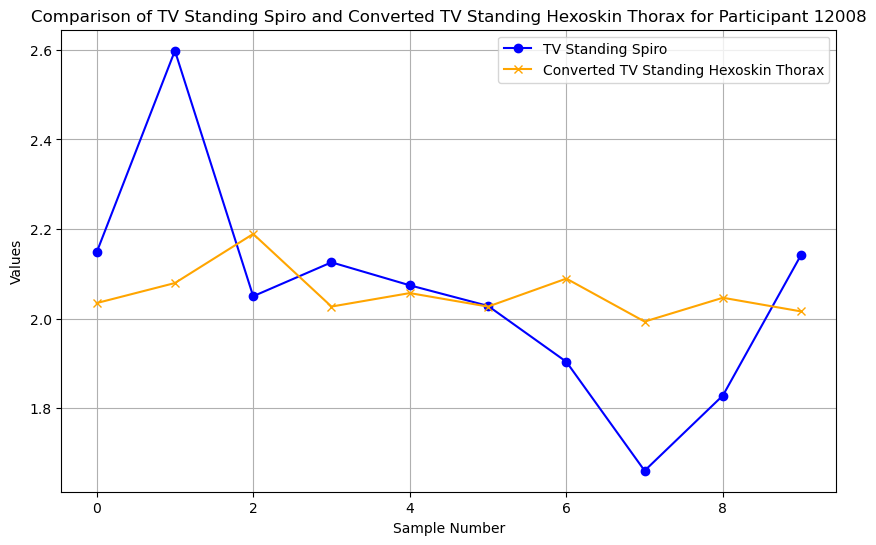

In [241]:
# applying the calculated conversion slope and intercept to the impedance amplitude values
tv_standing_hexoskin_thorax_converted = (hexoskin_thorax_depths_standing * hexoskin_thorax_slope_standing) + hexoskin_thorax_intercept_standing

plt.figure(figsize=(10, 6))

# plot the actual tidal volumes obtained via spirometer
plt.plot(tv_standing_spiro, label='TV Standing Spiro', color='blue', marker='o')

# plot the calibrated impedance volumes
plt.plot(tv_standing_hexoskin_thorax_converted, label='Converted TV Standing Hexoskin Thorax', color='orange', marker='x')

plt.title(f'Comparison of TV Standing Spiro and Converted TV Standing Hexoskin Thorax for Participant {ppid}')
plt.xlabel('Sample Number')
plt.ylabel('Values')
plt.legend() 
plt.grid()   
plt.show()

In [242]:
y = tv_standing_spiro  # spirometer volumes

# calculate mean absolute percentage error (MAPE) for the supine spirometer calibration
hexoskin_thorax_mape_standing = np.mean(np.abs((y - tv_standing_hexoskin_thorax_converted) / (y))) * 100
print(f"mean absolute percentage error (MAPE): {hexoskin_thorax_mape_standing:.4f}%") #to be saved at the end of the script

mean absolute percentage error (MAPE): 8.5243%


In [243]:
#calculate the root mean squared errors (RMSE) for the impedance supine calibration
# calculate squared errors
actual = tv_standing_spiro
predicted = tv_standing_hexoskin_thorax_converted

squared_errors = (actual - predicted) ** 2

# find the mean of squared errors
mse = np.mean(squared_errors)

# take the square root to get RMSE
rmse = np.sqrt(mse)

hexoskin_thorax_rmse_standing = rmse
print("Root Mean Squared Error:", hexoskin_thorax_rmse_standing)

Root Mean Squared Error: 0.22811646122380796


In [244]:
# applying the resp process function on the hexoskin abdomen function and visualizing
import neurokit2 as nk
#implementing the respiratory processing function from neurokit2 to automatically detect the peaks and troughs
signals_hexoskin_abdomen_12, info = nk.rsp_process(hexoskin_abdomen_12, sampling_rate=128)
signals_hexoskin_abdomen_12       #the first output (signals) generates a  dataframe that includes the raw signal values and RSP_Peaks and RSP_Troughs
              #info stores a dictionary with the arrays for the RSP_Peaks, RSP_Troughs, sampling rate

,RSP_Raw,RSP_Clean,RSP_Amplitude,RSP_Rate,RSP_RVT,RSP_Phase,RSP_Phase_Completion,RSP_Symmetry_PeakTrough,RSP_Symmetry_RiseDecay,RSP_Peaks,RSP_Troughs
0,0.0,0.216448,47.988833,5.968631,0.074831,NaN,0.0,0.677249,0.706607,0,0
1,0.0,0.216397,47.988833,5.968631,0.074818,NaN,0.0,0.677249,0.706607,0,0
2,0.0,0.216344,47.988833,5.968631,0.074799,NaN,0.0,0.677249,0.706607,0,0
3,0.0,0.216290,47.988833,5.968631,0.074775,NaN,0.0,0.677249,0.706607,0,0
4,0.0,0.216235,47.988833,5.968631,0.074746,NaN,0.0,0.677249,0.706607,0,0
...,...,...,...,...,...,...,...,...,...,...,...
17915,0.0,0.007527,54.619300,6.357616,0.022924,NaN,0.0,0.662458,0.415563,0,0
17916,0.0,0.006737,54.619300,6.357616,0.023033,NaN,0.0,0.662458,0.415563,0,0
17917,0.0,0.005976,54.619300,6.357616,0.023143,NaN,0.0,0.662458,0.415563,0,0
17918,0.0,0.005247,54.619300,6.357616,0.023253,NaN,0.0,0.662458,0.415563,0,0


Index([1934, 3276, 4629, 5954, 7120, 8444, 9684, 10931, 12154, 13568, 14751,
       16003],
      dtype='int64')
Index([1303, 2196, 4013, 5083, 6399, 7547, 8913, 10135, 11343, 13021, 14249,
       15457],
      dtype='int64')


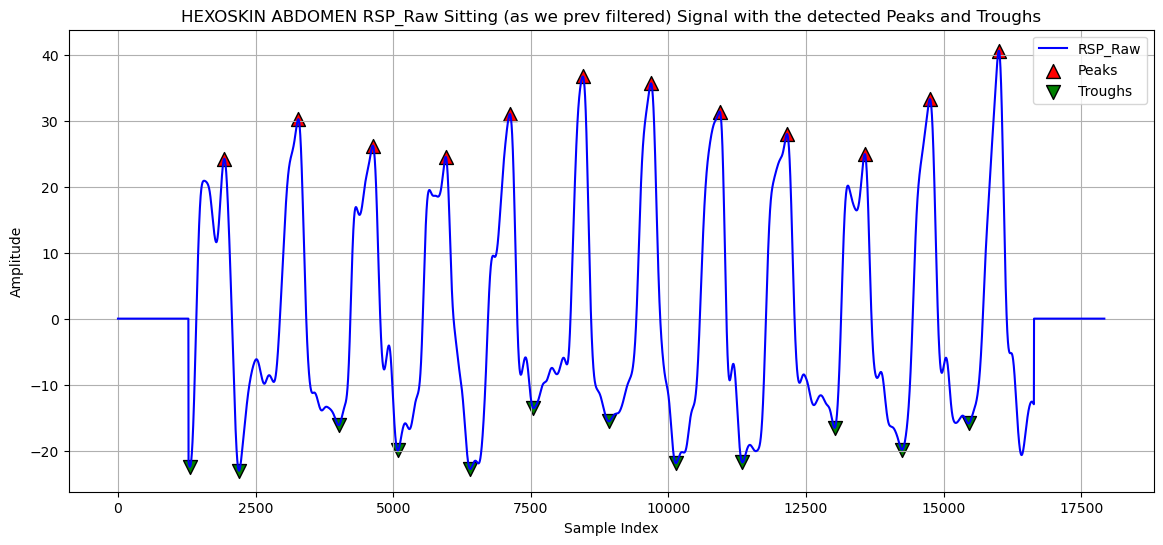

In [245]:
#import the library we will use to plot
import matplotlib.pyplot as plt
plt.figure(figsize=(14, 6))

# plot the hexoskin abdomen signal
plt.plot(signals_hexoskin_abdomen_12['RSP_Raw'], label="RSP_Raw", color='blue')

# plot a red triangle for when there are detected peaks
if signals_hexoskin_abdomen_12['RSP_Peaks'].sum() > 0:  #if at least one peak exists, proceed with plotting
    peak_indices = signals_hexoskin_abdomen_12.index[signals_hexoskin_abdomen_12['RSP_Peaks'] == 1] #makes an array for the index of each peak
    print(peak_indices)
    plt.scatter(peak_indices, signals_hexoskin_abdomen_12.loc[peak_indices, 'RSP_Raw'], color='red', label='Peaks', marker='^', s=100, edgecolor='black') #X is peak indices
                                                                                                                 #Y is the signals value at the index

# plot a green triangle for when there are detected troughs
if signals_hexoskin_abdomen_12['RSP_Troughs'].sum() > 0:  #if at least one trough exists, proceed with plotting
    trough_indices = signals_hexoskin_abdomen_12.index[signals_hexoskin_abdomen_12['RSP_Troughs'] == 1] #makes an array for the index of each trough
    print(trough_indices)
    plt.scatter(trough_indices, signals_hexoskin_abdomen_12.loc[trough_indices, 'RSP_Raw'], color='green', label='Troughs', marker='v', s=100, edgecolor='black')

plt.title('HEXOSKIN ABDOMEN RSP_Raw Sitting (as we prev filtered) Signal with the detected Peaks and Troughs')
plt.xlabel('Sample Index')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True)
plt.show()


In [246]:
# define a list to store the tidal volume values for each peak
hexoskin_abdomen_depths_standing = []

for peak_idx in signals_hexoskin_abdomen_12.index[signals_hexoskin_abdomen_12['RSP_Peaks'] == 1]: #identify where there are peaks
    # find the preceding trough
    preceding_troughs = signals_hexoskin_abdomen_12.index[(signals_hexoskin_abdomen_12['RSP_Troughs'] == 1) & (signals_hexoskin_abdomen_12.index < peak_idx)] #gives list of all preceding troughs for a given peak
    
    if not preceding_troughs.empty:
        trough_idx = preceding_troughs[-1]  # select the last trough in the list (to get the most recent trough)
        tidal_volume = signals_hexoskin_abdomen_12.loc[peak_idx, 'RSP_Raw'] - signals_hexoskin_abdomen_12.loc[trough_idx, 'RSP_Raw']  #subtract the value of the give peak from that of the
                                                                                                #preceding trough
        hexoskin_abdomen_depths_standing.append(tidal_volume) #the calculated respiratory depths gets appended to the previously created list

# make the tidal volume list a mumpy array
hexoskin_abdomen_depths_standing = np.array(hexoskin_abdomen_depths_standing)
print(hexoskin_abdomen_depths_standing)
print(len(hexoskin_abdomen_depths_standing))

[46.65411215 53.26621198 42.34629886 44.48337263 53.79494177 50.2668109
 51.21436216 53.29261165 49.76386574 41.48242151 53.11484646 56.48568042]
12


In [247]:
#delete the first two cycles of hexoskn abdomen
hexoskin_abdomen_depths_standing = hexoskin_abdomen_depths_standing[2:]

In [248]:
print(len(hexoskin_thorax_depths_standing))
print(len(hexoskin_abdomen_depths_standing))

10
10


In [249]:
print(tv_standing_spiro)
print(hexoskin_thorax_depths_standing)
print(hexoskin_abdomen_depths_standing)

print(len(tv_standing_spiro))
print(len(hexoskin_thorax_depths_standing))
print(len(hexoskin_abdomen_depths_standing))

[2.14765981 2.59810108 2.04987985 2.12560338 2.07429475 2.02826924
 1.90354675 1.66025174 1.82820472 2.14254895]
[116.89948604 125.76852837 147.47609114 115.36355417 121.32316084
 115.34567963 127.7271245  108.72384895 119.25775732 113.20585803]
[42.34629886 44.48337263 53.79494177 50.2668109  51.21436216 53.29261165
 49.76386574 41.48242151 53.11484646 56.48568042]
10
10
10


In [250]:
import numpy as np
assert len(tv_standing_spiro) == len(hexoskin_thorax_depths_standing) == len(hexoskin_abdomen_depths_standing)

print("TV array (y):")
print(tv_standing_spiro)
print("Thorax array:")
print(hexoskin_thorax_depths_standing)
print("Abdomen array:")
print(hexoskin_abdomen_depths_standing)

# turn predictors into a 2D array
X = np.column_stack((
    hexoskin_thorax_depths_standing,
    hexoskin_abdomen_depths_standing
))
print("\nStep 1: X (thorax and abdomen only)")
print(X)
print("Shape:", X.shape)

# add column of ones for intercept
X = np.column_stack((
    np.ones(len(tv_standing_spiro)),  # intercept
    X
))
print("\nStep 2: X after adding intercept column")
print(X)
print("Shape:", X.shape)

# calculate pseudoinverse
X_pinv = np.linalg.pinv(X)
print("\nStep 3: Pseudoinverse of X")
print(X_pinv)
print("Shape:", X_pinv.shape)

# multiplying the pseudoinverse with y, and calculating the regression parameters
conversion_coefficients_standing = np.dot(X_pinv, tv_standing_spiro)
twodegrees_intercept_standing, twodegrees_slope_thorax_standing, twodegrees_slope_abdomen_standing = conversion_coefficients_standing

print("\nStep 4: Conversion coefficients")
print(f"Intercept: {twodegrees_intercept_standing}")
print(f"Slope Thorax: {twodegrees_slope_thorax_standing}")
print(f"Slope Abdomen: {twodegrees_slope_abdomen_standing}")

TV array (y):
[2.14765981 2.59810108 2.04987985 2.12560338 2.07429475 2.02826924
 1.90354675 1.66025174 1.82820472 2.14254895]
Thorax array:
[116.89948604 125.76852837 147.47609114 115.36355417 121.32316084
 115.34567963 127.7271245  108.72384895 119.25775732 113.20585803]
Abdomen array:
[42.34629886 44.48337263 53.79494177 50.2668109  51.21436216 53.29261165
 49.76386574 41.48242151 53.11484646 56.48568042]

Step 1: X (thorax and abdomen only)
[[116.89948604  42.34629886]
 [125.76852837  44.48337263]
 [147.47609114  53.79494177]
 [115.36355417  50.2668109 ]
 [121.32316084  51.21436216]
 [115.34567963  53.29261165]
 [127.7271245   49.76386574]
 [108.72384895  41.48242151]
 [119.25775732  53.11484646]
 [113.20585803  56.48568042]]
Shape: (10, 2)

Step 2: X after adding intercept column
[[  1.         116.89948604  42.34629886]
 [  1.         125.76852837  44.48337263]
 [  1.         147.47609114  53.79494177]
 [  1.         115.36355417  50.2668109 ]
 [  1.         121.32316084  51.2143

In [251]:
#add the OLS cross-check here
import statsmodels.api as sm
#cross-checking with a package to see whether the results are the same
X_sm = sm.add_constant(np.column_stack((
    hexoskin_thorax_depths_standing,
    hexoskin_abdomen_depths_standing
)))
model = sm.OLS(tv_standing_spiro, X_sm).fit()
print(model.summary()) #checked, regression parameters are the same

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.061
Model:                            OLS   Adj. R-squared:                 -0.207
Method:                 Least Squares   F-statistic:                    0.2274
Date:                Thu, 16 Apr 2026   Prob (F-statistic):              0.802
Time:                        12:07:44   Log-Likelihood:                0.65028
No. Observations:                  10   AIC:                             4.699
Df Residuals:                       7   BIC:                             5.607
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.6275      1.188      1.369      0.2

C:\Users\msa583\AppData\Local\anaconda3\Lib\site-packages\scipy\stats\_axis_nan_policy.py:531: UserWarning: kurtosistest only valid for n>=20 ... continuing anyway, n=10
  res = hypotest_fun_out(*samples, **kwds)


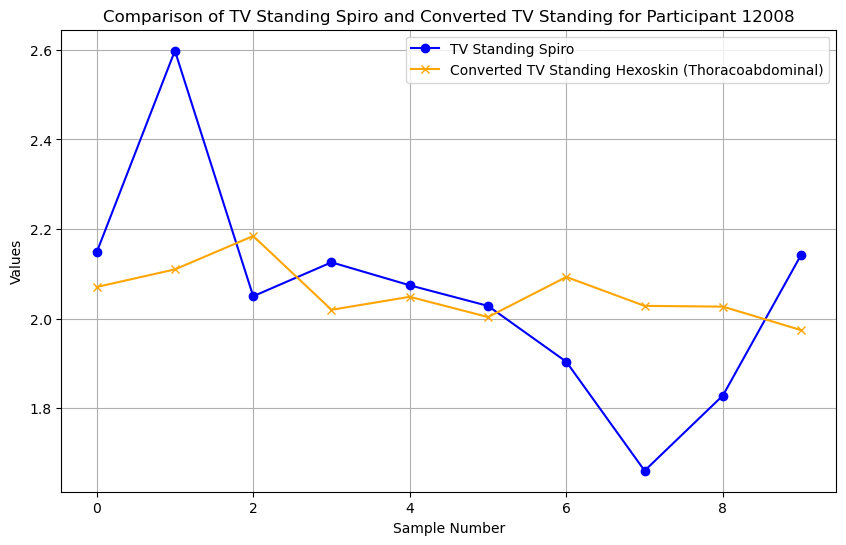

In [252]:
# applying the calculated conversion slope and intercept to the impedance amplitude values
tv_standing_hexoskin_converted = (hexoskin_thorax_depths_standing * twodegrees_slope_thorax_standing) + (hexoskin_abdomen_depths_standing * twodegrees_slope_abdomen_standing) + twodegrees_intercept_standing

plt.figure(figsize=(10, 6))

# plot the actual tidal volumes obtained via spirometer
plt.plot(tv_standing_spiro, label='TV Standing Spiro', color='blue', marker='o')

# plot the calibrated impedance volumes
plt.plot(tv_standing_hexoskin_converted, label='Converted TV Standing Hexoskin (Thoracoabdominal)', color='orange', marker='x')

plt.title(f'Comparison of TV Standing Spiro and Converted TV Standing for Participant {ppid}')
plt.xlabel('Sample Number')
plt.ylabel('Values')
plt.legend() 
plt.grid()   
plt.show()

In [253]:
y = tv_standing_spiro  # spirometer volumes

# calculate mean absolute percentage error (MAPE) for the supine spirometer calibration
twodegrees_mape_standing = np.mean(np.abs((y - tv_standing_hexoskin_converted) / (y))) * 100
print(f"mean absolute percentage error (MAPE): {twodegrees_mape_standing:.4f}%") #to be saved at the end of the script

mean absolute percentage error (MAPE): 8.7235%


In [254]:
#calculate the root mean squared errors (RMSE) for the thoracoabdominal standing calibration
# calculate squared errors

actual = tv_standing_spiro
predicted = tv_standing_hexoskin_converted

squared_errors = (actual - predicted) ** 2

# find the mean of squared errors
mse = np.mean(squared_errors)

# take the square root to get RMSE
rmse = np.sqrt(mse)

twodegrees_rmse_standing = rmse
print("Root Mean Squared Error:", twodegrees_rmse_standing)

Root Mean Squared Error: 0.22673657936139135


In [255]:
#Also calculating a regression for calibrating the Hexoskin abdomen only to spirometer (won't be used in the main analysis but good to have)

#THIS IS FOR RIP - ABDOMEN ONLY CALIBRATION, NOT THE THORACOABDOMINAL CALIBRATION!!
#specifically, we use the Moore-Penrose pseudoinverse way of solving for the regression coefficients - using the ordinary least squares formula
#under statsmodels give the same answers
import numpy as np

# ensure that the data sets have the same length
assert len(hexoskin_abdomen_depths_standing) == len(tv_standing_spiro)
print(hexoskin_abdomen_depths_standing)
X = hexoskin_abdomen_depths_standing[:, np.newaxis]  # convert impedance to a 2D array, necessary for linear regression in matrix format
print(X)
y = tv_standing_spiro  # spirometer volumes
print(y)

# add a columns of ones to include an intercept in the regression
X = np.column_stack((np.ones(len(hexoskin_abdomen_depths_standing)), X))  # Augment X with a column of ones
print(X)

# calculate the pseudoinverse of the matrix X
X_pinv = np.linalg.pinv(X)

# multiply the pseudoinverse of X with the outcome variable y to calculate the slope and intercept
conversion_coefficients_standing = np.dot(X_pinv, y) #dot product function for matrix multiplication
print(conversion_coefficients_standing)

# print the conversion coefficients
hexoskin_abdomen_intercept_standing, hexoskin_abdomen_slope_standing = conversion_coefficients_standing  #to be saved at the end  of the document
print(f"Conversion coefficients: Intercept = {hexoskin_abdomen_intercept_standing}, Slope = {hexoskin_abdomen_slope_standing}")


[42.34629886 44.48337263 53.79494177 50.2668109  51.21436216 53.29261165
 49.76386574 41.48242151 53.11484646 56.48568042]
[[42.34629886]
 [44.48337263]
 [53.79494177]
 [50.2668109 ]
 [51.21436216]
 [53.29261165]
 [49.76386574]
 [41.48242151]
 [53.11484646]
 [56.48568042]]
[2.14765981 2.59810108 2.04987985 2.12560338 2.07429475 2.02826924
 1.90354675 1.66025174 1.82820472 2.14254895]
[[ 1.         42.34629886]
 [ 1.         44.48337263]
 [ 1.         53.79494177]
 [ 1.         50.2668109 ]
 [ 1.         51.21436216]
 [ 1.         53.29261165]
 [ 1.         49.76386574]
 [ 1.         41.48242151]
 [ 1.         53.11484646]
 [ 1.         56.48568042]]
[ 2.16139184e+00 -2.12708976e-03]
Conversion coefficients: Intercept = 2.1613918367777925, Slope = -0.002127089757337216


In [256]:
import statsmodels.api as sm 
import pandas as pd          
import matplotlib.pyplot as plt 
import numpy as np
# cross-checking to see if we get the same parameters with the ordinary least squares function
x = hexoskin_abdomen_depths_standing
y = tv_standing_spiro
x = sm.add_constant(x)
result = sm.OLS(y, x).fit()
print(result.summary()) #checked, we do get the same findings

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.002
Model:                            OLS   Adj. R-squared:                 -0.123
Method:                 Least Squares   F-statistic:                   0.01582
Date:                Thu, 16 Apr 2026   Prob (F-statistic):              0.903
Time:                        12:07:57   Log-Likelihood:                0.34537
No. Observations:                  10   AIC:                             3.309
Df Residuals:                       8   BIC:                             3.914
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          2.1614      0.843      2.563      0.0

C:\Users\msa583\AppData\Local\anaconda3\Lib\site-packages\scipy\stats\_axis_nan_policy.py:531: UserWarning: kurtosistest only valid for n>=20 ... continuing anyway, n=10
  res = hypotest_fun_out(*samples, **kwds)


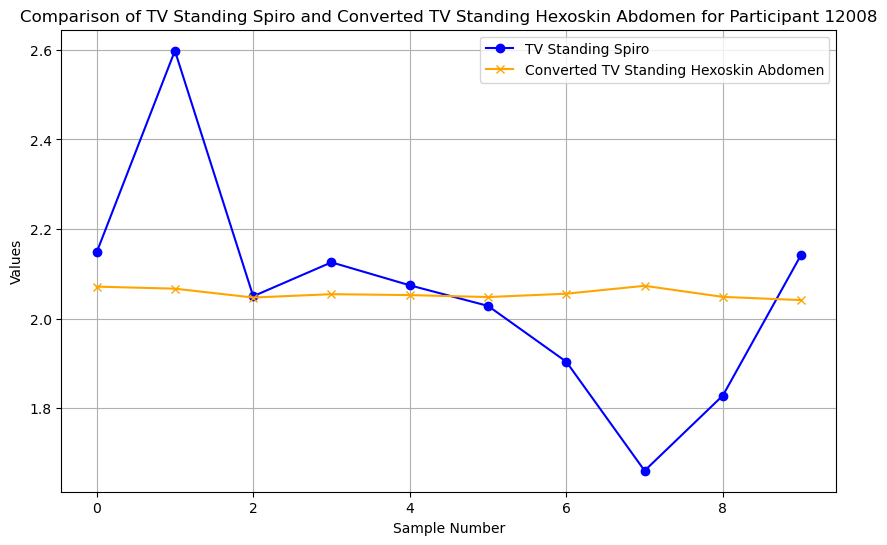

In [257]:
# applying the calculated conversion slope and intercept to the hexoskin abdomen amplitude values
tv_standing_hexoskin_abdomen_converted = (hexoskin_abdomen_depths_standing * hexoskin_abdomen_slope_standing) + hexoskin_abdomen_intercept_standing

plt.figure(figsize=(10, 6))

# plot the actual tidal volumes obtained via spirometer
plt.plot(tv_standing_spiro, label='TV Standing Spiro', color='blue', marker='o')

# plot the calibrated impedance volumes
plt.plot(tv_standing_hexoskin_abdomen_converted, label='Converted TV Standing Hexoskin Abdomen', color='orange', marker='x')

plt.title(f'Comparison of TV Standing Spiro and Converted TV Standing Hexoskin Abdomen for Participant {ppid}')
plt.xlabel('Sample Number')
plt.ylabel('Values')
plt.legend() 
plt.grid()   
plt.show()

In [258]:
y = tv_standing_spiro  # spirometer volumes

# calculate mean absolute percentage error (MAPE) for the supine spirometer calibration
hexoskin_abdomen_mape_standing = np.mean(np.abs((y - tv_standing_hexoskin_abdomen_converted) / (y))) * 100
print(f"mean absolute percentage error (MAPE): {hexoskin_abdomen_mape_standing:.4f}%") #to be saved at the end of the script

mean absolute percentage error (MAPE): 7.9149%


In [259]:
#calculate the root mean squared errors (RMSE) for the impedance supine calibration
# calculate squared errors
actual = tv_standing_spiro
predicted = tv_standing_hexoskin_abdomen_converted

squared_errors = (actual - predicted) ** 2

# find the mean of squared errors
mse = np.mean(squared_errors)

# take the square root to get RMSE
rmse = np.sqrt(mse)

hexoskin_abdomen_rmse_standing = rmse
print("Root Mean Squared Error:", hexoskin_abdomen_rmse_standing)

Root Mean Squared Error: 0.23375637287018797


# SAVING ALL IMPORTANT REGRESSION PARAMETERS AND STATISTICS

In [260]:
shift

1.242188034702849

In [261]:
target_start

Timestamp('2024-09-02 10:36:53.500000')

In [262]:
import pandas as pd

starting_time = "2024-09-02 10:36:53.500"   # do a manual entry - enter as YYYY-MM-DD HH:MM:SS.fff   this is the start time of the trimmed resp files

data = {
    "starting_time": [starting_time],
    "shift": [shift],
    "vuams_intercept_supine": [vuams_intercept_supine],
    "vuams_slope_supine": [vuams_slope_supine],
    "vuams_mape_supine": [vuams_mape_supine],
    "vuams_rmse_supine": [vuams_rmse_supine],

    "hexoskin_thorax_intercept_supine": [hexoskin_thorax_intercept_supine],
    "hexoskin_thorax_slope_supine": [hexoskin_thorax_slope_supine],
    "hexoskin_thorax_mape_supine": [hexoskin_thorax_mape_supine],
    "hexoskin_thorax_rmse_supine": [hexoskin_thorax_rmse_supine],

    "twodegrees_intercept_supine": [twodegrees_intercept_supine],
    "twodegrees_slope_thorax_supine": [twodegrees_slope_thorax_supine],
    "twodegrees_slope_abdomen_supine": [twodegrees_slope_abdomen_supine],
    "twodegrees_mape_supine": [twodegrees_mape_supine],
    "twodegrees_rmse_supine": [twodegrees_rmse_supine],

    "hexoskin_abdomen_intercept_supine": [hexoskin_abdomen_intercept_supine],
    "hexoskin_abdomen_slope_supine": [hexoskin_abdomen_slope_supine],
    "hexoskin_abdomen_mape_supine": [hexoskin_abdomen_mape_supine],
    "hexoskin_abdomen_rmse_supine": [hexoskin_abdomen_rmse_supine],

    # SITTING
    "vuams_intercept_sitting": [vuams_intercept_sitting],
    "vuams_slope_sitting": [vuams_slope_sitting],
    "vuams_mape_sitting": [vuams_mape_sitting],
    "vuams_rmse_sitting": [vuams_rmse_sitting],

    "hexoskin_thorax_intercept_sitting": [hexoskin_thorax_intercept_sitting],
    "hexoskin_thorax_slope_sitting": [hexoskin_thorax_slope_sitting],
    "hexoskin_thorax_mape_sitting": [hexoskin_thorax_mape_sitting],
    "hexoskin_thorax_rmse_sitting": [hexoskin_thorax_rmse_sitting],

    "twodegrees_intercept_sitting": [twodegrees_intercept_sitting],
    "twodegrees_slope_thorax_sitting": [twodegrees_slope_thorax_sitting],
    "twodegrees_slope_abdomen_sitting": [twodegrees_slope_abdomen_sitting],
    "twodegrees_mape_sitting": [twodegrees_mape_sitting],
    "twodegrees_rmse_sitting": [twodegrees_rmse_sitting],

    "hexoskin_abdomen_intercept_sitting": [hexoskin_abdomen_intercept_sitting],
    "hexoskin_abdomen_slope_sitting": [hexoskin_abdomen_slope_sitting],
    "hexoskin_abdomen_mape_sitting": [hexoskin_abdomen_mape_sitting],
    "hexoskin_abdomen_rmse_sitting": [hexoskin_abdomen_rmse_sitting],

    # STANDING
    "vuams_intercept_standing": [vuams_intercept_standing],
    "vuams_slope_standing": [vuams_slope_standing],
    "vuams_mape_standing": [vuams_mape_standing],
    "vuams_rmse_standing": [vuams_rmse_standing],

    "hexoskin_thorax_intercept_standing": [hexoskin_thorax_intercept_standing],
    "hexoskin_thorax_slope_standing": [hexoskin_thorax_slope_standing],
    "hexoskin_thorax_mape_standing": [hexoskin_thorax_mape_standing],
    "hexoskin_thorax_rmse_standing": [hexoskin_thorax_rmse_standing],

    "twodegrees_intercept_standing": [twodegrees_intercept_standing],
    "twodegrees_slope_thorax_standing": [twodegrees_slope_thorax_standing],
    "twodegrees_slope_abdomen_standing": [twodegrees_slope_abdomen_standing],
    "twodegrees_mape_standing": [twodegrees_mape_standing],
    "twodegrees_rmse_standing": [twodegrees_rmse_standing],

    "hexoskin_abdomen_intercept_standing": [hexoskin_abdomen_intercept_standing],
    "hexoskin_abdomen_slope_standing": [hexoskin_abdomen_slope_standing],
    "hexoskin_abdomen_mape_standing": [hexoskin_abdomen_mape_standing],
    "hexoskin_abdomen_rmse_standing": [hexoskin_abdomen_rmse_standing],
}

df = pd.DataFrame(data)

df.to_excel(f"calibration_parameters_{ppid}.xlsx", index=False)